# Cross-model distillation: student-hyperparameter exploration — results

Documents the July 21–24 2026 **student-HP exploration for cross-initialization (cross-model) distillation** of the dog trait: the teacher is the original `pythia-160m` (tseed1, `ex10-20_prefix_n100k` numbers), students are the PolyPythia re-seeds `data-seed1` / `weight-seed2` (§10 adds `weight-seed1`), and — unlike the cross-seed notebook, which fixes the student recipe — here the **student hyperparameters are the treatment**. Motivating question: cross-init transfer at the standard student recipe is weak (~0.02–0.15 test p(target) at ep20). Can a stronger student surface more of it?

**The experiment ladder** (each stage decided from the previous one's results; job lists in `run_logs/dog_crossdistill_studenthp_*_jobs.txt`, `run_logs/dog_studenthp_ds1_*_jobs.txt` and `run_logs/hp_t*_jobs.txt`, workers/launchers `run_logs/dog_crossdistill_studenthp_{worker.py,launcher.sh}`):

1. **Variant probe** (36 jobs, ep20): top-6 teacher configs by cross-init transfer × both cross bases × {lr 5e-4 · r8α32, lr 1e-4 · r16α64, lr 5e-4 · r16α64}.
2. **Dose check** (24 + 2 jobs): the two single-change variants at ep10; then lr 5e-4 at ep5 for the strongest config.
3. **Neighborhood grid** (33 jobs, focus cell `ep2_lr5e-4_r32a64 → data-seed1`): lr {1e-4, 2e-4, 3e-4} × LoRA {r8α32, r16α32, r8α64} × ep {5, 10, 20}, plus first seed replicates.
4. **Frontier at 3 seeds** (24 jobs, ep20): the surviving gentle region — {r8α16, r16α16, r16α32, r32α32, r32α64, r64α64} at lr 1e-4 and {r8α32, r16α32, r32α32} at lr 5e-5.
5. **ep40 dose rung** (6 jobs): winner (r16α32) and baseline (r8α32) × seeds 1–3.
6. **lr × α control** (21 + 3 jobs, 3 seeds; §8): lr 2e-4 at *small* α {r8α8, r8α16, r16α16} × {ep5, ep20}, plus the r8α64 lr-rescue (lr 5e-4 vs 5e-5) — breaks the lr-2e-4 / α confound.
7. **Cross-teacher menu replication** (7 × 30 jobs, 3 seeds; §10): the std recipe + the four §8 gentle recipes × {ep5, ep20} on seven more teacher lineages across three bases, incl. the new base `weight-seed1` (`run_logs/hp_t{2..8}_*_jobs.txt`).
8. **hp-focus scale sweep + `law-exp` add-ons** (§11–§13): the (lr, α, rank) grid on the focus lineage filled to **131 ep20 cells / 638 seed-runs** (rank 1–64, α 1–512) — the grid the collapse law is fitted on.
9. **top3hp-grid campaign** (§14; launched 2026-07-26, drained + cross reseed 2026-07-28): the focus top-3 student HPs × 102 teachers × {same-model, cross ds1} at ep20.

**Headline findings** (final state 2026-07-28; the sections keep the intermediate readings under dated supersession banners): the student aggression knobs collapse to **one scalar** — a cell collapses when **`lr·α^0.58·r^-0.09`** crosses a critical value (§12). The earlier forms — "lr ≥ 2e-4 is an absolute dead zone" (stages 1–3), `lr×α` (§8), the rank-free `lr·√α` (§11) — were successive approximations and are superseded; **rank is in the law and higher rank is protective**. Transfer peaks just below the cliff: the exploration's top cell is `lr4e-4 r32α4` = **0.256** (5-seed mean), ≈2.5× the standard recipe, and §13 turns "how close to fly" into an explicit EV argmax. The law generalises across six teacher/student arms (`collapse_law_generality.ipynb`: pooled b = 0.561, c = −0.085, K* spread 1.4×). But no student recipe beats std beyond noise off the focus lineage — neither the gentle §8 menu (§10: best gain +0.017 over seven lineages) nor the aggressive top-3 (§14: paired Δ ≈ 0 across 102 teachers) — so **student-HP choice is not the binding constraint on cross-init transfer; the teacher lineage is**. Dose (epochs) reliably pays (ep20 ≫ ep5), and seed spread on live cells is large (±0.06): only replicated contrasts count.

> **Live notebook.** Sections self-filter to artifacts present on disk. Single-seed cells carry no uncertainty; seed-replicated cells show per-seed points. §2/§3/§5/§9 (the stage-1–2 variant scatters, the confounded lr-cliff ladder, the lr-1e-4 dose-response view, and the probe-teacher cut) were removed 2026-07-28 as superseded; the surviving section numbers are unchanged.


## Setup and per-seed artifact loader

Loads every student cell under the six top teacher lineages × both cross bases (plain `ex10-20_prefix_n100k` template): the seed-averaged `preference_summary.json` per cell **and** each `ftseed{N}/preference_eval.json` for per-seed test values — seed spread is a first-class object here. `runs` = one row per (cell, seed); `cells` = one row per cell with mean + seed tuple.

In [ ]:
from __future__ import annotations
import json, re
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from subliminal_learning.analysis.setup import bootstrap, set_plot_style

ROOT, OUTPUT_ROOT = bootstrap()
STUDENTS_ROOT = OUTPUT_ROOT / "students"

ANIMAL, NBASE, TSEED, DATASET = "dog", "pythia-160m", 1, "ex10-20_prefix_n100k"
BASES = ["pythia-160m-data-seed1", "pythia-160m-weight-seed2"]
BASE_LABEL = {"pythia-160m-data-seed1": "data-seed1", "pythia-160m-weight-seed2": "weight-seed2"}
# The exploration's focus cell: the teacher config x student base with the strongest baseline transfer.
FOCUS_TEACHER, FOCUS_BASE = "ep2_lr5e-4_r32a64", "pythia-160m-data-seed1"
BASELINE_LR, BASELINE_LORA = 1e-4, (8, 32)   # the standard student recipe (Blank et al. port)

# Top-6 teacher tags by mean cross-init test at student ep20 (the variant-probe manifest, kept in run_logs).
TOP6_MANIFEST = ROOT / "run_logs/dog_crossdistill_top6_configs.json"
TOP6 = list(json.loads(TOP6_MANIFEST.read_text())["param_tags"]) if TOP6_MANIFEST.exists() else []
assert TOP6, "top-6 manifest missing"

STUDENT_TAG_RE = re.compile(r"^ep(?P<ep>\d+)_lr(?P<lr>[^_]+)_r(?P<r>\d+)a(?P<a>\d+)$")
set_plot_style(dpi=115, hide_spines=True)
print("output_root:", OUTPUT_ROOT); print("top-6 teachers:", TOP6)

output_root: /mnt/ssd-2/soar-subliminal/angela/outputs
top-6 teachers: ['ep2_lr5e-4_r32a64', 'ep2_lr5e-4_r16a64', 'ep7_lr2e-4_r8a32', 'ep20_lr2e-4_r8a8', 'ep20_lr1e-4_r32a32', 'ep20_lr1e-4_r8a32']


In [134]:
def read(p): return json.loads(Path(p).read_text())

def load():
    run_rows, cell_rows = [], []
    for base in BASES:
        for tag in TOP6:
            lin = STUDENTS_ROOT / ANIMAL / base / f"teacher-{NBASE}" / f"{tag}_tseed{TSEED}" / DATASET
            if not lin.exists(): continue
            for cd in sorted(lin.iterdir()):
                m = STUDENT_TAG_RE.fullmatch(cd.name)
                if not m or not (cd / "preference_summary.json").exists(): continue
                doc = read(cd / "preference_summary.json")
                mean_test = next((s["p_target_mean"] for s in doc.get("summaries", [])
                                  if s["prompt_set"] == "test"), None)
                seeds = {}
                for fd in sorted(cd.glob("ftseed*/preference_eval.json")):
                    n = int(re.search(r"ftseed(\d+)", str(fd))[1])
                    t = read(fd).get("sets", {}).get("test", {}).get("p_target")
                    if t is not None: seeds[n] = t
                meta = dict(teacher_tag=tag, base=base, student_tag=cd.name,
                            ep=int(m["ep"]), lr=float(m["lr"]), rank=int(m["r"]), alpha=int(m["a"]),
                            scale=int(m["a"]) / int(m["r"]))
                cell_rows.append({**meta, "mean_test": mean_test, "n_seeds": len(seeds),
                                  "seed_min": min(seeds.values(), default=np.nan),
                                  "seed_max": max(seeds.values(), default=np.nan)})
                for n, t in seeds.items(): run_rows.append({**meta, "seed": n, "test": t})
    return pd.DataFrame(cell_rows), pd.DataFrame(run_rows)

cells_df, runs = load()
assert len(cells_df), "no student cells found"
cells_df["is_baseline_hp"] = cells_df.lr.eq(BASELINE_LR) & cells_df["rank"].eq(BASELINE_LORA[0]) & cells_df.alpha.eq(BASELINE_LORA[1])
runs["is_baseline_hp"] = runs.lr.eq(BASELINE_LR) & runs["rank"].eq(BASELINE_LORA[0]) & runs.alpha.eq(BASELINE_LORA[1])
focus = cells_df[cells_df.teacher_tag.eq(FOCUS_TEACHER) & cells_df.base.eq(FOCUS_BASE)].copy()
focus_runs = runs[runs.teacher_tag.eq(FOCUS_TEACHER) & runs.base.eq(FOCUS_BASE)].copy()
print(f"{len(cells_df)} cells / {len(runs)} seed-runs across {cells_df.teacher_tag.nunique()} teachers x {cells_df.base.nunique()} bases")
print(f"focus cell ({FOCUS_TEACHER} -> {BASE_LABEL[FOCUS_BASE]}): {len(focus)} cells / {len(focus_runs)} seed-runs")

333 cells / 988 seed-runs across 6 teachers x 3 bases
focus cell (ep2_lr5e-4_r32a64 -> data-seed1): 173 cells / 739 seed-runs


In [135]:
# Menu-sweep loader (used by the per-teacher grids at the end of §8 and by §10). The hp_t{2..8}
# cross-teacher sweeps step outside the frame above — five of the seven teacher tags are not in
# TOP6, and three lineages land on weight-seed1, a base not in BASES — so they get their own
# small frame. Menu = std recipe + the four §8 gentle recipes (all lr×α ≤ 3.2e-3), {ep5, ep20} × 3 seeds.
MENU_SWEEPS = [  # (teacher_tag, base); first = the §4–§8 focus lineage, loaded for reference
    ("ep2_lr5e-4_r32a64", "pythia-160m-data-seed1"),
    ("ep2_lr5e-4_r16a64", "pythia-160m-data-seed1"),
    ("ep7_lr1e-4_r16a32", "pythia-160m-data-seed1"),
    ("ep2_lr5e-4_r64a64", "pythia-160m-weight-seed1"),
    ("ep5_lr5e-4_r8a16", "pythia-160m-weight-seed1"),
    ("ep7_lr2e-4_r8a8", "pythia-160m-weight-seed1"),
    ("ep20_lr1e-4_r32a32", "pythia-160m-weight-seed2"),
    ("ep5_lr5e-4_r16a16", "pythia-160m-weight-seed2"),
]
BASE_LABEL_ALL = {**BASE_LABEL, "pythia-160m-weight-seed1": "weight-seed1"}
RECIPES = [  # (lr string, rank, α, display label) — std first, then the §8 gentle menu
    ("1e-4", 8, 32, "std r8α32@1e-4"),
    ("2e-4", 8, 8, "r8α8@2e-4"),
    ("2e-4", 8, 16, "r8α16@2e-4"),
    ("1e-4", 16, 32, "r16α32@1e-4"),
    ("5e-5", 8, 64, "r8α64@5e-5"),
]
RECIPE_ORDER = [lab for *_, lab in RECIPES]
LINEAGES = [f"{t} → {BASE_LABEL_ALL[b]}" for t, b in MENU_SWEEPS]

def load_menu():
    crows, rrows = [], []
    for tag, base in MENU_SWEEPS:
        lin = STUDENTS_ROOT / ANIMAL / base / f"teacher-{NBASE}" / f"{tag}_tseed{TSEED}" / DATASET
        for ep in (5, 20):
            for lr_s, r, a, lab in RECIPES:
                cd = lin / f"ep{ep}_lr{lr_s}_r{r}a{a}"
                if not (cd / "preference_summary.json").exists(): continue
                doc = read(cd / "preference_summary.json")
                mt = next((s["p_target_mean"] for s in doc.get("summaries", [])
                           if s["prompt_set"] == "test"), None)
                seeds = {}
                for fd in sorted(cd.glob("ftseed*/preference_eval.json")):
                    t = read(fd).get("sets", {}).get("test", {}).get("p_target")
                    if t is not None: seeds[int(re.search(r"ftseed(\d+)", str(fd))[1])] = t
                meta = dict(teacher_tag=tag, base=base, lineage=f"{tag} → {BASE_LABEL_ALL[base]}",
                            is_focus=(tag == FOCUS_TEACHER and base == FOCUS_BASE),
                            ep=ep, recipe=lab, lr=float(lr_s), rank=r, alpha=a, lr_alpha=float(lr_s) * a)
                crows.append({**meta, "mean_test": mt, "n_seeds": len(seeds),
                              "seed_min": min(seeds.values(), default=np.nan),
                              "seed_max": max(seeds.values(), default=np.nan)})
                for n, t in seeds.items(): rrows.append({**meta, "seed": n, "test": t})
    return pd.DataFrame(crows), pd.DataFrame(rrows)

menu_cells, menu_runs = load_menu()
new7 = menu_cells[~menu_cells.is_focus]
assert new7.lineage.nunique() == 7, "expected the seven hp_t{2..8} sweeps on disk"
print(f"menu cells: {len(menu_cells)} ({len(new7)}/70 new + {len(menu_cells) - len(new7)} focus) / "
      f"{len(menu_runs)} seed-runs; under-seeded new cells: {len(new7[new7.n_seeds < 3])}")


menu cells: 79 (70/70 new + 9 focus) / 245 seed-runs; under-seeded new cells: 0


## 1. Inventory

One row per (teacher, base): which student cells exist at which doses, and how many carry seed replicates. The focus lineage holds the deep grid; the other eleven (teacher × base) lineages carry the baseline ladder plus the stage-1/2 variants.

In [136]:
inv = cells_df.assign(hp=cells_df.student_tag.str.replace(r"^ep\d+_", "", regex=True))
cov = inv.pivot_table(index=["teacher_tag", "base"], columns="ep", values="student_tag", aggfunc="size").fillna(0).astype(int)
cov.index = [(t, BASE_LABEL[b]) for t, b in cov.index]
cov.columns = [f"ep{c}" for c in cov.columns]
display(cov.style.set_caption("Student cells per (teacher, base) x distillation epochs"))
seeded = cells_df[cells_df.n_seeds > 1][["teacher_tag", "base", "student_tag", "n_seeds", "mean_test", "seed_min", "seed_max"]]
seeded = seeded.assign(base=seeded.base.map(BASE_LABEL)).sort_values(["teacher_tag", "student_tag"])
display(seeded.style.format({c: "{:.3f}" for c in ["mean_test", "seed_min", "seed_max"]})
        .set_caption("Seed-replicated cells (n_seeds > 1)").hide(axis="index"))

KeyError: 'pythia-160m-weight-seed1'

## 4. LoRA scale vs capacity (focus cell, lr 1e-4)

Each point is one (rank, α) cell at lr 1e-4, x = effective scale α/r, size = rank, one panel per dose. Scale is the second aggression knob and behaves like lr: scale 8 (r8α64) dies by ep20 exactly like 2× lr does. Within the surviving region (scale ≤ 4), **capacity helps at gentle scale** — r16α32 (scale 2) posted the best single-seed cell at ep20 (0.168, but mean 0.099 over 3 seeds — within noise of baseline) — while the same capacity at scale 4 (r16α64) sits below baseline. The frontier cells (r16α16, r32α32, r32α64, r64α64, r8α16) have landed and appear in these panels.

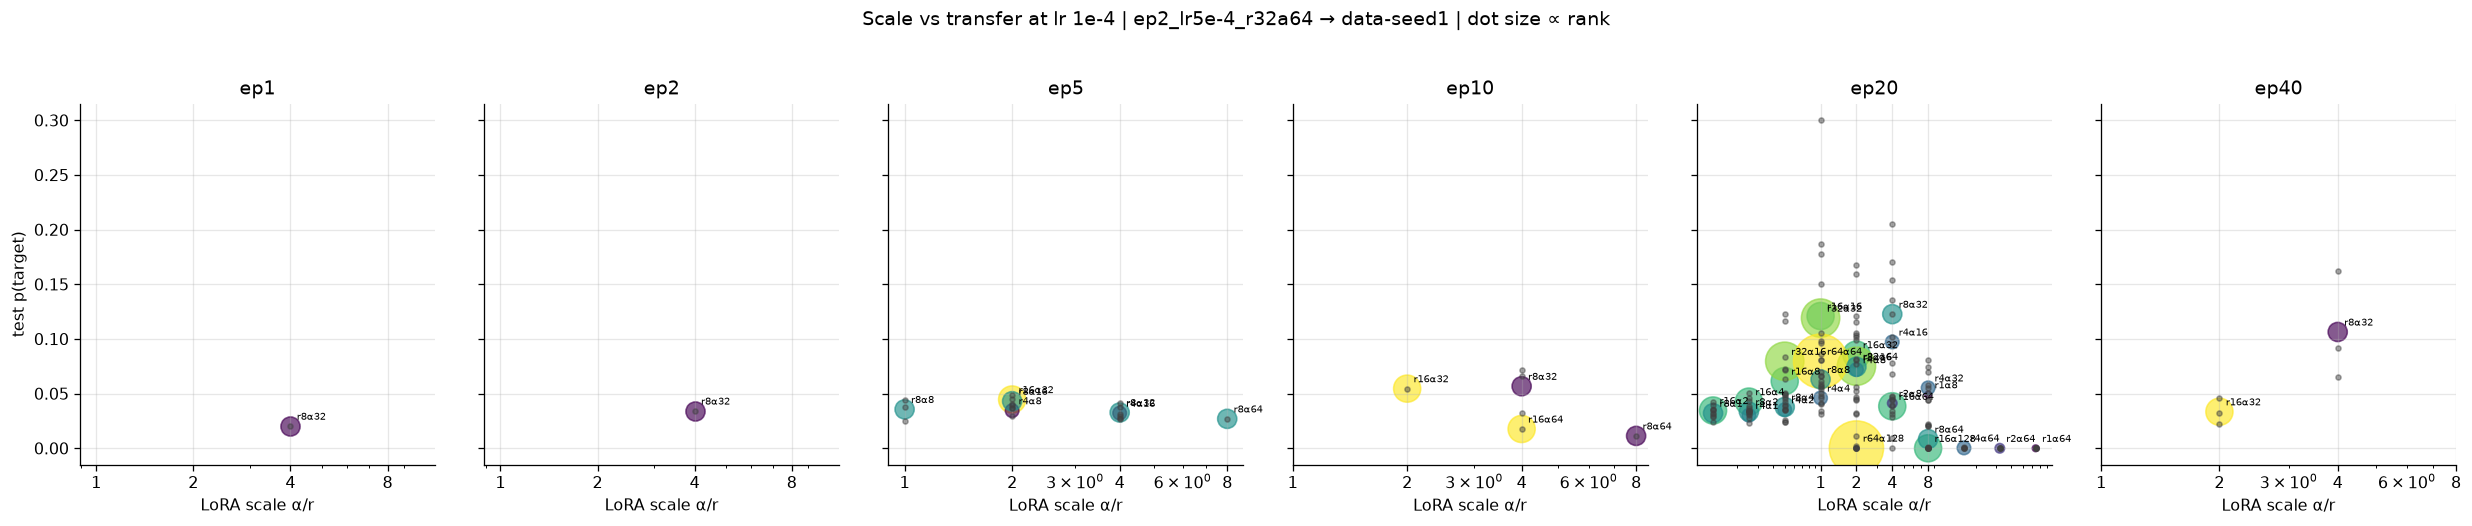

In [ ]:
g1 = focus[focus.lr.eq(1e-4)]
eps = sorted(g1.ep.unique())
fig, axs = plt.subplots(1, len(eps), figsize=(3.6 * len(eps), 4.4), sharey=True, squeeze=False)
for ax, ep in zip(axs[0], eps):
    sub = g1[g1.ep.eq(ep)]
    sc = ax.scatter(sub.scale, sub.mean_test, s=18 * sub["rank"], alpha=.65,
                    c=np.log2(sub["rank"]), cmap="viridis")
    rr = focus_runs[focus_runs.lr.eq(1e-4) & focus_runs.ep.eq(ep)]
    ax.scatter(rr.scale, rr.test, s=10, color=".25", alpha=.45, zorder=3)
    for _, row in sub.iterrows():
        ax.annotate(f"r{row['rank']}α{row.alpha}", (row.scale, row.mean_test),
                    textcoords="offset points", xytext=(4, 4), fontsize=6.5)
    ax.set(xscale="log", title=f"ep{ep}", xlabel="LoRA scale α/r", xticks=[1, 2, 4, 8],
           xticklabels=["1", "2", "4", "8"])
axs[0][0].set_ylabel("test p(target)")
fig.suptitle(f"Scale vs transfer at lr 1e-4 | {FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]} | dot size ∝ rank", y=1.03)
plt.tight_layout(); plt.show()

## 6. Seed noise vs signal

Every replicated **ep20** cell in one view (ep20 is the dose every conclusion rests on; the ep5/ep10 replicates are excluded so the noise estimate matches the cells being compared). **Left:** within-cell seed SD against the cell mean, one dot per replicated cell, encoded by HP family — **colour = student lr** (the same viridis lr mapping used throughout), **marker = LoRA rank**, **faded = collapsed cells** (mean ≤ 0.005). Noise grows with signal, collapsed cells replicate at ≈0 with ≈0 SD (the cliff is signal, not noise), and the pooled SD over live cells sets the resolution rule used throughout: single-seed contrasts under ~2× pooled SD are not interpretable. **Right:** only the top replicated ep20 cells, as per-seed strips, dots coloured by the same lr mapping — the whole top of the leaderboard overlaps within seed noise, which is why winner claims lean on *reliability* (all seeds off zero) rather than the mean alone.


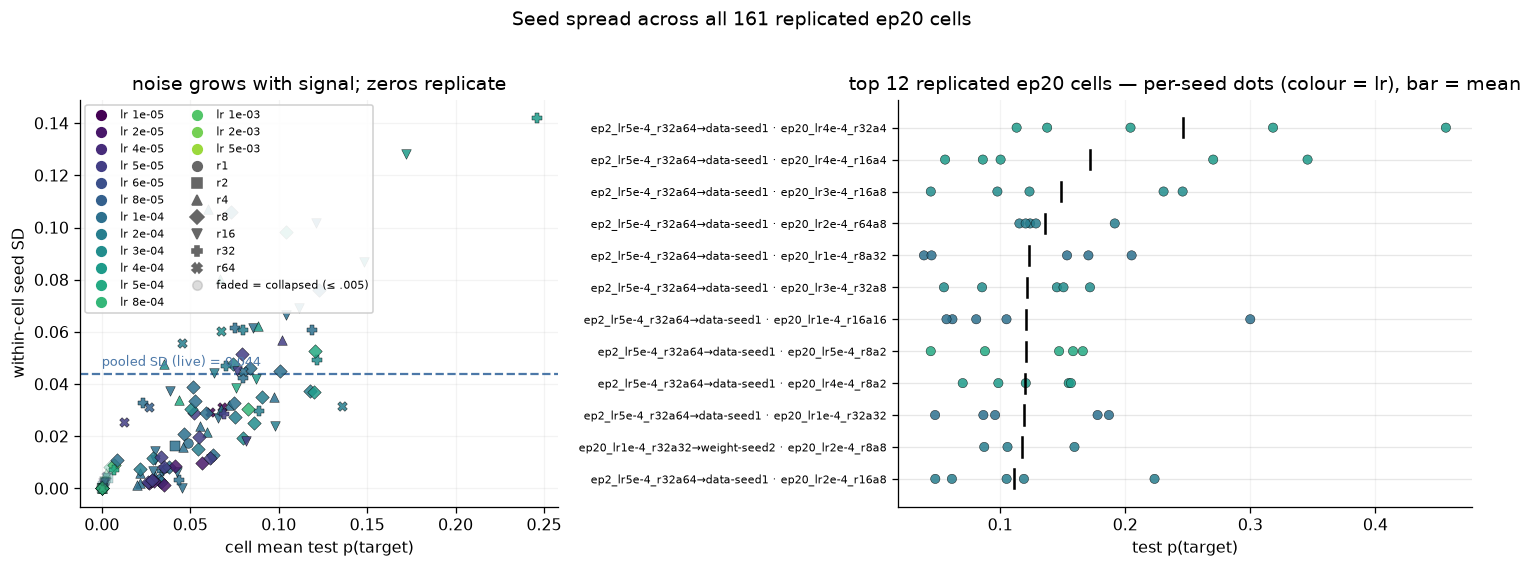

pooled within-cell seed SD over live ep20 cells (mean > 0.005): 0.044 -> single-seed contrasts under ~±0.09 are noise


In [ ]:
# Seed noise vs signal at ep20 (the dose every conclusion rests on), two cuts. Left: within-cell
# seed SD vs cell mean for every replicated ep20 cell — colour = student lr, marker = LoRA rank,
# faded = collapsed (mean <= 0.005). Right: per-seed strips for the top replicated ep20 cells,
# dots coloured by the same lr mapping.
from matplotlib.lines import Line2D

rep = cells_df[(cells_df.n_seeds > 1) & cells_df.ep.eq(20)].copy()
if len(rep):
    rep_runs = runs.merge(rep[["teacher_tag", "base", "student_tag"]].drop_duplicates())
    st = rep_runs.groupby(["teacher_tag", "base", "student_tag", "lr", "rank", "alpha"]) \
                 .test.agg(["mean", "std", "count"]).reset_index()
    nz = st[st["mean"] > .005]
    pooled = float(np.sqrt((nz["std"] ** 2).mean()))

    lrs6 = sorted(st.lr.unique())
    lrcol6 = {lr: c for lr, c in zip(lrs6, plt.cm.viridis(np.linspace(0, .85, len(lrs6))))}
    ranks6 = sorted(st["rank"].unique())
    rankmark6 = {r: m for r, m in zip(ranks6, ["o", "s", "^", "D", "v", "P", "X", "*"])}

    NTOP = 12
    fig, (axl, axr) = plt.subplots(1, 2, figsize=(13, 4.8), width_ratios=[1, 1.2])
    for t in st.itertuples():
        dead = t.mean <= .005
        axl.scatter(t.mean, t.std, s=36, color=lrcol6[t.lr], marker=rankmark6[t.rank],
                    alpha=.3 if dead else .85, edgecolor="k", lw=.3, zorder=3)
    axl.axhline(pooled, color="#4c78a8", lw=1.4, ls="--")
    axl.text(0.0, pooled + .002, f"pooled SD (live) = {pooled:.3f}",
             color="#4c78a8", fontsize=8, ha="left", va="bottom")
    handles = ([Line2D([], [], ls="", marker="o", color=lrcol6[lr], label=f"lr {lr:.0e}") for lr in lrs6]
               + [Line2D([], [], ls="", marker=rankmark6[r], color=".4", label=f"r{r}") for r in ranks6]
               + [Line2D([], [], ls="", marker="o", color=".55", alpha=.3,
                         label="faded = collapsed (≤ .005)")])
    axl.legend(handles=handles, fontsize=6.8, ncols=2, loc="upper left", framealpha=.9)
    axl.set(xlabel="cell mean test p(target)", ylabel="within-cell seed SD",
            title="noise grows with signal; zeros replicate")
    axl.grid(alpha=.15)

    top = rep.sort_values("mean_test", ascending=False).head(NTOP).iloc[::-1]
    for i, t in enumerate(top.itertuples()):
        rr = rep_runs[rep_runs.teacher_tag.eq(t.teacher_tag) & rep_runs.base.eq(t.base)
                      & rep_runs.student_tag.eq(t.student_tag)]
        axr.scatter(rr.test, [i] * len(rr), s=34, color=[lrcol6[v] for v in rr.lr],
                    alpha=.85, edgecolor="k", lw=.3, zorder=3)
        axr.plot([t.mean_test] * 2, [i - .3, i + .3], color="black", lw=1.6, zorder=4)
    axr.set_yticks(range(len(top)))
    axr.set_yticklabels([f"{t.teacher_tag}→{BASE_LABEL.get(t.base, t.base)} · {t.student_tag}"
                         for t in top.itertuples()], fontsize=7)
    axr.set(xlabel="test p(target)",
            title=f"top {NTOP} replicated ep20 cells — per-seed dots (colour = lr), bar = mean")
    axr.grid(axis="x", alpha=.15)
    fig.suptitle(f"Seed spread across all {len(st)} replicated ep20 cells", y=1.02)
    plt.tight_layout(); plt.show()
    print(f"pooled within-cell seed SD over live ep20 cells (mean > 0.005): {pooled:.3f} "
          f"-> single-seed contrasts under ~±{2 * pooled:.2f} are noise")
else:
    print("no seed-replicated ep20 cells on disk yet")


## 7. The whole exploration, lineage by lineage

One figure per teacher lineage (teacher config → student base), displayed one after another — the focus lineage first, then the remaining TOP6 × {data-seed1, weight-seed2} lineages. Each figure is the standard HP-sweep layout used throughout these notebooks (`analysis.plots.facet_grid_heatmaps`, the same design as §8's focus grids): within each panel rows = distillation epochs and columns = LoRA rank/α, with one panel per student lr across the row (left→right = increasing lr). **Every HP coordinate the lineage was run on is shown**, and panel width scales with each lineage's own LoRA-column count so cell labels stay readable. Cell value = mean test p(target) over ft seeds; the `n{K}` suffix states how many seeds that mean averages (`n1` = single run, no uncertainty). Red box = the standard recipe (r8α32, lr 1e-4) at ep20. Colour scale capped at 0.2 — cross-init transfer tops out ~0.17, so a 0–1 scale would render everything dark.

Reading the focus figure left→right as increasing lr: lr 5e-4 is dead everywhere while lr 2e-4 is alive at low α — the §8 confound-break as territory. Across the other lineages the std-recipe cell sits at-or-near each lineage's best, previewing §10's conclusion that no student recipe beats it beyond noise.




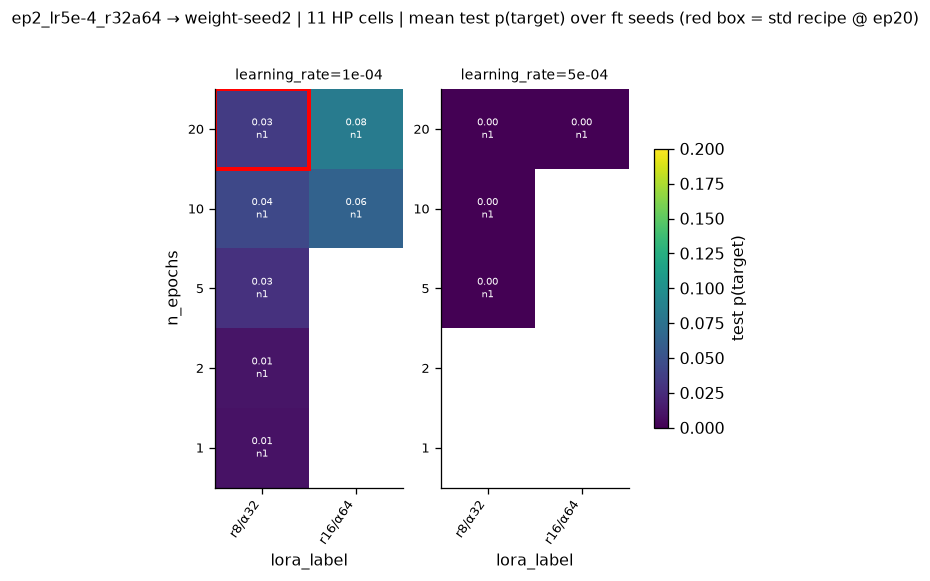

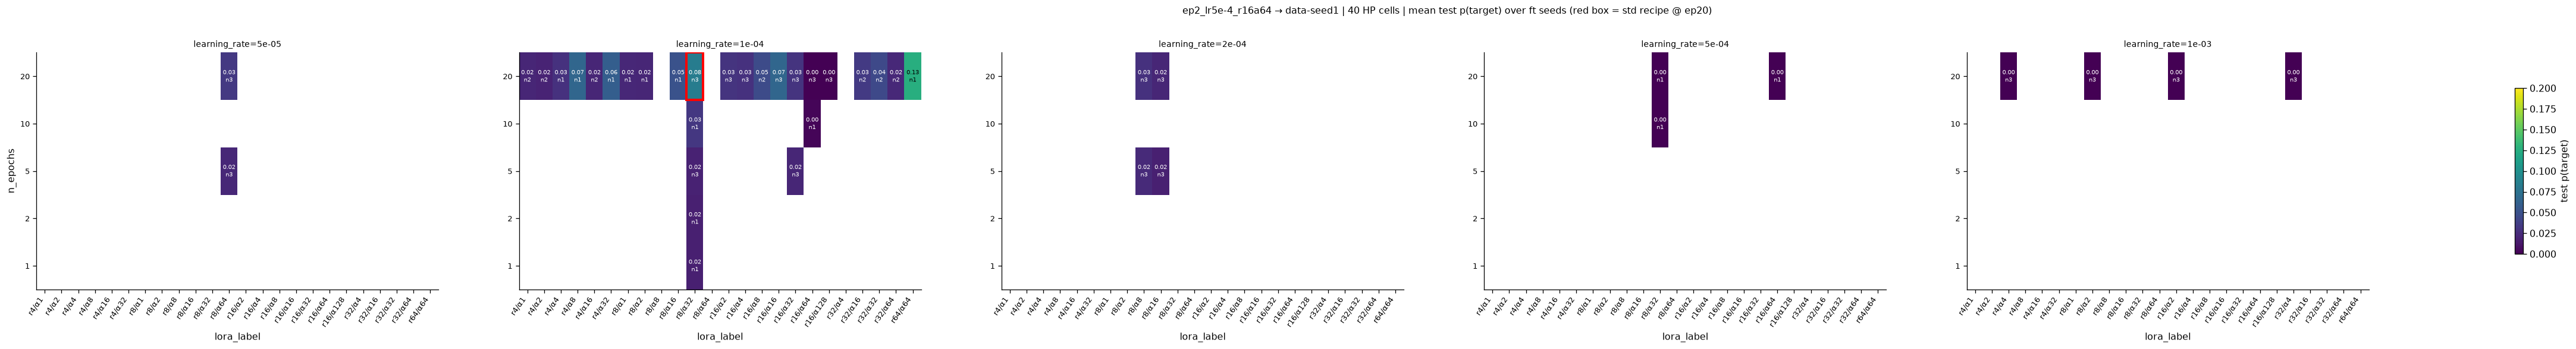

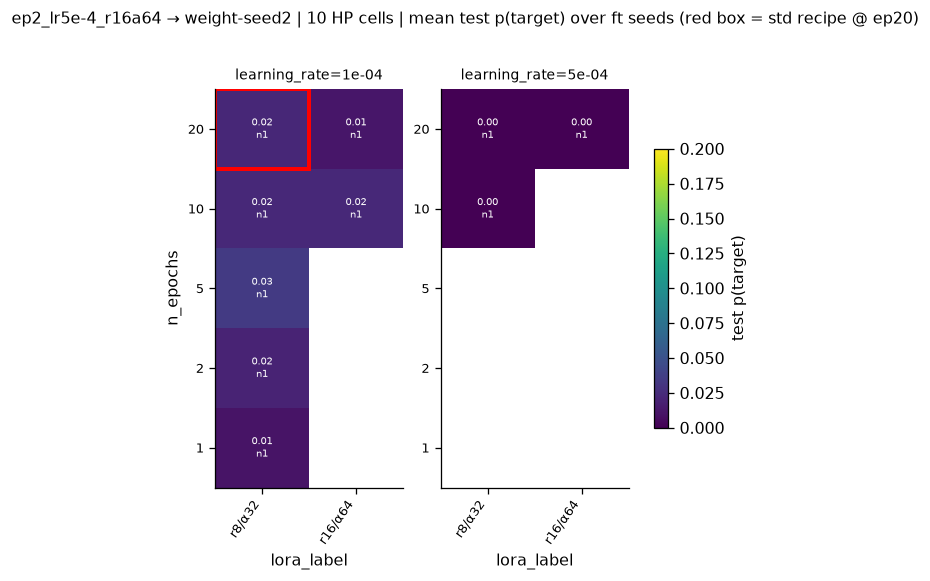

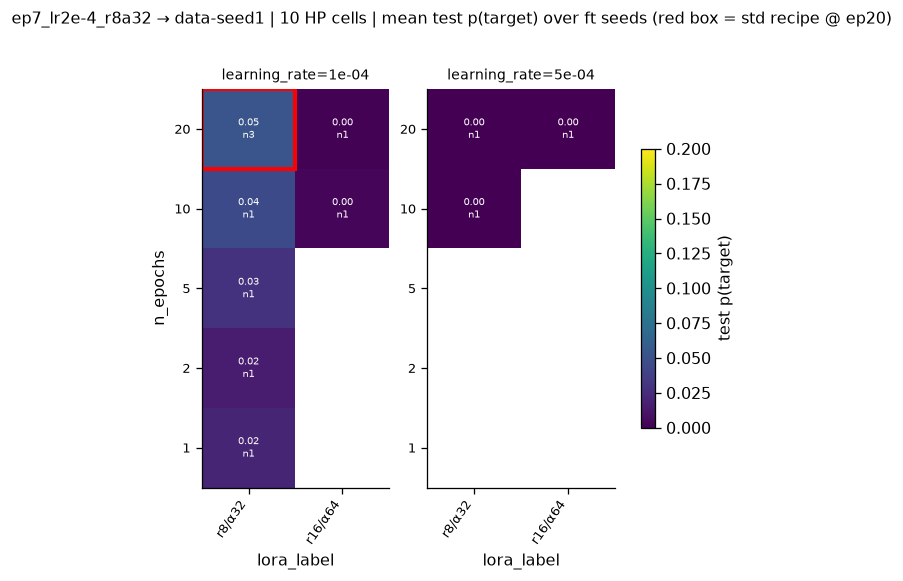

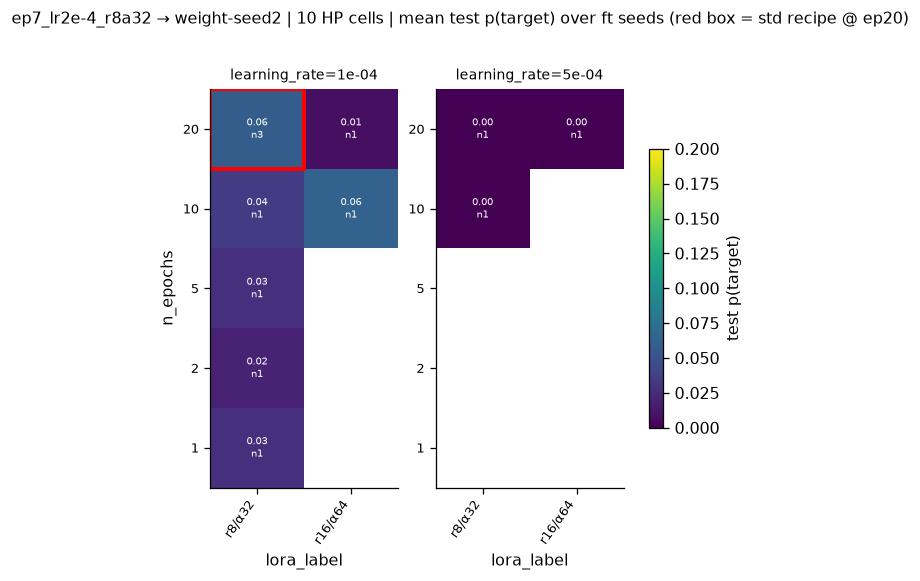

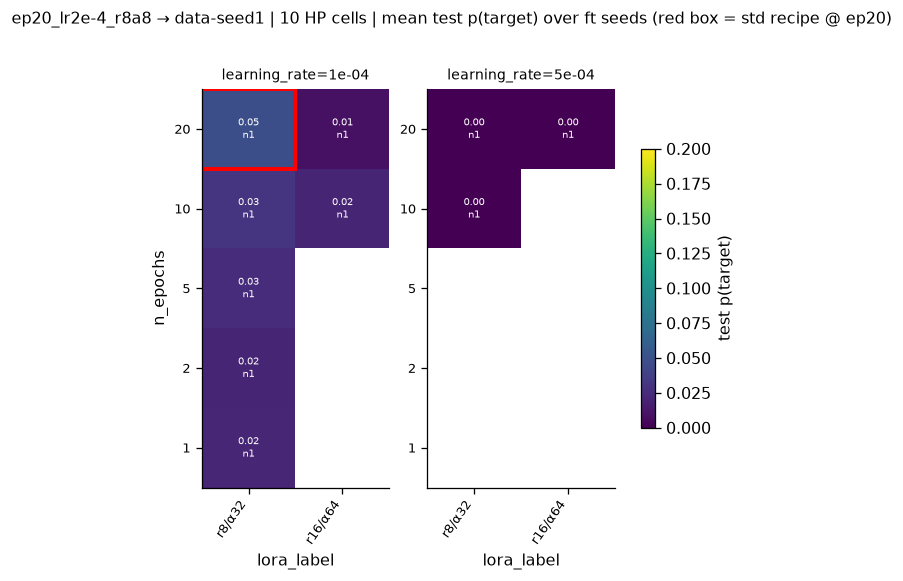

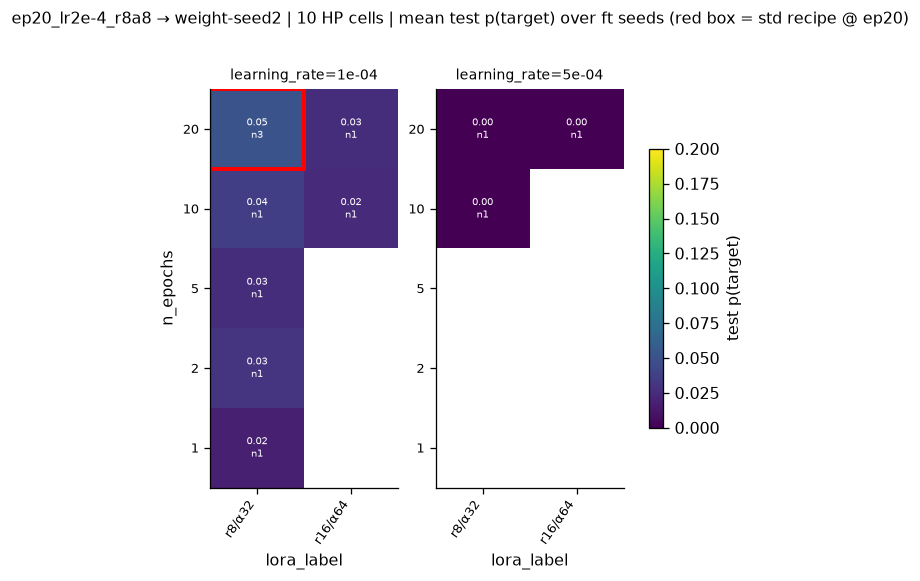

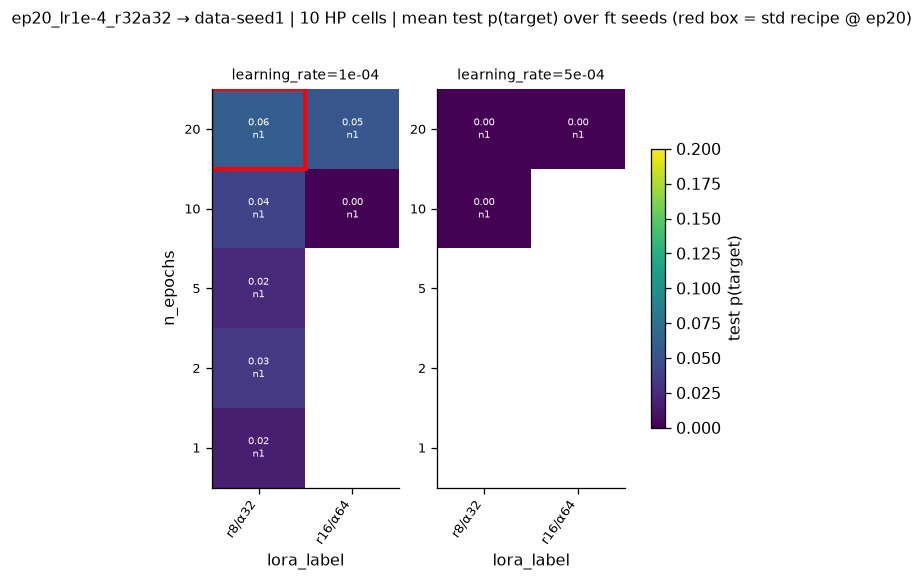

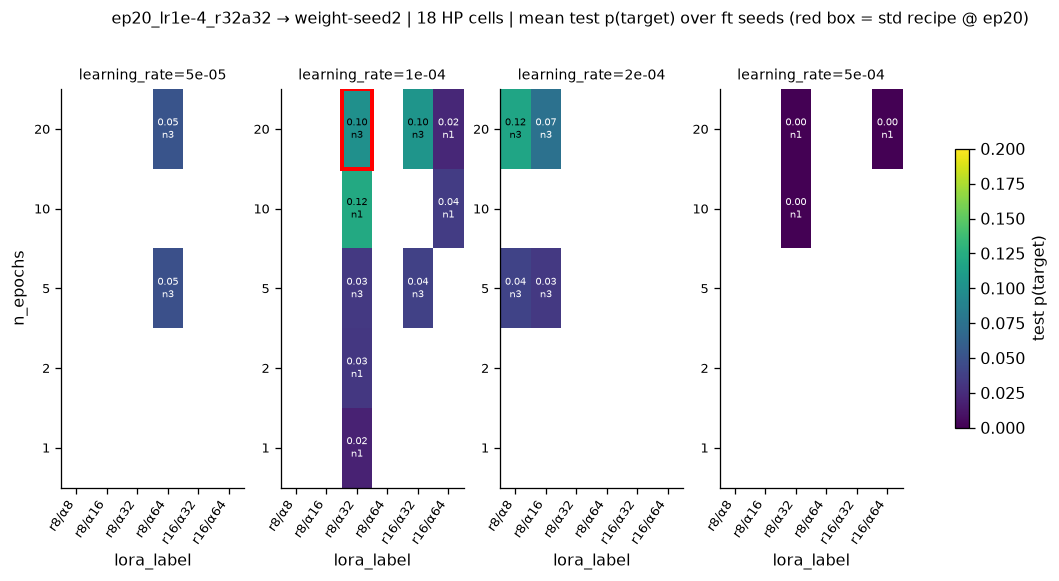

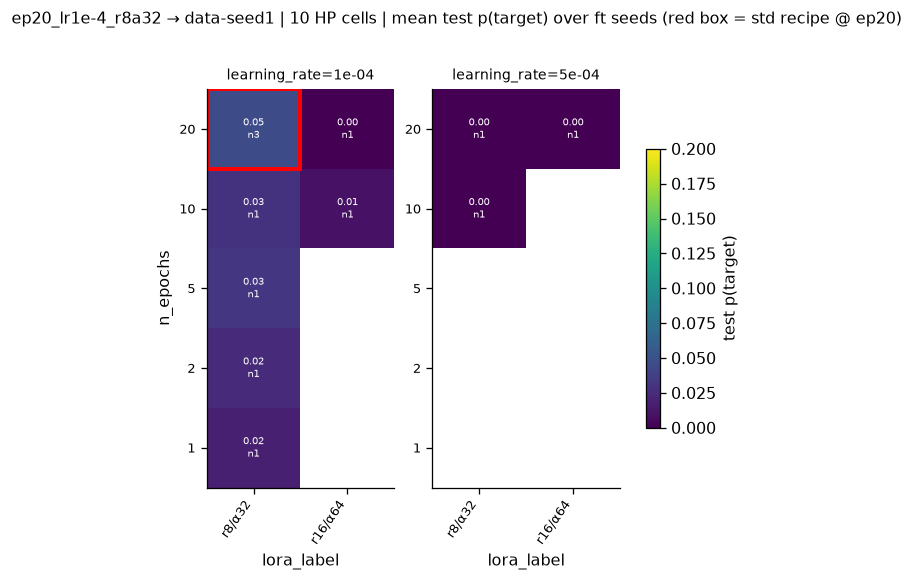

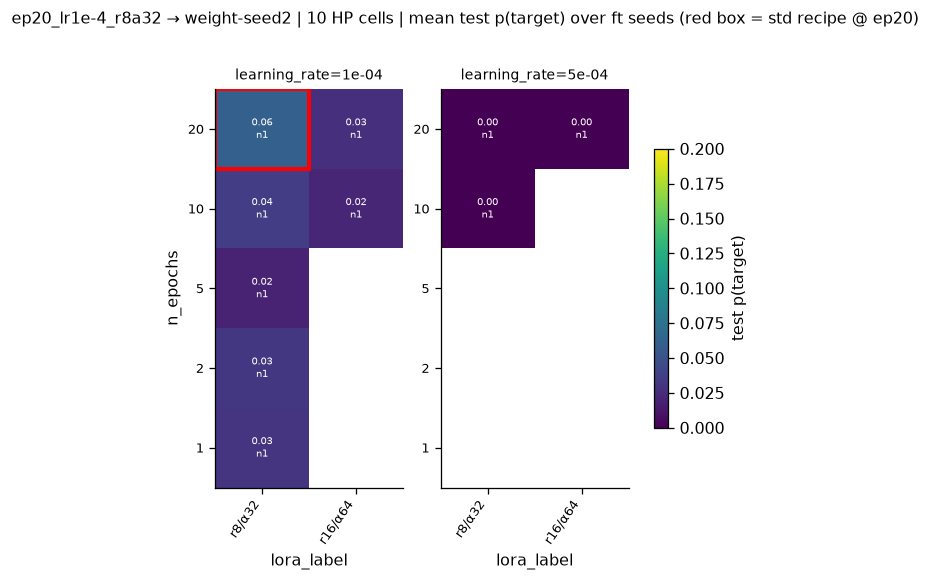

12 lineages, one figure each; all HP coordinates shown (nothing dropped)


In [ ]:
from subliminal_learning.analysis import frames, plots as aplots

# One figure per teacher lineage (focus first), displayed one after another — NEVER combined
# into one chart. Each figure is the standard HP-sweep layout used throughout the notebooks:
# y = distillation epochs, x = LoRA rank/α, one panel per student lr across the row.
# Every HP coordinate the lineage was run on is shown; panel width scales with the lineage's
# LoRA-column count so cell labels stay readable.
hp = frames.add_lora_label(runs.rename(
    columns={"ep": "n_epochs", "lr": "learning_rate", "rank": "lora_r", "alpha": "lora_alpha"}))
hp["lineage"] = hp.teacher_tag + " → " + hp.base.map(BASE_LABEL)
focus_name = f"{FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]}"
lineage_order = [focus_name] + [ln for t in TOP6 for b in BASES
                                if (ln := f"{t} → {BASE_LABEL[b]}") != focus_name and ln in set(hp.lineage)]
std_lora = f"r{BASELINE_LORA[0]}/α{BASELINE_LORA[1]}"
for ln in lineage_order:
    sub = hp[hp.lineage.eq(ln)]
    n_cells = sub.groupby(["n_epochs", "learning_rate", "lora_label"], observed=True).ngroups
    tag = "(focus) " if ln == focus_name else ""
    _ = aplots.facet_grid_heatmaps(
        sub, row="n_epochs", col="lora_label", val="test", col_facet="learning_rate",
        show_n=True, vmin=0.0, vmax=0.2,
        panel_w=max(2.4, .45 * sub.lora_label.nunique()),
        highlight=[{"n_epochs": 20, "lora_label": std_lora, "learning_rate": BASELINE_LR}],
        title=f"{tag}{ln} | {n_cells} HP cells | mean test p(target) over ft seeds "
              "(red box = std recipe @ ep20)",
        cbar_label="test p(target)")
plt.show()
print(f"{len(lineage_order)} lineages, one figure each; all HP coordinates shown (nothing dropped)")


## 8. Breaking the lr/α confound — lr 2e-4 is *not* a dead zone (3-seed batch, 2026-07-23/24)

> **Law superseded by §11–§12.** This section originally folded the two aggression knobs into the product `lr × α`. On the fuller grid the boundary is `lr·α^0.58·r^-0.09` (rank protective), and the two specific claims this section once headlined are false there: "every ep20 cell survives at lr×α ≤ 3.2e-3" has 7 counterexamples, and `r8α16 @ lr2e-4` is not the strongest cell in the exploration (`lr4e-4 r32α4` reaches 0.256). What stands unchanged is the experimental point below: the early "lr ≥ 2e-4 is an absolute dead zone" reading was a **scale confound** — lr alone is not the toxin.

The early stages concluded the student-lr cliff sits between 1e-4 and 2e-4 "and is absolute". Every lr-2e-4 cell run up to then also carried α ≥ 32; this batch breaks the confound — lr 2e-4 at **small α** (r8α8, r8α16, r16α16) × {ep5, ep20} × 3 seeds, plus an r8α64 lr-rescue (lr 5e-4 vs 5e-5):

- **lr 2e-4 transfers fine at low α.** `r8α16` at lr 2e-4 ep20 = 0.120 (3-seed), with `r8α8` (0.088) and `r16α16` (0.055) also clearly alive — against < 0.001 for the α ≥ 32 cells at the *same* lr.
- **The r8α64 lr-rescue is the within-architecture proof.** Identical adapter, only the lr changes: 0.000 at lr 5e-4 → **0.096 at lr 5e-5** — the config Angela intended, and one of the most *reliable* cells (seeds 0.046–0.140, no near-zero seed).
- **Dose still pays:** ep20 ≫ ep5 for all three low-α lr-2e-4 recipes (≈3–4× at matched HP).

Caveat unchanged from §6: seed spread is large — r8α16's headline 0.120 rests on 0.240/0.117/**0.002**; the *reliable* winners are `r8α64 @ lr5e-5` (0.096) and `r8α8 @ lr2e-4` (0.088), both with all three seeds off zero.

Below: the batch table, then the house 2D grids at ep20, one figure per teacher config displayed sequentially — the focus lineage's full rank × lr surface per LoRA scale, followed by the same cut for each §10 teacher lineage (menu coordinates only). (The lr×α "money plot" that used to sit here drew the superseded law and was removed; §11–§12 chart the fitted boundary.)


student_tag,ep,lr,rank,alpha,lr_alpha,mean_test,n_seeds,seed_min,seed_max
ep20_lr2e-4_r8a8,20,2e-04,8,8,1.6e-03,0.091,5,0.049,0.140
ep20_lr5e-5_r8a64,20,5e-05,8,64,3.2e-03,0.079,5,0.009,0.140
ep20_lr2e-4_r8a16,20,2e-04,8,16,3.2e-03,0.073,5,0.001,0.241
ep20_lr2e-4_r16a16,20,2e-04,16,16,3.2e-03,0.063,5,0.000,0.116
ep5_lr2e-4_r8a8,5,2e-04,8,8,1.6e-03,0.032,3,0.026,0.043
ep5_lr2e-4_r8a16,5,2e-04,8,16,3.2e-03,0.029,3,0.021,0.040
ep5_lr2e-4_r16a16,5,2e-04,16,16,3.2e-03,0.025,3,0.012,0.044
ep20_lr5e-4_r8a64,20,5e-04,8,64,3.2e-02,0.000,5,0.000,0.000


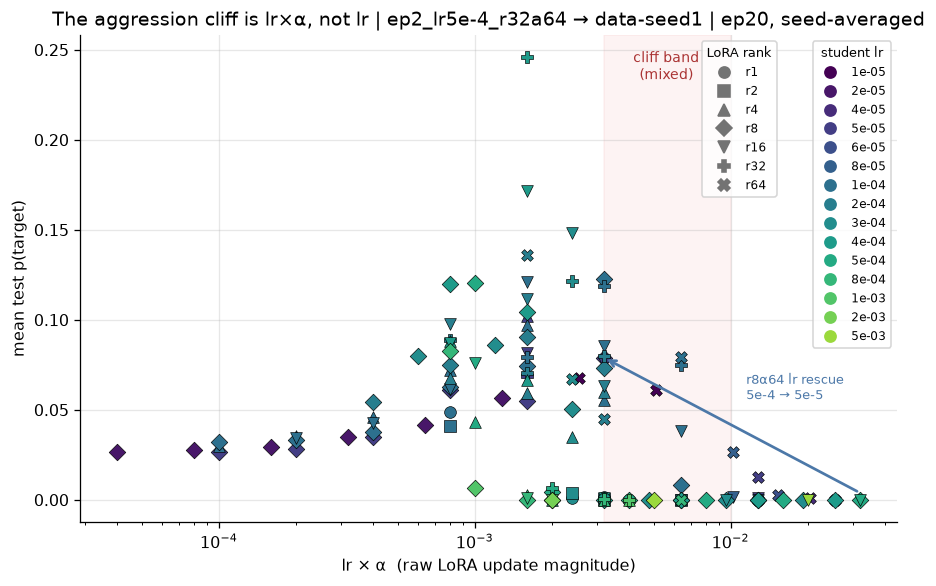

lr 2e-4, ep20 — survives at low alpha, dies at alpha>=32:
  r8a2   (lr*a=4.0e-04)  p=0.054  n5
  r16a4   (lr*a=8.0e-04)  p=0.098  n5
  r4a4   (lr*a=8.0e-04)  p=0.068  n5
  r32a4   (lr*a=8.0e-04)  p=0.089  n5
  r8a4   (lr*a=8.0e-04)  p=0.075  n5
  r64a8   (lr*a=1.6e-03)  p=0.136  n5
  r4a8   (lr*a=1.6e-03)  p=0.060  n5
  r16a8   (lr*a=1.6e-03)  p=0.111  n5
  r32a8   (lr*a=1.6e-03)  p=0.070  n5
  r8a8   (lr*a=1.6e-03)  p=0.091  n5
  r64a16  (lr*a=3.2e-03)  p=0.045  n5
  r2a16  (lr*a=3.2e-03)  p=0.001  n5
  r8a16  (lr*a=3.2e-03)  p=0.073  n5
  r32a16  (lr*a=3.2e-03)  p=0.080  n5
  r1a16  (lr*a=3.2e-03)  p=0.002  n5
  r16a16  (lr*a=3.2e-03)  p=0.063  n5
  r4a16  (lr*a=3.2e-03)  p=0.060  n5
  r16a32  (lr*a=6.4e-03)  p=0.000  n5
  r8a32  (lr*a=6.4e-03)  p=0.000  n5
  r32a64  (lr*a=1.3e-02)  p=0.000  n5
  r8a64  (lr*a=1.3e-02)  p=0.000  n5
r8a64 lr-rescue: lr5e-4=0.000 -> lr5e-5=0.079


In [ ]:
# New 3-seed batch (2026-07-23/24): break the lr-2e-4 / alpha confound + the r8a64 lr-rescue.
# (The lr*alpha "money plot" was removed with the superseded §8 law; §11-§12 chart the fitted boundary.)
BATCH = ["ep20_lr2e-4_r8a8", "ep20_lr2e-4_r8a16", "ep20_lr2e-4_r16a16",
         "ep5_lr2e-4_r8a8", "ep5_lr2e-4_r8a16", "ep5_lr2e-4_r16a16",
         "ep20_lr5e-4_r8a64", "ep20_lr5e-5_r8a64"]
batch = focus[focus.student_tag.isin(BATCH)].assign(lr_alpha=lambda d: d.lr * d.alpha) \
             .sort_values("mean_test", ascending=False)
tbl = batch[["student_tag", "ep", "lr", "rank", "alpha", "lr_alpha", "mean_test", "n_seeds", "seed_min", "seed_max"]]
display(tbl.style.format({"lr": "{:.0e}", "lr_alpha": "{:.1e}", "mean_test": "{:.3f}",
                          "seed_min": "{:.3f}", "seed_max": "{:.3f}"})
        .set_caption("New 3-seed batch (focus cell) — sorted by mean test p(target)").hide(axis="index"))

# The headline correction, quantified: lr 2e-4 at ep20, split by alpha.
lr2 = focus[focus.lr.eq(2e-4) & focus.ep.eq(20)].sort_values("alpha")
print("lr 2e-4, ep20 — survives at low alpha, dies at alpha>=32:")
for t in lr2.itertuples():
    print(f"  r{t.rank}a{t.alpha:<3d} (lr*a={t.lr * t.alpha:.1e})  p={t.mean_test:.3f}  n{t.n_seeds}")
resc = {t.student_tag: t.mean_test for t in focus[focus.student_tag.isin(
    ['ep20_lr5e-4_r8a64', 'ep20_lr5e-5_r8a64'])].itertuples()}
print(f"r8a64 lr-rescue: lr5e-4={resc.get('ep20_lr5e-4_r8a64', float('nan')):.3f} "
      f"-> lr5e-5={resc.get('ep20_lr5e-5_r8a64', float('nan')):.3f}")


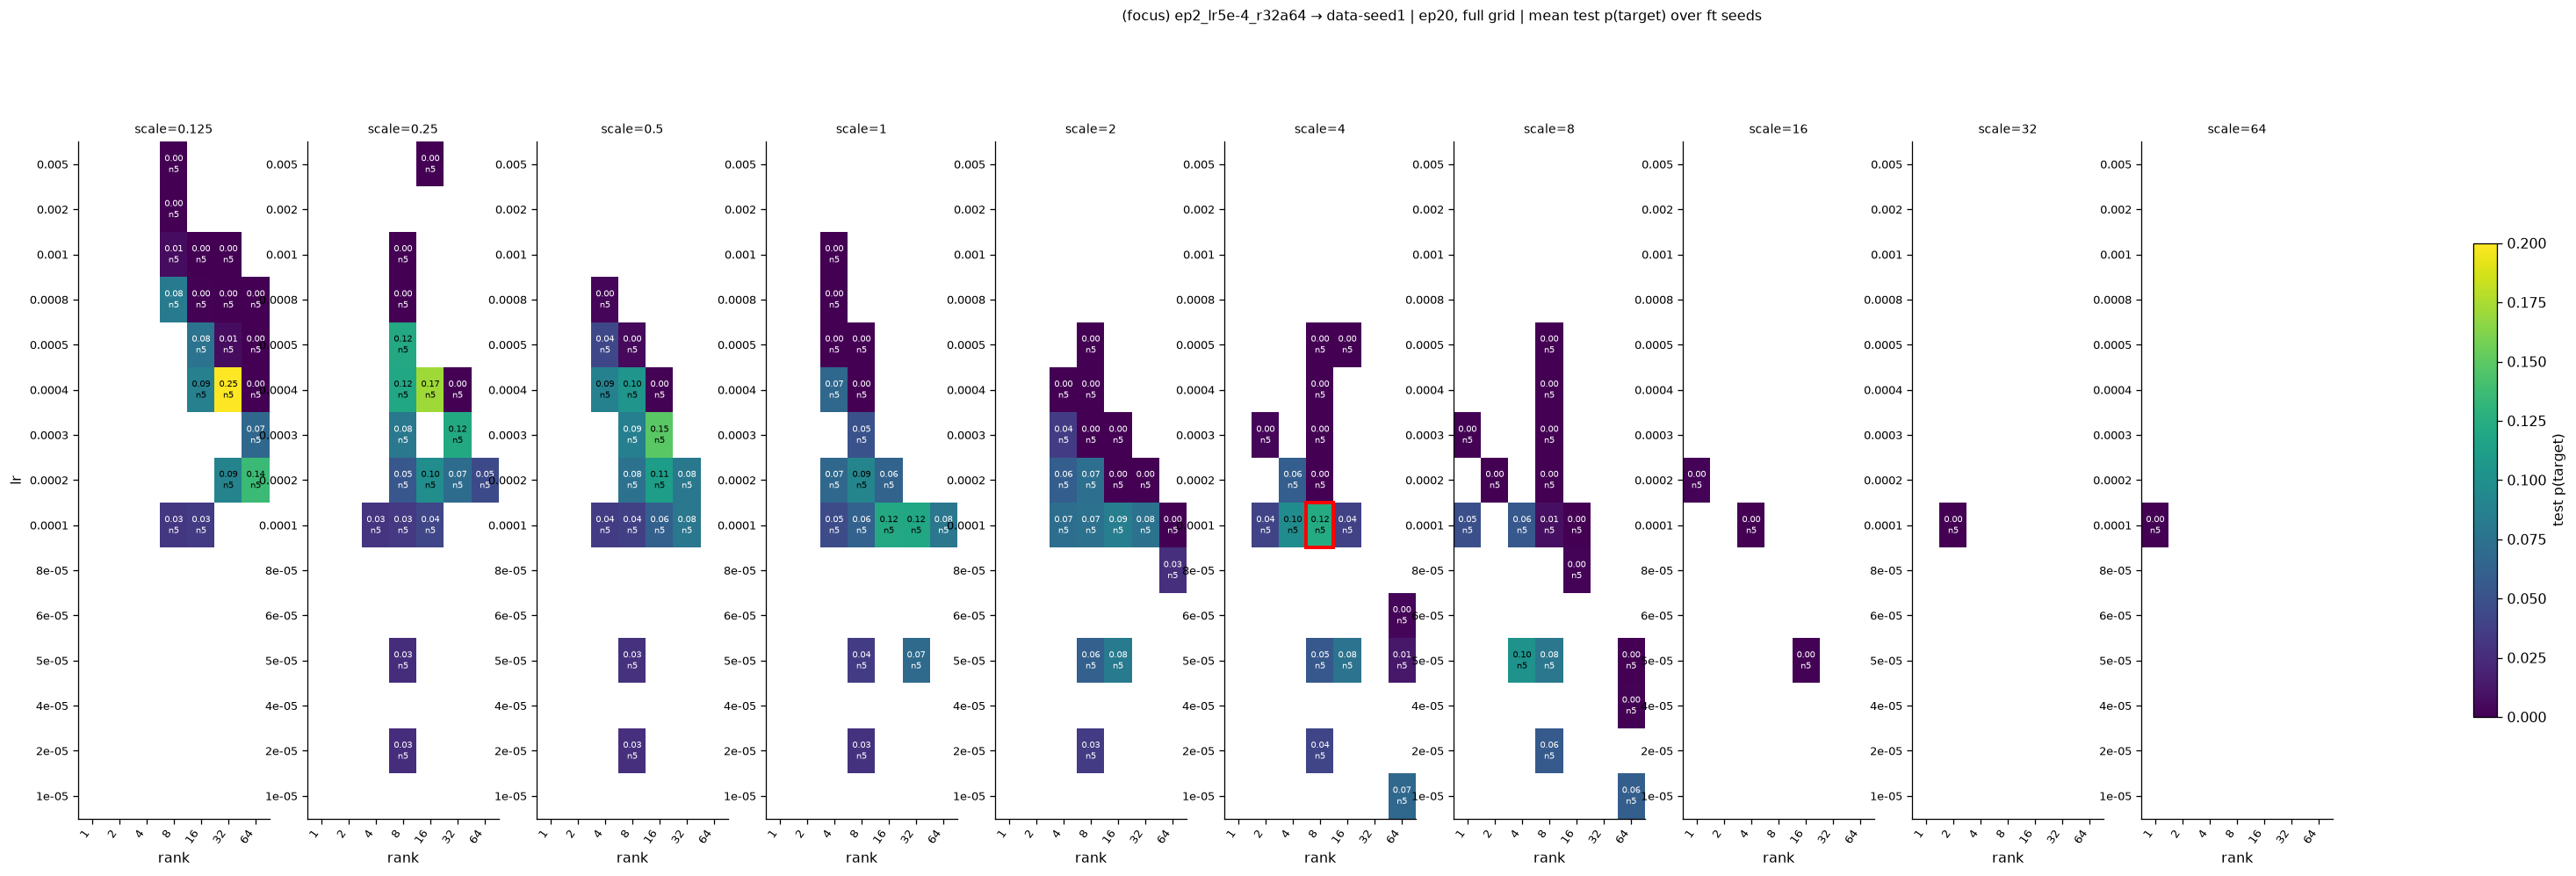

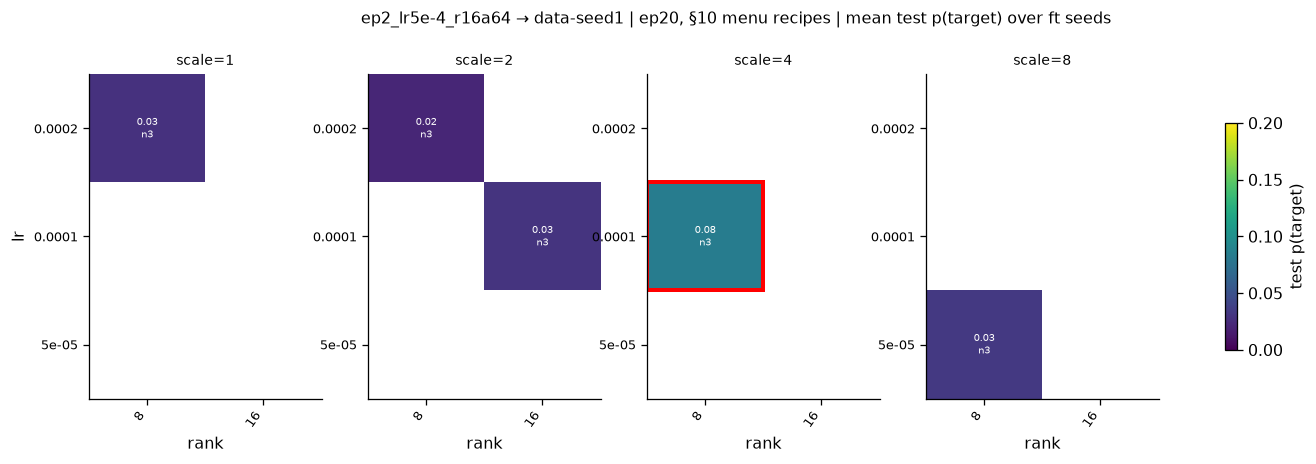

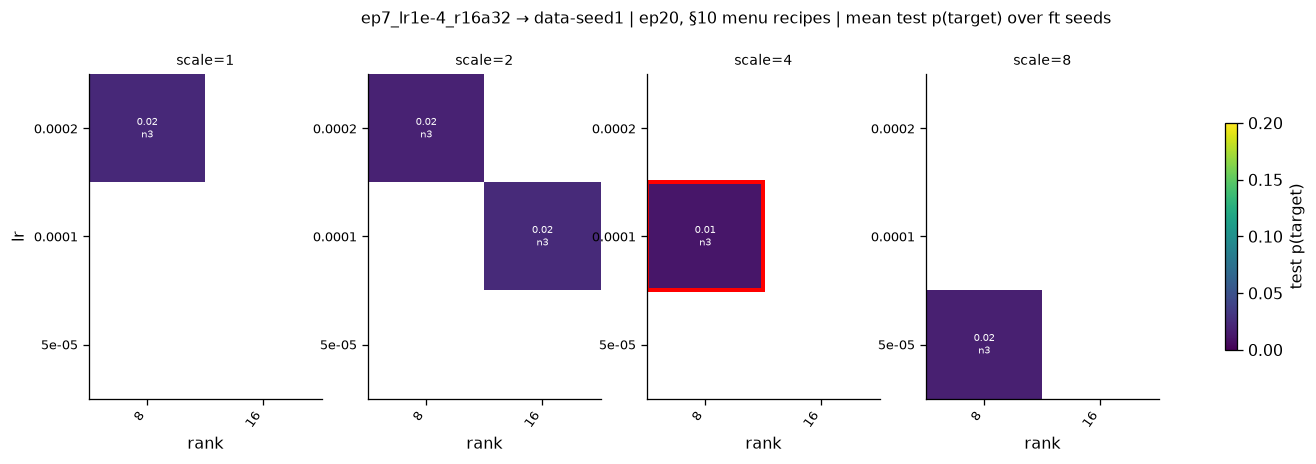

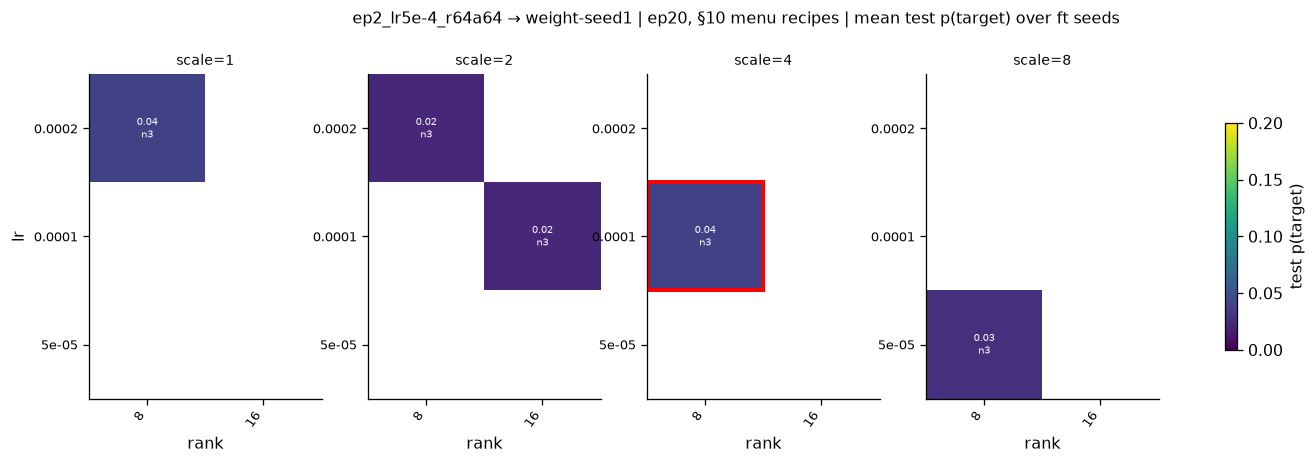

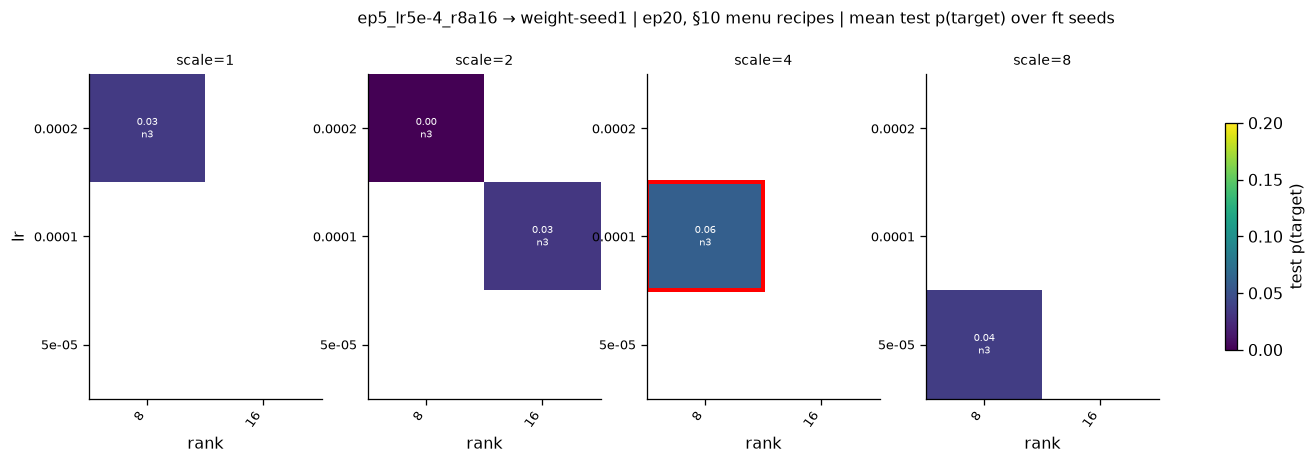

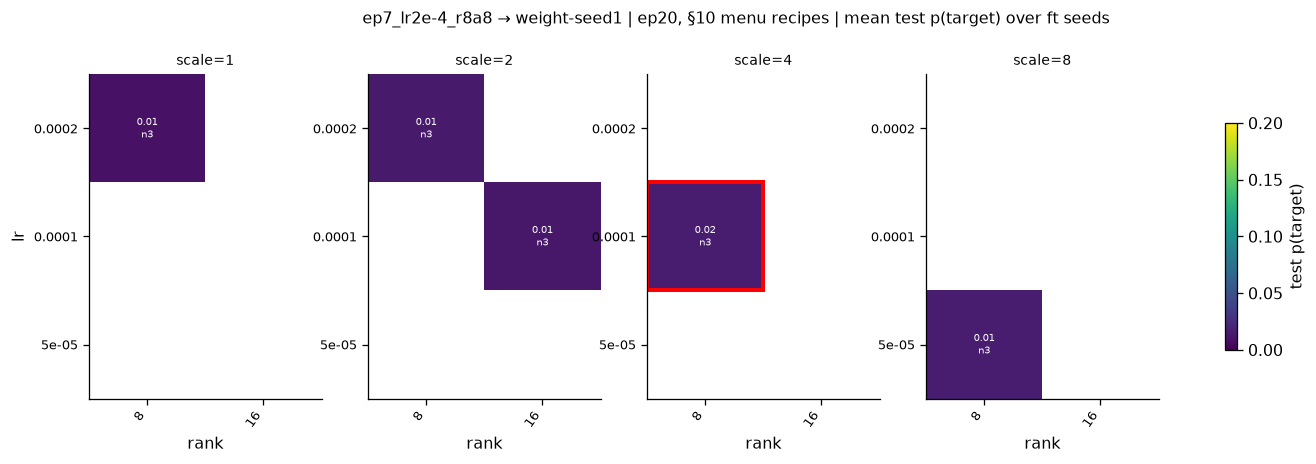

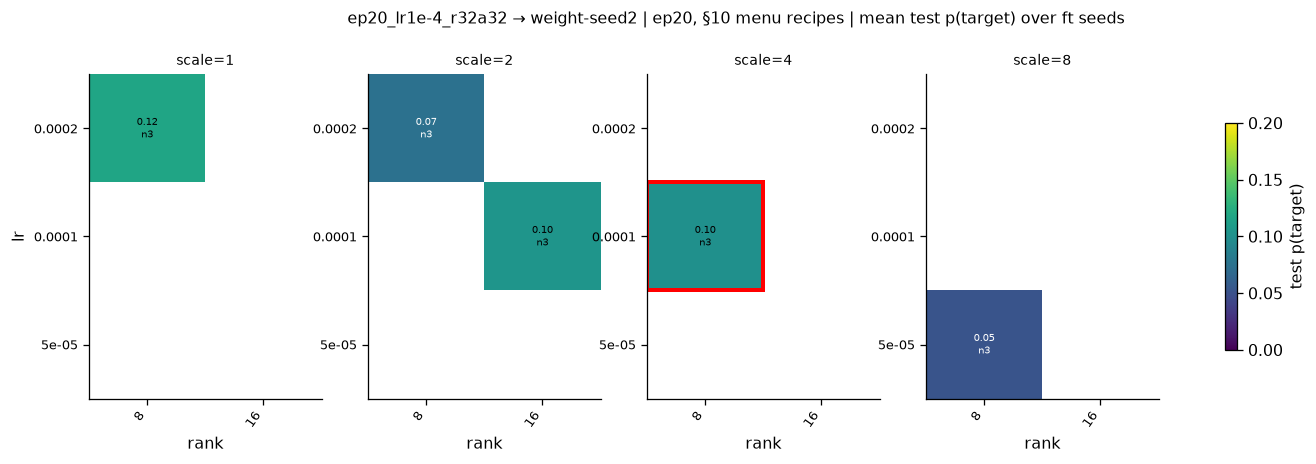

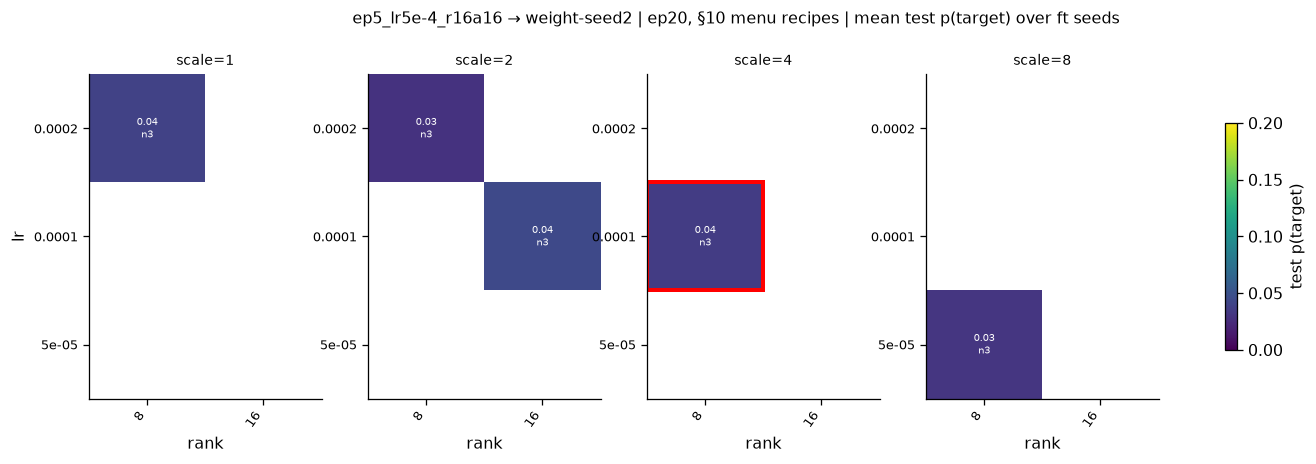

In [ ]:
# The same cut in the house 2D-grid style — one figure per teacher config at ep20, displayed
# sequentially: x = LoRA rank, y = student lr, one panel per LoRA scale (α/r). First the focus
# lineage over its FULL dense ep20 grid, then each §10 menu lineage over the five menu recipes
# (std + four gentle; blank = not in the menu). Red box = the std recipe (lr 1e-4, r8, α/r = 4).
from subliminal_learning.analysis import plots as aplots

g20 = focus_runs[focus_runs.ep.eq(20)].copy()
_ = aplots.facet_heatmaps(
    g20, row="lr", col="rank", facet="scale", val="test",
    show_n=True, vmin=0.0, vmax=0.2, highlight=(1e-4, 8, 4.0),
    title=f"(focus) {FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]} | ep20, full grid | "
          "mean test p(target) over ft seeds",
    cbar_label="test p(target)")
m20 = menu_runs[menu_runs.ep.eq(20) & ~menu_runs.is_focus].assign(scale=lambda d: d.alpha / d["rank"])
for ln in LINEAGES[1:]:
    sub = m20[m20.lineage.eq(ln)]
    if not len(sub): continue
    _ = aplots.facet_heatmaps(
        sub, row="lr", col="rank", facet="scale", val="test",
        show_n=True, vmin=0.0, vmax=0.2, highlight=(1e-4, 8, 4.0),
        title=f"{ln} | ep20, §10 menu recipes | mean test p(target) over ft seeds",
        cbar_label="test p(target)")
plt.show()


## 10. Does the §8 result hold on other teachers? — no; std stays the default (2026-07-24)

§4–§8 mapped the student-HP surface of **one** lineage (the focus, `ep2_lr5e-4_r32a64 → data-seed1`). This section asks a single question: **is the §8 recipe ranking a property of the recipes, or of that one lineage?**

The test: seven more teacher configs — spanning strong and mid-strength std-recipe transfer, on three student bases including `weight-seed1` (new to this notebook) — each ran the identical five-recipe **menu**: the standard recipe (`r8α32 @ lr 1e-4`) plus the four §8 gentle recipes (`r8α8@2e-4`, `r8α16@2e-4`, `r16α32@1e-4`, `r8α64@5e-5` — all at lr×α ≤ 3.2e-3), at {ep5, ep20} × 3 ft seeds. Jobs: `run_logs/hp_t{2..8}_*_jobs.txt`, drained 2026-07-24, all 70 new cells at 3/3 seeds. The per-teacher heatmap grids for these lineages are **at the end of §8**; below: the ep20 table, then one chart putting each lineage's five recipes side by side.

The answer, in three parts:

- **No gentle recipe beats std anywhere.** Best gain over a lineage's own std baseline is **+0.017** — well inside the ±0.06 noise band from §6 — while std wins by 0.050 on the strongest new lineage. §8's star `r8α16@2e-4` never exceeds 0.074 off-focus. §8 mapped the focus cell's local surface, not a transferable ranking.
- **Gentle is still safe — with one real exception.** 69/70 new cells are alive, but `r8α16@2e-4` under `ep5_lr5e-4_r8a16 → weight-seed1` is dead on all three seeds (0.000/0.000/0.001) despite gentle lr×α — the safety half of the lr×α law is necessary, not sufficient.
- **Teacher lineage sets the ceiling.** Std-recipe ep20 spans 0.012–0.101 across the seven new lineages — nearly an order of magnitude — and no recipe choice rescues a weak lineage. Teacher config × base selection moves transfer far more than any student-HP move inside the safe region.


In [ ]:
# ep20 results per (teacher lineage, student recipe) — each cell = mean over 3 ft seeds.
p20 = menu_cells[menu_cells.ep.eq(20)].pivot_table(index="lineage", columns="recipe", values="mean_test") \
    .reindex(index=LINEAGES, columns=RECIPE_ORDER)
p20["best gentle − std"] = p20[RECIPE_ORDER[1:]].max(axis=1) - p20[RECIPE_ORDER[0]]
display(p20.style.format("{:.3f}", na_rep="–").format("{:+.3f}", subset=["best gentle − std"])
        .set_caption("ep20 mean test p(target) per (teacher lineage, student recipe); 3 ft seeds per cell. "
                     "Row 1 = the §8 focus lineage. Last column: best gentle recipe minus the same "
                     "lineage's own std — positive beyond ±0.06 would mean a gentle recipe beat std."))


recipe,std r8α32@1e-4,r8α8@2e-4,r8α16@2e-4,r16α32@1e-4,r8α64@5e-5,best gentle − std
lineage,,,,,,
ep2_lr5e-4_r32a64 → data-seed1,0.123,0.091,0.073,0.086,0.079,-0.032
ep2_lr5e-4_r16a64 → data-seed1,0.084,0.029,0.021,0.030,0.033,-0.050
ep7_lr1e-4_r16a32 → data-seed1,0.012,0.023,0.019,0.023,0.017,+0.011
ep2_lr5e-4_r64a64 → weight-seed1,0.039,0.039,0.023,0.022,0.028,+0.000
ep5_lr5e-4_r8a16 → weight-seed1,0.060,0.034,0.001,0.033,0.036,-0.024
ep7_lr2e-4_r8a8 → weight-seed1,0.015,0.010,0.015,0.013,0.015,-0.001
ep20_lr1e-4_r32a32 → weight-seed2,0.101,0.118,0.074,0.104,0.052,+0.017
ep5_lr5e-4_r16a16 → weight-seed2,0.036,0.040,0.030,0.044,0.031,+0.009


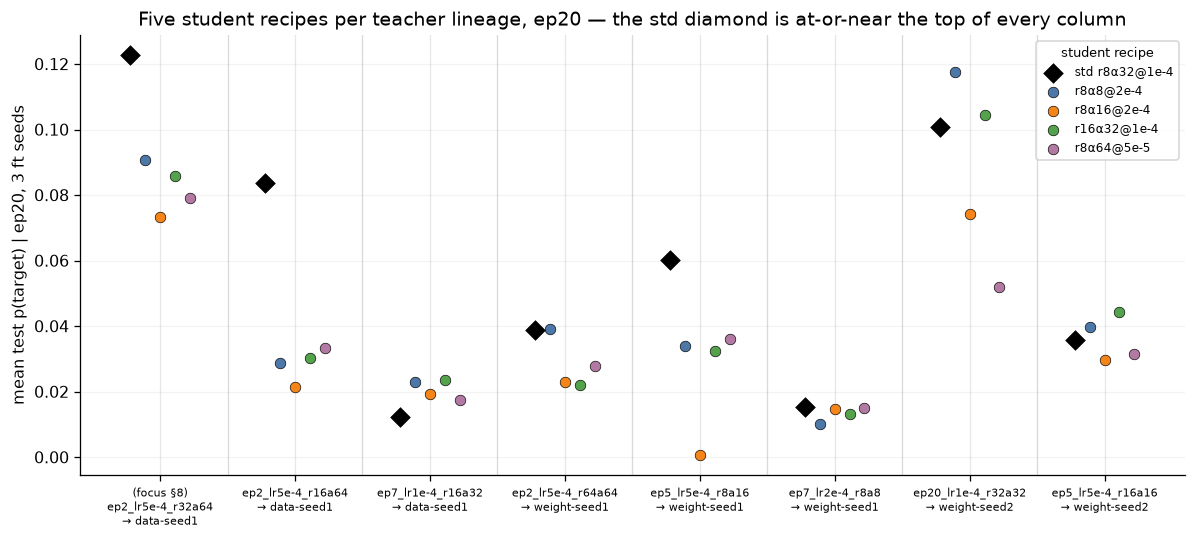

max gain of any gentle recipe over its lineage's own std (ep20): +0.017 — inside the ±0.06 noise band (§6)
dead ep20 menu cells (mean < 0.005): ep5_lr5e-4_r8a16 → weight-seed1 · r8α16@2e-4 = 0.0006
=> the std recipe stays the cross-init default; teacher lineage moves transfer far more than recipe choice


In [ ]:
# One chart: each lineage's five recipes side by side at ep20. Black diamond = the std recipe;
# the four gentle recipes keep fixed colours (legend). If any gentle recipe beat std anywhere,
# its dot would sit clearly above the diamond in that column — none does.
RECIPE_COLORS = {RECIPE_ORDER[0]: "black", RECIPE_ORDER[1]: "#4c78a8", RECIPE_ORDER[2]: "#f58518",
                 RECIPE_ORDER[3]: "#54a24b", RECIPE_ORDER[4]: "#b279a2"}
d20 = menu_cells[menu_cells.ep.eq(20)]
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for j, lab in enumerate(RECIPE_ORDER):
    g = d20[d20.recipe.eq(lab)].set_index("lineage").mean_test.reindex(LINEAGES)
    x = np.arange(len(LINEAGES)) + (j - 2) * .11
    std = lab == RECIPE_ORDER[0]
    ax.scatter(x, g.values, s=76 if std else 44, marker="D" if std else "o",
               color=RECIPE_COLORS[lab], edgecolor="k", lw=.4, zorder=4 if std else 3, label=lab)
for i in range(1, len(LINEAGES)):
    ax.axvline(i - .5, color=".85", lw=.8, zorder=1)
ax.set_xticks(range(len(LINEAGES)))
ax.set_xticklabels([("(focus §8)\n" if l == LINEAGES[0] else "") + l.replace(" → ", "\n→ ")
                    for l in LINEAGES], fontsize=7)
ax.set(ylabel="mean test p(target) | ep20, 3 ft seeds",
       title="Five student recipes per teacher lineage, ep20 — the std diamond is at-or-near the top of every column")
ax.grid(axis="y", alpha=.15)
ax.legend(fontsize=7.5, title="student recipe", title_fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

d = p20[RECIPE_ORDER[1:]].sub(p20[RECIPE_ORDER[0]], axis=0)
dead20 = d20[d20.mean_test.lt(.005) & ~d20.is_focus]
print(f"max gain of any gentle recipe over its lineage's own std (ep20): {d.max().max():+.3f} "
      "— inside the ±0.06 noise band (§6)")
print("dead ep20 menu cells (mean < 0.005):",
      "; ".join(f"{t.lineage} · {t.recipe} = {t.mean_test:.4f}" for t in dead20.itertuples()) or "none")
print("=> the std recipe stays the cross-init default; teacher lineage moves transfer far more than recipe choice")


## 11. The collapse boundary is **lr × √α** — one number, rank term unresolved (2026-07-24)

> **Superseded by §12 (2026-07-25).** The "rank is not in the law" claim below is **false** — it was
> an artefact of this grid never running **rank below 4**. With rank 1/2 cells added on the cliff, the
> rank exponent is `c = -0.093`, CI `[-0.138, -0.065]`, comfortably excluding 0: **higher rank is
> protective**, and at fixed `lr`/`α` rank alone flips a cell from all-seeds-dead to all-seeds-alive.
> The α exponent firms to ≈0.58. The rank-free law misclassifies 11 of 131 cells. Read §12, not the
> "rank-free" bullets below; the `lr·√α` *ordering* intuition survives, the rank-independence does not.

§8 folded the two aggression knobs into the product `lr × α` and left a wide *mixed* band
(`lr×α` ≈ 3e-3 – 1e-2) where "a lower lr or larger rank still rescues." The hp-focus scale sweep has
since filled the (lr, α, rank) grid on this lineage to **82 ep20 cells** (24 collapsed / 58 alive),
spanning lr 2e-5 – 1e-3, α 1 – 128, rank 4 – 64. On that grid the band resolves, and the law sharpens
in two ways: the exponent on α is **½, not 1**, and the residual "larger rank rescues" effect **disappears**.

- **The law.** With `K = lr · √α`, collapse sets in at **K ≳ 9e-4**. Every one of the 48 cells at
  K ≤ 7.1e-4 is alive; every one of the 23 cells at K ≥ 1.0e-3 is dead (all seeds exactly 0). The 11
  cells in between are the stochastic band, where individual *seeds* drop out rather than whole cells.
  A single threshold on K misclassifies **1 of 82** cells — against 10 for §8's `lr×α`, 8 for `lr×α/r`,
  16 for lr alone, 21 for α/r, 23 for α alone, 24 for rank alone.
- **Rank does not measurably enter the boundary** (but see §12 — this is an absence of evidence, not evidence of absence). Hold K fixed and sweep rank 4→64 and the verdict never moves:
  at K = 5.7e-4, 10/10 cells alive across r4–r32; at K = 1.13e-3, 0/8 alive across r4–r32 (and r16α128).
  A max-margin fit *does* find perfect separation with `lr · α^0.58 · r^-0.14`, but the rank term buys
  only a **1.09× margin**, and under leave-one-out the 3-parameter law scores **78/82** against
  **80/82** for plain `lr·√α` — the rank exponent is fitting noise. Use the one-parameter law.
- **α/r ("scale") is the wrong variable**, which matters because it is the notebook's and the sweep's
  own vocabulary. It misses 21/82. At fixed α/r = 4, `r8α32 @ lr1e-4` scores 0.102 while
  `r8α32 @ lr2e-4` is exactly 0.000; at fixed α/r = 2, `r8α16 @ lr2e-4` lives (0.120) and
  `r16α32 @ lr2e-4` dies. It is *absolute* α that trades off against lr — so **doubling rank at fixed
  scale doubles α and walks you toward the cliff**, the opposite of the "more rank is safer" intuition.
- **The single error is a real transition cell, not a misfit.** `r8α64 @ lr1e-4` (K = 8.0e-4) sits just
  below the boundary but is dead 2-of-3 seeds. It is also the one place rank shows a whisper: at that
  same K and α = 64, r8 loses 2/3 seeds, r16 1/2, r32 1/3, r64 0/3. A whisper, not the law.
- **Signal peaks just *below* the cliff, not far from it.** Among survivors, transfer rises
  monotonically with K (Pearson(log K, p) = 0.64): mean p 0.029 at K < 1e-4 → 0.049 → 0.084 → **0.098**
  at K ∈ [6e-4, 9e-4). The strongest cells all sit in the last rung before the drop —
  `lr4e-4 r32α4` (0.256, K = 8.0e-4), `lr5e-4 r8α2` (0.140, K = 7.1e-4), `lr4e-4 r8α4` (0.124),
  `lr2e-4 r8α16` (0.120) — and by §6's reliability rule the first two are also *sound*, not just high:
  `r32α4` runs 0.113 / 0.138 / 0.318 / 0.456 and `r8α2` runs 0.088 – 0.166, neither with a near-zero
  seed, whereas `r8α16` still spans 0.002 – 0.241. The standard recipe `lr1e-4 r8α32` (K = 5.7e-4,
  now 0.102 on 4 seeds) is safely inside the live region but is **beaten ~2.5× by the frontier** —
  its own worst seeds (0.039, 0.045) fall below `r32α4`'s best.

**Operating rule:** keep `lr · √α ≤ 6e-4` to be safe, ≤ 8e-4 if losing one seed in three is acceptable,
and pick rank on other grounds (capacity, compute) — it does not buy safety. Buy aggressiveness through
**lr** and pay for it with **low α**, not the reverse: `lr4e-4 r32α4` beats every gentle-lr cell here.

*Caveats.* One teacher lineage × one student base × ep20 only — §10's lesson (the safety half of a law
generalizes, the ranking half does not) has not been retested for the √α form. The hp-focus sweep has since drained; the code recomputes everything from disk, the prose
numbers are the 2026-07-24 snapshot, and §12 re-fits on the final grid. Whether K\* shifts with student epochs is untested — the ep5 rung
is excluded here by construction.

In [ ]:
# §11 — is there a decision boundary in (lr, alpha, rank) at ep20? Fit it, don't eyeball it.
DEAD_CELL, DEAD_SEED = 0.015, 0.01        # collapse thresholds: cell-mean, individual seed
K_SAFE, K_DEAD, K_STAR = 7.1e-4, 1.0e-3, 9e-4   # empirical band edges + the round boundary

b11 = focus[focus.ep.eq(20) & focus.mean_test.notna()].copy()
b11["K"] = b11.lr * np.sqrt(b11.alpha)
b11["dead"] = b11.mean_test.lt(DEAD_CELL)
_ds = (focus_runs[focus_runs.ep.eq(20)].assign(d=lambda d: d.test.lt(DEAD_SEED))
       .groupby("student_tag").d.sum())
b11["n_dead_seeds"] = b11.student_tag.map(_ds).fillna(0).astype(int)
y11 = b11.dead.values.astype(int)

def min_errors(v, y=y11):
    """Fewest cells misclassified by any single threshold on v (the composite's best case)."""
    v = np.asarray(v, float)
    return min(int(((v >= t).astype(int) != y).sum()) for t in list(v) + [np.inf])

CANDIDATES = {"lr × √α  (§11)": b11.K, "lr × α/r": b11.lr * b11.scale,
              "lr × α  (§8)": b11.lr * b11.alpha, "lr × α²/r": b11.lr * b11.alpha**2 / b11["rank"],
              "lr alone": b11.lr, "α/r (\"scale\")": b11.scale,
              "α alone": b11.alpha, "rank alone": b11["rank"]}
cmp11 = (pd.DataFrame([{"candidate law": k, "cells misclassified": min_errors(v), "of": len(y11)}
                       for k, v in CANDIDATES.items()])
         .sort_values("cells misclassified"))
print(f"ep20 focus cells with a test score: {len(b11)}  "
      f"({int(y11.sum())} collapsed at mean < {DEAD_CELL}, {int((~b11.dead).sum())} alive)")
display(cmp11.style.set_caption("Best achievable separation per candidate law (single threshold)")
        .hide(axis="index"))

# Does rank earn a place in the law? Max-margin exponents + leave-one-out against the 1-param law.
L11, A11, R11 = np.log(b11.lr.values), np.log(b11.alpha.values), np.log(b11["rank"].values)
def margin(b, c):
    s = L11 + b * A11 + c * R11
    return s[y11 == 1].min() - s[y11 == 0].max()
mg, bb, cc = max(((margin(b, c), b, c) for b in np.arange(0, 2.001, .02)
                  for c in np.arange(-1, 1.001, .02)), key=lambda t: t[0])
loo3 = loo1 = 0
for i in range(len(y11)):
    k = np.ones(len(y11), bool); k[i] = False
    _, p, q = max(((np.min((L11[k] + p*A11[k] + q*R11[k])[y11[k] == 1])
                    - np.max((L11[k] + p*A11[k] + q*R11[k])[y11[k] == 0]), p, q)
                   for p in np.arange(0, 2.001, .05) for q in np.arange(-1, 1.001, .05)), key=lambda t: t[0])
    s = L11[k] + p*A11[k] + q*R11[k]; t3 = (s[y11[k] == 1].min() + s[y11[k] == 0].max()) / 2
    loo3 += (1 if L11[i] + p*A11[i] + q*R11[i] >= t3 else 0) == y11[i]
    t1 = (b11.K.values[k][y11[k] == 1].min() + b11.K.values[k][y11[k] == 0].max()) / 2
    loo1 += (1 if b11.K.values[i] >= t1 else 0) == y11[i]
# verdict computed from the live LOO counts: on the original 82-cell grid (rank >= 4 only) the
# 1-param law won and this printed "fits noise"; with rank-1/2 cells on the cliff it flips (§12).
loo_verdict = ("the rank exponent fits noise; use lr·√α" if loo3 <= loo1 else
               f"3-param beats 1-param under LOO by {loo3 - loo1} cells — rank is real on this grid (§12)")
print(f"\nmax-margin law: lr × α^{bb:.2f} × r^{cc:.2f} — separable={mg > 0}, margin={np.exp(mg):.2f}×")
print(f"  leave-one-out: 3-param (rank in) {loo3}/{len(y11)}  vs  1-param lr·√α {loo1}/{len(y11)}"
      f"   => {loo_verdict}")
print(f"\nlr·√α:  max K among alive = {b11[~b11.dead].K.max():.2e} | "
      f"min K among collapsed = {b11[b11.dead].K.min():.2e}")
print(f"  K <= {K_SAFE:.1e}: {int((b11.K <= K_SAFE).sum())} cells, "
      f"{int(b11[b11.K <= K_SAFE].dead.sum())} collapsed")
print(f"  K >= {K_DEAD:.1e}: {int((b11.K >= K_DEAD).sum())} cells, "
      f"{int((~b11[b11.K >= K_DEAD].dead).sum())} alive")
print(f"  threshold K* = {K_STAR:.1e} misclassifies: "
      f"{list(b11[(b11.K >= K_STAR) != b11.dead].student_tag) or 'nothing'}")

band11 = b11[b11.K.gt(K_SAFE) & b11.K.lt(K_DEAD)].sort_values("mean_test")
display(band11[["student_tag", "lr", "rank", "alpha", "K", "mean_test", "n_dead_seeds", "n_seeds"]]
        .style.format({"lr": "{:.0e}", "K": "{:.2e}", "mean_test": "{:.3f}"})
        .set_caption(f"The transition band ({K_SAFE:.1e} < K < {K_DEAD:.1e}) — mixed cell-by-cell "
                     "and seed-by-seed").hide(axis="index"))

print("Rank-invariance — cells that share a K, swept across LoRA rank:")
for K, g in b11.groupby(b11.K.round(6)):
    if g["rank"].nunique() < 3: continue
    print(f"  K={K:.2e}  ranks {[int(r) for r in sorted(g['rank'].unique())]} -> "
          f"{int((~g.dead).sum())}/{len(g)} alive")


ep20 focus cells with a test score: 131  (55 collapsed at mean < 0.015, 76 alive)


candidate law,cells misclassified,of
lr × √α (§11),11,131
lr × α (§8),26,131
lr × α/r,28,131
lr × α²/r,33,131
lr alone,35,131
"α/r (""scale"")",45,131
α alone,46,131
rank alone,54,131



max-margin law: lr × α^0.56 × r^-0.08 — separable=False, margin=0.92×
  leave-one-out: 3-param (rank in) 127/131  vs  1-param lr·√α 120/131   => 3-param beats 1-param under LOO by 7 cells — rank is real on this grid (§12)



lr·√α:  max K among alive = 9.05e-04 | min K among collapsed = 8.00e-04
  K <= 7.1e-04: 57 cells, 0 collapsed
  K >= 1.0e-03: 42 cells, 0 alive
  threshold K* = 9.0e-04 misclassifies: ['ep20_lr1e-4_r1a64', 'ep20_lr1e-4_r2a64', 'ep20_lr1e-4_r4a64', 'ep20_lr1e-4_r8a64', 'ep20_lr2e-4_r1a16', 'ep20_lr2e-4_r2a16', 'ep20_lr3e-4_r1a8', 'ep20_lr3e-4_r2a8', 'ep20_lr5e-5_r16a256', 'ep20_lr5e-5_r64a256', 'ep20_lr8e-5_r64a128']


student_tag,lr,rank,alpha,K,mean_test,n_dead_seeds,n_seeds
ep20_lr1e-4_r1a64,1e-04,1,64,8.00e-04,0.000,5,5
ep20_lr1e-4_r2a64,1e-04,2,64,8.00e-04,0.000,5,5
ep20_lr1e-4_r4a64,1e-04,4,64,8.00e-04,0.000,5,5
ep20_lr2e-4_r2a16,2e-04,2,16,8.00e-04,0.001,5,5
ep20_lr5e-5_r16a256,5e-05,16,256,8.00e-04,0.001,5,5
ep20_lr4e-5_r64a512,4e-05,64,512,9.05e-04,0.001,5,5
ep20_lr3e-4_r1a8,3e-04,1,8,8.49e-04,0.001,5,5
ep20_lr2e-4_r1a16,2e-04,1,16,8.00e-04,0.002,5,5
ep20_lr8e-5_r16a128,8e-05,16,128,9.05e-04,0.002,5,5
ep20_lr6e-5_r64a256,6e-05,64,256,9.60e-04,0.003,4,5


Rank-invariance — cells that share a K, swept across LoRA rank:
  K=1.41e-04  ranks [4, 8, 16] -> 4/4 alive
  K=2.00e-04  ranks [4, 8, 16] -> 4/4 alive
  K=2.83e-04  ranks [1, 2, 4, 8, 16, 32] -> 10/10 alive
  K=4.00e-04  ranks [4, 8, 16, 32] -> 10/10 alive
  K=5.66e-04  ranks [4, 8, 16, 32, 64] -> 12/12 alive
  K=7.07e-04  ranks [4, 8, 16] -> 3/3 alive
  K=8.00e-04  ranks [1, 2, 4, 8, 16, 32, 64] -> 13/21 alive
  K=8.49e-04  ranks [1, 2, 4, 8, 16, 32, 64] -> 5/7 alive
  K=1.00e-03  ranks [4, 8, 32] -> 0/4 alive
  K=1.13e-03  ranks [4, 8, 16, 32, 64] -> 0/13 alive
  K=1.41e-03  ranks [8, 16, 64] -> 0/4 alive
  K=1.60e-03  ranks [4, 8, 32] -> 0/5 alive
  K=2.00e-03  ranks [4, 8, 32] -> 0/4 alive


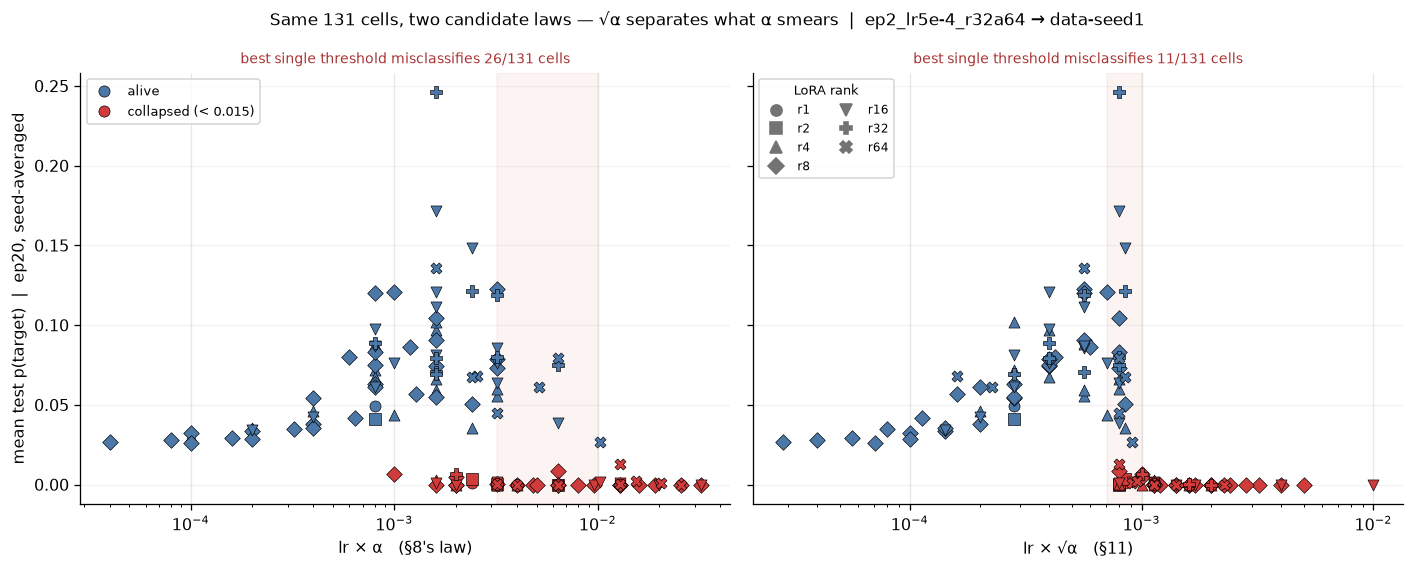

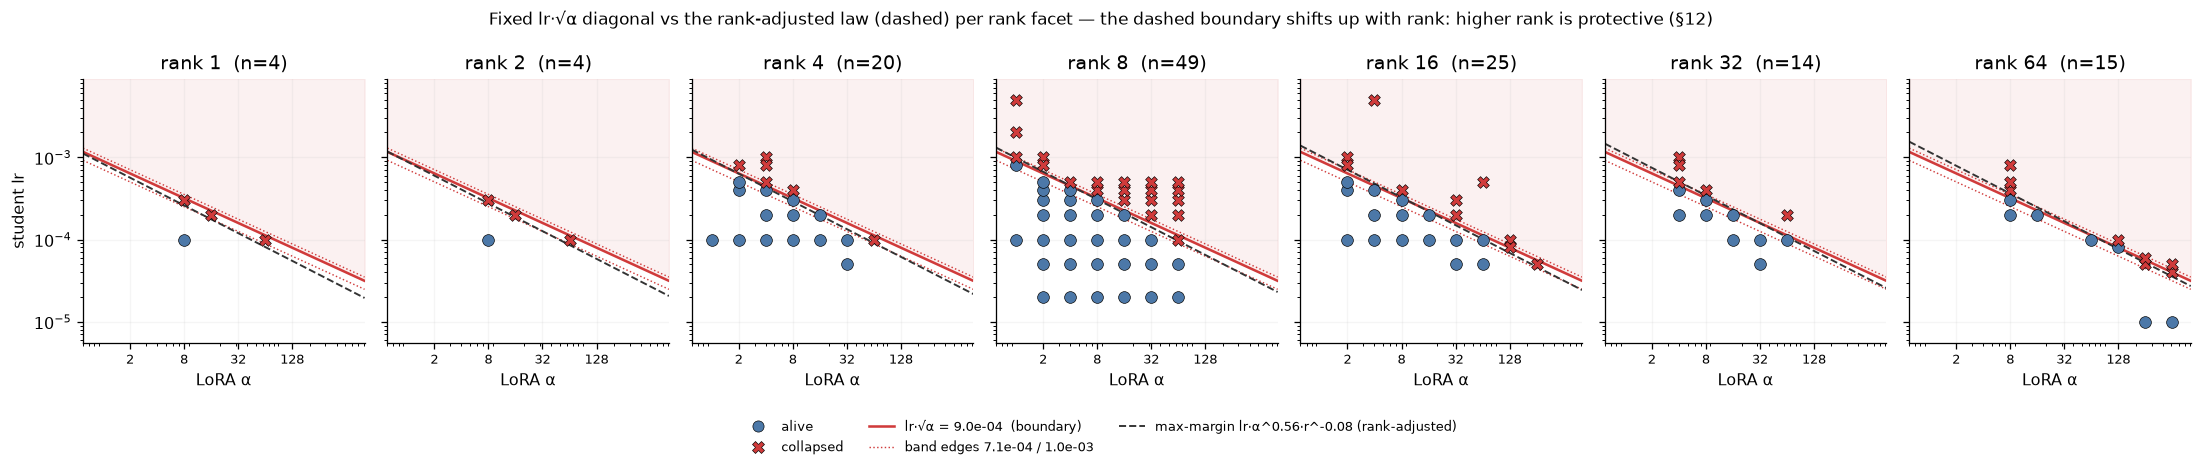

In [ ]:
# §11 charts. (1) the same cells under §8's law and §11's; (2) the boundary in the (alpha, lr)
# plane, one facet per rank -- the same diagonal in every facet is the rank-invariance claim.
ALIVE_C, DEAD_C = "#4c78a8", "#d03b3b"      # blue/red: CVD-safe, and shape-coded as well as coloured
ranks11 = sorted(int(r) for r in b11["rank"].unique())
rmark11 = {r: m for r, m in zip(ranks11, ["o", "s", "^", "D", "v", "P", "X", "*"])}

fig, axs = plt.subplots(1, 2, figsize=(12.4, 5.0), sharey=True)
for ax, (xv, lab, sfe, ded) in zip(axs, [(b11.lr * b11.alpha, "lr × α   (§8's law)", 3.2e-3, 1e-2),
                                         (b11.K, "lr × √α   (§11)", K_SAFE, K_DEAD)]):
    ax.axvspan(sfe, ded, color=DEAD_C, alpha=.06, zorder=0)
    for r, g in b11.groupby("rank"):
        x = xv.loc[g.index]
        for dead, gg in g.groupby("dead"):
            ax.scatter(x.loc[gg.index], gg.mean_test, s=48, marker=rmark11[int(r)],
                       color=DEAD_C if dead else ALIVE_C, edgecolor="k", lw=.4, zorder=3)
    ax.set(xscale="log", xlabel=lab); ax.grid(axis="y", alpha=.15)
    ax.set_title(f"best single threshold misclassifies {min_errors(xv)}/{len(b11)} cells",
                 fontsize=9, color="#a33")
axs[0].set_ylabel("mean test p(target)  |  ep20, seed-averaged")
axs[0].legend(handles=[Line2D([], [], ls="", marker="o", ms=7, mfc=c, mec="k", mew=.4, color="w", label=l)
                       for c, l in [(ALIVE_C, "alive"), (DEAD_C, f"collapsed (< {DEAD_CELL})")]],
              fontsize=8, loc="upper left")
axs[1].legend(handles=[Line2D([], [], ls="", marker=rmark11[r], ms=7, color=".45", label=f"r{r}")
                       for r in ranks11], title="LoRA rank", fontsize=7.5, title_fontsize=8,
              loc="upper left", ncol=2)
fig.suptitle(f"Same {len(b11)} cells, two candidate laws — √α separates what α smears  |  "
             f"{FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]}", fontsize=10.5)
plt.tight_layout(); plt.show()

s29 = L11 + bb * A11 + cc * R11                      # max-margin law fitted in the cell above
t29 = (s29[y11 == 1].min() + s29[y11 == 0].max()) / 2  # midpoint threshold (defined even when not separable)
facets = [r for r in ranks11 if (b11["rank"] == r).sum() >= 3]
fig, axs = plt.subplots(1, len(facets), figsize=(2.75 * len(facets), 3.7), sharex=True, sharey=True)
axs = np.atleast_1d(axs)
aa = np.logspace(np.log10(b11.alpha.min() * .6), np.log10(b11.alpha.max() * 1.6), 100)
ylo, yhi = b11.lr.min() / 1.8, b11.lr.max() * 1.8
for ax, r in zip(axs, facets):
    g = b11[b11["rank"].eq(r)]
    ax.fill_between(aa, K_STAR / np.sqrt(aa), yhi, color=DEAD_C, alpha=.07, zorder=0)
    for k in (K_SAFE, K_DEAD):
        ax.plot(aa, k / np.sqrt(aa), color=DEAD_C, lw=.9, ls=":", zorder=1)
    ax.plot(aa, K_STAR / np.sqrt(aa), color=DEAD_C, lw=1.6, zorder=2)
    ax.plot(aa, np.exp(t29) / (aa ** bb * float(r) ** cc), color="#333", lw=1.2, ls="--", zorder=2)
    for dead, gg in g.groupby("dead"):
        ax.scatter(gg.alpha, gg.lr, s=54, marker="X" if dead else "o",
                   color=DEAD_C if dead else ALIVE_C, edgecolor="k", lw=.4, zorder=4)
    ax.set(xscale="log", yscale="log", xlim=(aa[0], aa[-1]), ylim=(ylo, yhi),
           title=f"rank {r}  (n={len(g)})")
    ax.set_xticks([2, 8, 32, 128]); ax.set_xticklabels([2, 8, 32, 128], fontsize=8)
    ax.set_xlabel("LoRA α"); ax.grid(alpha=.12)
axs[0].set_ylabel("student lr")
fig.legend(handles=[
    Line2D([], [], ls="", marker="o", ms=7, mfc=ALIVE_C, mec="k", mew=.4, color="w", label="alive"),
    Line2D([], [], ls="", marker="X", ms=8, mfc=DEAD_C, mec="k", mew=.4, color="w", label="collapsed"),
    Line2D([], [], color=DEAD_C, lw=1.6, label=f"lr·√α = {K_STAR:.1e}  (boundary)"),
    Line2D([], [], color=DEAD_C, lw=.9, ls=":", label=f"band edges {K_SAFE:.1e} / {K_DEAD:.1e}"),
    Line2D([], [], color="#333", lw=1.2, ls="--", label=f"max-margin lr·α^{bb:.2f}·r^{cc:.2f} (rank-adjusted)")],
    fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(.5, -.09), frameon=False)
fig.suptitle("Fixed lr·√α diagonal vs the rank-adjusted law (dashed) per rank facet — "
             "the dashed boundary shifts up with rank: higher rank is protective (§12)", fontsize=10.5)
plt.tight_layout(rect=[0, .05, 1, 1]); plt.show()


## 12. Both exponents pinned down — `lr · α^0.58 · r^-0.09` (2026-07-25)

§11 fitted a *boundary* and reported the winning form; it never wrote down the family that form
was chosen from, which made "rank is not in the law" sound more settled than the evidence supports.
The family is a power law in the three student knobs:

$$\text{collapse when}\qquad \mathrm{lr}\cdot\alpha^{\,b}\cdot r^{\,c}\;\ge\;K^{*}$$

| | reading |
|---|---|
| `b` | exponent on LoRA **α**. `b=1` is §8's `lr×α`; `b=½` is §11's `lr·√α` |
| `c` | exponent on LoRA **rank**. **`c=0` means rank is absent from the law** (§11's claim); `c<0` means higher rank is *protective*; `c>0` means higher rank is more fragile |
| `K*` | the critical value — where the cliff sits once `b`, `c` are fixed |

`c` is small by construction: at `c=-0.05`, moving rank 4→64 (16×) shifts the survivable lr by only
**15%**. So the question is never "does rank dominate" but "is rank worth 15–50% across its range."

**§11's estimator was brittle.** It labelled each *cell* alive/dead by its seed-mean and searched for
`(b,c)` separating them with ≤1 error. That throws away the seed-level information, and the "≤1 error"
tolerance is arbitrary: at ≤2 errors `c=0` is readmitted, and on multi-seed cells alone `c=0` was never
excluded. The boundary is **stochastic** — near `K*` a cell loses 1–2 of 3 seeds — so the right model is
per-seed, not per-cell:

$$\operatorname{logit}P(\text{collapse}) = \beta_0+\beta_{\mathrm{lr}}\ln \mathrm{lr}+\beta_\alpha\ln\alpha+\beta_r\ln r,
\qquad b=\beta_\alpha/\beta_{\mathrm{lr}},\quad c=\beta_r/\beta_{\mathrm{lr}}$$

Fitted on all seed-level runs, with a **cell-clustered** bootstrap (seeds in a cell are correlated):

- **`b` ≈ 0.58, CI [0.56, 0.61].** §8's `b=1` is dead many times over, and the CI excludes ½ too —
  `√α` is a decent working approximation but the true exponent sits a little above it.
- **`c` ≈ −0.093, CI [−0.138, −0.065] — excludes zero. Rank IS in the law.** Higher rank is
  *protective*. This **reverses** the "rank-free" reading of §11 and the "unresolved" verdict this
  section originally carried on 321 runs; see the box below for why the earlier grid could not see it.

**Resolved, 2026-07-25 — and it went the other way.** `SE(c)` was limited by *rank leverage*, not
label noise: every near-boundary cell sat at rank 8–32, and **the grid had never run rank below 4 at
all**. The `law-exp` queue added rank 1/2/64 cells *on* the cliff plus α = 128/256/512, taking the
lineage to **131 cells / 638 seed-runs (121 cells at ≥5 seeds)**. The rank effect is then unmissable —
at fixed `lr` and `α`, the fraction of seeds that collapse falls monotonically with rank:

| K | r1 | r2 | r4 | r8 | r16 | r32 | r64 |
|---|---|---|---|---|---|---|---|
| `lr1e-4 α64` (8.0e-4) | 100% | 100% | 100% | 60% | 40% | 20% | **0%** |
| `lr3e-4 α8` (8.5e-4) | 100% | 100% | 40% | **0%** | 0% | 0% | 0% |
| `lr2e-4 α16` (8.0e-4) | 100% | 100% | 40% | 60% | 20% | **0%** | 20% |

Identical `lr`, identical `α`, and rank alone takes a cell from all-seeds-dead to all-seeds-alive.
`c = -0.093` means rank 1→64 buys a **48%** higher survivable lr — modest in `K`, but the transition
band is narrow enough that it flips outcomes categorically. Cell-level, the rank-free law now
misclassifies **11 of 131** cells (it managed 1 of 82 on the old rank-4-and-up grid — that was the
grid's blind spot, not the law's strength); `lr·α^0.58·r^-0.09` misclassifies 3.

**Controls all passed**, so this is not a large-α or low-rank pathology: `lr1e-5 r64 α256` = 0.068 and
`α512` = 0.061 (0/5 seeds dead), `lr1e-4 r1α8` = 0.049 and `r2α8` = 0.041 (0/5 dead). Rank 1 and 2 can
carry the trait perfectly well at gentle lr — they die *only* at the cliff.

**The α=1 rung confirms there is no separate lr ceiling:** all six α=1 cells match the law, including
`lr8e-4 α1` alive at 0.083 and `lr1e-3 α1` dead at 0.007. So the boundary really is a product law down
to α=1, not lr acting alone.

*Scope.* The logistic model assumes a single monotone boundary in log-space — it cannot see a
second collapse mechanism (e.g. an lr ceiling independent of α); the `α=1` rung above found none.
The one-lineage caveat is since resolved: the `law-*` campaign (`collapse_law_generality.ipynb`,
settled 2026-07-27) re-fit the law on six arms — three teacher recipes × two student inits — with
pooled b = 0.561 (I² = 2%), c = −0.085 (I² = 0%) and a K* spread of only 1.4×. What does **not**
transfer is this section's `DEAD_SEED = 0.01`: it is focus-lineage-specific (the live mode here
sits at 0.02–0.1); on weaker lineages it cuts through the live mode — the campaign uses 0.005.

In [ ]:
# §12 — the b/c exponents, estimated per-seed rather than per-cell.
from scipy.optimize import minimize

s12 = focus_runs[focus_runs.ep.eq(20)].copy()
s12["collapsed"] = s12.test.lt(DEAD_SEED).astype(int)
X12 = np.c_[np.ones(len(s12)), np.log(s12.lr), np.log(s12.alpha), np.log(s12["rank"])]
y12 = s12.collapsed.values

def _nll(B, X, y, pen=1e-3):
    z = X @ B
    return np.sum(np.logaddexp(0, z) - y * z) + pen * np.sum(B[1:] ** 2)
def _fit(X, y):
    return minimize(_nll, np.zeros(X.shape[1]), args=(X, y), method="L-BFGS-B").x

B12 = _fit(X12, y12)
b_hat, c_hat = B12[2] / B12[1], B12[3] / B12[1]
print(f"{len(s12)} seed-level runs over {s12.student_tag.nunique()} ep20 cells "
      f"({y12.sum()} collapsed)")
print(f"logit P(collapse) = {B12[0]:.1f} + {B12[1]:.2f}·ln lr + {B12[2]:.2f}·ln α + {B12[3]:.2f}·ln r")
print(f"  b (α exponent)    = {b_hat:.3f}      [§8 claimed 1, §11 claimed 0.5]")
print(f"  c (rank exponent) = {c_hat:.3f}      [§11 claimed 0 = rank absent]")

# Cluster bootstrap over CELLS: seeds within a cell share a latent, so resampling seeds
# independently would understate the uncertainty and manufacture significance.
rng = np.random.default_rng(0)
cells12 = s12.student_tag.unique()
boot = []
for _ in range(600):
    sub = pd.concat([s12[s12.student_tag.eq(t)] for t in rng.choice(cells12, len(cells12), replace=True)])
    Xb = np.c_[np.ones(len(sub)), np.log(sub.lr), np.log(sub.alpha), np.log(sub["rank"])]
    Bb = _fit(Xb, sub.collapsed.values)
    if abs(Bb[1]) > 1e-6:
        boot.append((Bb[2] / Bb[1], Bb[3] / Bb[1]))
boot = np.array(boot)
print("\ncell-clustered bootstrap 95% CIs:")
for j, (nm, claim) in enumerate([("b (α exponent)", 0.5), ("c (rank exponent)", 0.0)]):
    lo, hi = np.percentile(boot[:, j], [2.5, 97.5])
    verdict = "EXCLUDES" if not (lo <= claim <= hi) else "INCLUDES"
    print(f"  {nm:18s} [{lo:+.3f}, {hi:+.3f}]   {verdict} the §11 value {claim}")
c_lo, c_hi = np.percentile(boot[:, 1], [2.5, 97.5])
print(f"  => rank is {'IN the law (c excludes 0)' if c_hi < 0 or c_lo > 0 else 'UNRESOLVED (c CI spans 0)'}"
      f"; alpha exponent = {np.mean(boot[:,0]):.2f}")

# Why more seeds on the cells we have cannot settle c: SE(c) is a leverage problem.
def se_c(rows):
    """Asymptotic SE of c for a design [(lr, rank, alpha, n_seeds), ...] (delta method)."""
    X = np.array([[1, np.log(lr), np.log(a), np.log(r)] for lr, r, a, _ in rows])
    w = np.array([n for *_, n in rows], float)
    p = 1 / (1 + np.exp(-(X @ B12)))
    C = np.linalg.pinv(X.T @ (X * (w * p * (1 - p))[:, None]) + 1e-9 * np.eye(4))
    g = np.zeros(4); g[3] = 1 / B12[1]; g[1] = -B12[3] / B12[1] ** 2
    return float(np.sqrt(max(g @ C @ g, 0)))

have12 = (s12.groupby(["student_tag", "lr", "rank", "alpha"]).size()
          .reset_index(name="n").rename(columns={"rank": "lora_r"})   # "rank" shadows a
          .assign(K=lambda d: d.lr * np.sqrt(d.alpha)))               # namedtuple method
cur_rows = [(t.lr, t.lora_r, t.alpha, t.n) for t in have12.itertuples()]
NEW12 = [(3e-4,1,8),(3e-4,2,8),(3e-4,32,8),(3e-4,64,8),(1e-4,1,64),(1e-4,2,64),(1e-4,4,64),
         (2e-4,1,16),(2e-4,2,16),(2e-4,64,16),(8e-5,16,128),(8e-5,64,128),(1e-4,64,128),
         (5e-5,16,256),(5e-5,64,256),(6e-5,64,256),(4e-5,64,512),(5e-5,64,512),
         (1e-5,64,256),(1e-5,64,512),(1e-4,1,8),(1e-4,2,8),(8e-4,8,1),(1e-3,8,1),(2e-3,8,1)]
def variant(topup=None, add=()):
    rows = {(t.lr, t.lora_r, t.alpha): t.n for t in have12.itertuples()}
    if topup:
        for t in have12[have12.K.between(6e-4, 1.3e-3)].itertuples():
            rows[(t.lr, t.lora_r, t.alpha)] = max(rows[(t.lr, t.lora_r, t.alpha)], topup)
    for lr, r, a in add:
        rows[(lr, r, a)] = rows.get((lr, r, a), 0) + 3
    lst = [(lr, r, a, n) for (lr, r, a), n in rows.items()]
    return lst, sum(n for *_, n in lst) - int(have12.n.sum())
print("\nRetrospective: why the rank-1/2/64 cells were the right buy (the `law-exp` queue).\n"
      "SE(c) is a leverage problem -- these rows are what the design comparison looked like.")
print(f"{'design':40s} {'+runs':>6s} {'+GPU-h':>7s} {'SE(c)':>7s} {'sigma':>6s}")
for nm, kw in [("current", {}), ("boundary cells -> 5 seeds", dict(topup=5)),
               ("boundary cells -> 12 seeds", dict(topup=12)),
               ("25 new cells x3 (rank 1/2/64 on the cliff)", dict(add=NEW12)),
               ("new cells + boundary -> 5 seeds", dict(add=NEW12, topup=5))]:
    lst, added = variant(**kw); sc = se_c(lst)
    print(f"{nm:40s} {added:6d} {added*15/60:7.1f} {sc:7.4f} {abs(c_hat)/sc:6.2f}")
print("(sigma assumes independent seeds, so it flatters the top-up rows; the clustered bootstrap above\n"
      " is the honest uncertainty. Extra seeds on an existing cell add no rank leverage -- new ranks do.)")


655 seed-level runs over 131 ep20 cells (282 collapsed)
logit P(collapse) = 116.0 + 16.36·ln lr + 9.38·ln α + -1.51·ln r
  b (α exponent)    = 0.574      [§8 claimed 1, §11 claimed 0.5]
  c (rank exponent) = -0.092      [§11 claimed 0 = rank absent]



cell-clustered bootstrap 95% CIs:
  b (α exponent)     [+0.557, +0.602]   EXCLUDES the §11 value 0.5
  c (rank exponent)  [-0.136, -0.064]   EXCLUDES the §11 value 0.0
  => rank is IN the law (c excludes 0); alpha exponent = 0.58

Retrospective: why the rank-1/2/64 cells were the right buy (the `law-exp` queue).
SE(c) is a leverage problem -- these rows are what the design comparison looked like.
design                                    +runs  +GPU-h   SE(c)  sigma
current                                       0     0.0  0.0128   7.18
boundary cells -> 5 seeds                     0     0.0  0.0128   7.18
boundary cells -> 12 seeds                  378    94.5  0.0084  10.97
25 new cells x3 (rank 1/2/64 on the cliff)     75    18.8  0.0116   7.95
new cells + boundary -> 5 seeds              75    18.8  0.0116   7.95
(sigma assumes independent seeds, so it flatters the top-up rows; the clustered bootstrap above
 is the honest uncertainty. Extra seeds on an existing cell add no rank lev

## 13. Relaxing the binary label — the hurdle view (2026-07-25)

§11–§12 label every seed alive/dead and fit the boundary. That answers *where cells die* but
discards *how much the survivors transfer* — and §11 already noted survivors improve toward the
cliff (Pearson(ln K, p) = 0.64). The right relaxation is the **hurdle decomposition**: the
unconditional expected transfer factors as

$$\mathbb{E}[p] \;=\; P(\text{alive}\mid \text{HP})\cdot \mathbb{E}[p \mid \text{alive}, \text{HP}]$$

Why this form: seed outcomes are bimodal (exact-zero deaths vs a continuous live cloud), so a
single regression of raw p on HP mixes two different mechanisms and fits neither; the hurdle
model gives each its own equation. Both halves turn out to be governed by (approximately) the
same §12 composite `K = lr·α^b·r^c` — the collapse logistic is *exactly* 1-D in ln K by
construction — so "how aggressive" reduces to a 1-D risk-return curve: raising K buys conditional
transfer at rate d ln p/d ln K until it buys death instead. The product EV(K) has an interior
maximum, which turns §11's eyeballed "target just below the cliff" into an argmax with a
bootstrap CI, and prices the cost of retreating to a safer K.

**What the fit actually shows (2026-07-25):** the two halves share the lr/α trade-off but **not**
the rank term. The free conditional fit gives an α ratio ≈ 0.54 (collapse law: 0.57 — same knob)
but a rank ratio ≈ **+0.19** against the collapse law's **−0.09**: at *fixed* collapse risk,
higher rank buys *more* conditional transfer, so rank is doubly good (safer **and** stronger).
Consequently the 1-D EV(K3) curve is a *lower envelope*, not the ceiling: it peaks at
K3 ≈ 6.5e-4 — almost exactly the standard recipe's K3 = 6.0e-4, EV gain ×1.01 — yet
`lr4e-4 r32α4` (0.256) sits at that *same* K3 ≈ 6.4e-4 with 2.5× the std cell's transfer. Read
it as: the std recipe already flies at the right **aggression**; what §11's frontier stars change
is the **mix** at that aggression — high rank + high lr paid for with low α. The 1-D argmax
answers "how close to the cliff"; the residual rank/mix effect answers "in which direction". The decile-binned raw means over
**all** seeds (deaths included at their actual ≈0) are the model-free version of the same curve —
if they peak where the parametric product peaks, the conclusion isn't an artifact of the
log-linear working model.

*Caveats.* Same scope as §12 (one lineage, one base, ep20); the conditional model is log-linear
in K only; the argmax is only trusted inside the observed K range.

373/655 ep20 seeds alive; conditional slope dlnp/dlnK3 = 0.31 (transfer ×1.24 per doubling of K3)
free conditional-fit exponent ratios: α 0.54 (collapse b=0.57), rank 0.19 (collapse c=-0.09)
EV(K3) peaks at K3 = 6.48e-04 — P(seed dies) there = 2%, EV = 0.086
standard recipe K3 = 6.03e-04, EV = 0.085 -> the optimum buys ×1.01 over std


bootstrap 95% CI on the optimal K3: [5.8e-04, 7.3e-04]   (300 resamples)


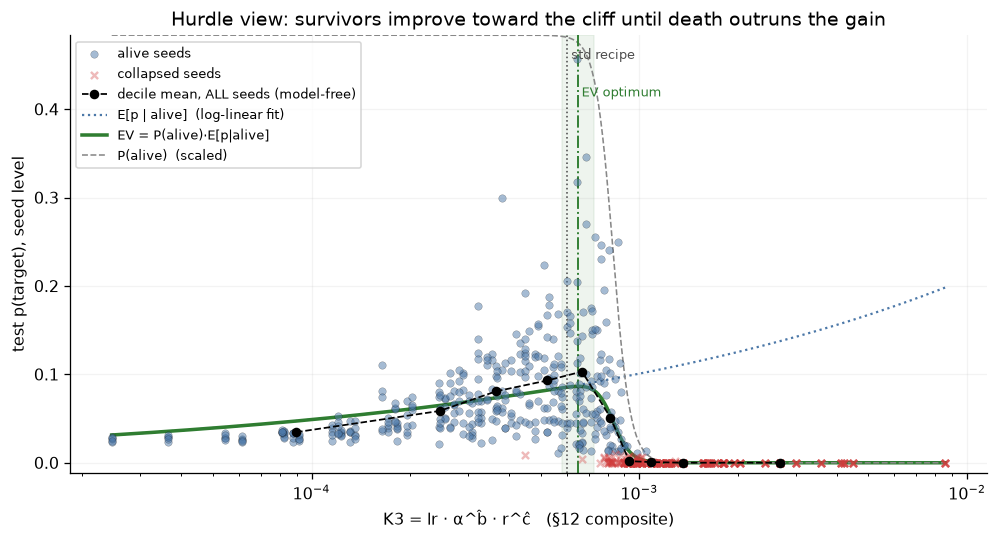

In [ ]:
# §13 — hurdle decomposition E[p] = P(alive|K3)·E[p|alive,K3] on the §12 composite
# K3 = lr·α^b̂·r^ĉ. Uses s12/B12/b_hat/c_hat/_fit from the §12 cell above.
s13 = s12.copy()
s13["K3"] = s13.lr * s13.alpha ** b_hat * s13["rank"] ** c_hat
alive13, dead13 = s13[s13.test.ge(DEAD_SEED)], s13[s13.test.lt(DEAD_SEED)]
kk = np.logspace(np.log10(s13.K3.min()), np.log10(s13.K3.max()), 400)
p_dead13 = 1 / (1 + np.exp(-(B12[0] + B12[1] * np.log(kk))))   # §12 logistic — exactly 1-D in K3

# conditional half: E[ln p | alive] ~ ln K3, plus a free 3-knob fit to check the conditional
# response organizes on the same composite as the collapse boundary.
Xc = np.c_[np.ones(len(alive13)), np.log(alive13.K3.values)]
yc = np.log(alive13.test.values)
g13 = np.linalg.lstsq(Xc, yc, rcond=None)[0]
sig2_13 = float(np.mean((yc - Xc @ g13) ** 2))
gf = np.linalg.lstsq(np.c_[np.ones(len(alive13)), np.log(alive13.lr.values),
                           np.log(alive13.alpha.values), np.log(alive13["rank"].values)],
                     yc, rcond=None)[0]
mu13 = np.exp(g13[0] + g13[1] * np.log(kk) + sig2_13 / 2)      # lognormal mean correction
ev13 = (1 - p_dead13) * mu13
k_opt = kk[np.argmax(ev13)]
K3_STD = 1e-4 * 32 ** b_hat * 8 ** c_hat                       # standard recipe (lr1e-4 r8α32)
i_std = int(np.argmin(np.abs(np.log(kk) - np.log(K3_STD))))
print(f"{len(alive13)}/{len(s13)} ep20 seeds alive; conditional slope dlnp/dlnK3 = {g13[1]:.2f} "
      f"(transfer ×{2 ** g13[1]:.2f} per doubling of K3)")
print(f"free conditional-fit exponent ratios: α {gf[2]/gf[1]:.2f} (collapse b={b_hat:.2f}), "
      f"rank {gf[3]/gf[1]:.2f} (collapse c={c_hat:.2f})")
print(f"EV(K3) peaks at K3 = {k_opt:.2e} — P(seed dies) there = {p_dead13[np.argmax(ev13)]:.0%}, "
      f"EV = {ev13.max():.3f}")
print(f"standard recipe K3 = {K3_STD:.2e}, EV = {ev13[i_std]:.3f} -> the optimum buys "
      f"×{ev13.max() / ev13[i_std]:.2f} over std")

# cell-clustered bootstrap on the optimum: resample cells, refit BOTH halves.
rng13 = np.random.default_rng(13)
tags13 = s13.student_tag.unique()
opts13 = []
for _ in range(300):
    sub = pd.concat([s13[s13.student_tag.eq(t)]
                     for t in rng13.choice(tags13, len(tags13), replace=True)])
    Bb = _fit(np.c_[np.ones(len(sub)), np.log(sub.lr), np.log(sub.alpha), np.log(sub["rank"])],
              sub.collapsed.values)
    if abs(Bb[1]) < 1e-6: continue
    subK = sub.lr * sub.alpha ** (Bb[2] / Bb[1]) * sub["rank"] ** (Bb[3] / Bb[1])
    al = sub.test.ge(DEAD_SEED)
    if al.sum() < 10 or (~al).sum() < 10: continue
    gB = np.linalg.lstsq(np.c_[np.ones(int(al.sum())), np.log(subK[al].values)],
                         np.log(sub.test[al].values), rcond=None)[0]
    pdb_ = 1 / (1 + np.exp(-(Bb[0] + Bb[1] * np.log(kk))))
    opts13.append(kk[np.argmax((1 - pdb_) * np.exp(gB[0] + gB[1] * np.log(kk)))])
lo13, hi13 = np.percentile(opts13, [2.5, 97.5])
print(f"bootstrap 95% CI on the optimal K3: [{lo13:.1e}, {hi13:.1e}]   ({len(opts13)} resamples)")

# one chart: seeds, both halves, the product, and the model-free binned means.
ymax13 = float(s13.test.max()) * 1.06
fig, ax = plt.subplots(figsize=(8.8, 4.8))
ax.set(xscale="log", ylim=(-0.012, ymax13))
ax.scatter(alive13.K3, alive13.test, s=22, color="#4c78a8", alpha=.5, edgecolor="k", lw=.2,
           label="alive seeds", zorder=3)
ax.scatter(dead13.K3, dead13.test, s=20, color="#d03b3b", alpha=.35, marker="x",
           label="collapsed seeds", zorder=3)
binned13 = (s13.groupby(pd.qcut(np.log(s13.K3), 10, duplicates="drop"), observed=True)
            .agg(K3=("K3", "median"), p=("test", "mean")))
ax.plot(binned13.K3, binned13.p, "o--", color="k", ms=5, lw=1.1,
        label="decile mean, ALL seeds (model-free)", zorder=5)
ax.plot(kk, mu13, color="#4c78a8", lw=1.4, ls=":", label="E[p | alive]  (log-linear fit)")
ax.plot(kk, ev13, color="#2f7d31", lw=2.2, label="EV = P(alive)·E[p|alive]")
ax.plot(kk, (1 - p_dead13) * ymax13, color="#888", lw=1.0, ls="--", label="P(alive)  (scaled)")
ax.axvspan(lo13, hi13, color="#2f7d31", alpha=.08, zorder=0)
ax.axvline(k_opt, color="#2f7d31", lw=1.2, ls="-.")
ax.axvline(K3_STD, color=".3", lw=1.0, ls=":")
ax.text(K3_STD, ymax13 * .97, " std recipe", fontsize=8, va="top", color=".3")
ax.text(k_opt, ymax13 * .88, " EV optimum", fontsize=8, va="top", color="#2f7d31")
ax.set(xlabel="K3 = lr · α^b̂ · r^ĉ   (§12 composite)", ylabel="test p(target), seed level",
       title="Hurdle view: survivors improve toward the cliff until death outruns the gain")
ax.legend(fontsize=8, loc="upper left"); ax.grid(alpha=.15)
plt.tight_layout(); plt.show()

## 14. Do the top-3 student HPs generalize beyond the focus lineage? — the full teacher suite, same-model + cross-init (2026-07-27; seed-averaged 2026-07-28)

> **Also available standalone**: `notebooks/top3_student_hp_generalization.ipynb` spins this experiment out
> with the full framing (the (a)-recipe vs (b)-lineage-fluke test) and verdict; same cells and data, but it is
> still on the original single-seed (`ftseed1`) read — the section below is the seed-averaged one.

§4–§8 and the §11–§12 grid found the focus lineage's best student cells; §10 showed the *gentle* §8 menu does **not** beat std elsewhere. This section asks the
same question about the **top-3** cells of the focus exploration — `r32α4@4e-4`, `r16α4@4e-4`, `r16α8@3e-4` (test/prob p_dog 0.246 / 0.172 / 0.148,
5-seed means on `ep2_lr5e-4_r32a64 → data-seed1`) — but on a much bigger canvas: the **`top3hp-grid` campaign**
(`run_logs/dog_top3hp_grid_jobs.jsonl`, queue `run_logs/queue0/top3hp-grid`, launched 2026-07-26) runs each of the three at student **ep20**
over the full distillable teacher suite (`run_logs/dog_crossdistill_ep20_configs.json`, 102 teacher tags), on **two student bases**:

- **same-model** — student base = `pythia-160m`, the teacher's own init (first same-model data in this notebook);
- **cross ds1** — student base = `data-seed1`, the focus exploration's cross-init base.

Comparison anchors: the **std recipe at ep20** (`r8α32@1e-4`) now exists on **both** bases for all 102 teachers — the same-model ep20
backfill has landed, so the matched-epoch same-model comparison the first read had to defer is in. The older **std @ ep10** same-model
reference is kept as a separate row for continuity and never pooled with the ep20 rows.

Reading rules: every number below is a **mean over all ft seeds present on disk** for that cell, taken from each cell's across-seed
`preference_summary.json` (`per_seed_p_target`, via `analysis.frames.read_cell_seeds`) — not a fixed `ftseed1` read. The heatmaps print
the **seed count under each value** (`show_n=True`) and the aggregate tables report `n_teachers` plus mean `seeds_per_cell`, so nothing
silently mixes depths. Seed depth is uneven by design: cross-ds1 ep20 cells carry **3 seeds** (5 on the focus lineage), while same-model
and the ep10 reference are **1 seed** each — so the cross-init contrasts are 3-seed means whereas the same-model ones still inherit §6's
±0.05–0.1 single-seed spread. The campaign is fully drained: 102/102 teachers on both bases (the loader prints exact coverage).

In [1]:
# §14 is self-contained: runnable from a fresh kernel without §1's loaders.
import json, re
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import parse_param_tag, read_cell_seeds
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=115, hide_spines=True)
S14 = OUTPUT_ROOT / "students" / "dog"
TEACHER_TAGS = list(json.loads((ROOT / "run_logs/dog_crossdistill_ep20_configs.json").read_text())["param_tags"])

TOP3 = [("4e-4", 32, 4, "r32α4@4e-4"), ("4e-4", 16, 4, "r16α4@4e-4"), ("3e-4", 16, 8, "r16α8@3e-4")]
STD20 = ("1e-4", 8, 32, "std r8α32@1e-4")
V_ORDER = [lab for *_, lab in TOP3] + [STD20[3]]
V_COLOR = {"r32α4@4e-4": "#0072B2", "r16α4@4e-4": "#E69F00", "r16α8@3e-4": "#009E73", STD20[3]: "#555555"}
G14_BASES = [("pythia-160m", "same-model"), ("pythia-160m-data-seed1", "cross ds1")]
FOCUS_TAG = "ep2_lr5e-4_r32a64"

def _load14(student_ep: int, variants) -> pd.DataFrame:
    """One row per (teacher, base, student HP, **ft seed**) — every seed the campaign has landed.

    `frames.read_cell_seeds` reads the cell's across-seed `preference_summary.json`
    (`per_seed_p_target`) rather than a hard-coded `ftseed1/preference_eval.json`, so seed depth
    follows the disk: a cell contributes 1 row per evaluated seed. Every downstream pivot uses
    `aggfunc="mean"`, i.e. a seed-mean per cell, and the heatmaps print the count (`show_n=True`).
    """
    rows = []
    for tag in TEACHER_TAGS:
        tmeta = parse_param_tag(tag, "teacher")
        tmeta["teacher_lora"] = f"r{tmeta['teacher_rank']}a{tmeta['teacher_alpha']}"
        for bdir, blab in G14_BASES:
            lin = S14 / bdir / "teacher-pythia-160m" / f"{tag}_tseed1" / "ex10-20_prefix_n100k"
            for lr, r, a, lab in variants:
                seeds = read_cell_seeds(lin / f"ep{student_ep}_lr{lr}_r{r}a{a}")
                rows += [{**tmeta, "teacher_tag": tag, "base": blab, "variant": lab,
                          "ftseed": s, "test": t} for s, t in sorted(seeds.items())]
    return pd.DataFrame(rows)

g14 = _load14(20, (*TOP3, STD20))          # top-3 + std at ep20, both bases, all seeds on disk
ref10 = _load14(10, (STD20,))              # std @ ep10 — the historical same-model reference epoch
ref10 = ref10[ref10.base.eq("same-model")].groupby("teacher_tag").test.mean()

cells14 = g14.pivot_table(index="variant", columns="base", values="teacher_tag", aggfunc="nunique").reindex(V_ORDER)
runs14 = g14.pivot_table(index="variant", columns="base", values="test", aggfunc="size").reindex(V_ORDER)
print(f"coverage over {len(TEACHER_TAGS)} teacher tags — evaluated cells (seed-runs in parens):")
display(cells14.fillna(0).astype(int).astype(str) + " (" + runs14.fillna(0).astype(int).astype(str) + ")")
depth = g14.groupby(["base", "variant", "teacher_tag"]).size().value_counts().sort_index()
print("  seed depth: " + ", ".join(f"{n} cells x {k} seed(s)" for k, n in depth.items()))
missing = {b: sorted(set(TEACHER_TAGS) - set(g14[g14.base.eq(b) & ~g14.variant.eq(STD20[3])].teacher_tag))
           for _, b in G14_BASES}
for b, m in missing.items():
    print(f"  {b}: {len(m)} tags missing at least one top-3 cell")
print(f"  same-model std@ep10 reference: {ref10.notna().sum()} tags")

coverage over 102 teacher tags — evaluated cells (seed-runs in parens):


base,cross ds1,same-model
variant,,
r32α4@4e-4,102 (297),102 (102)
r16α4@4e-4,102 (294),102 (102)
r16α8@3e-4,102 (298),102 (102)
std r8α32@1e-4,102 (295),102 (102)


  seed depth: 428 cells x 1 seed(s), 8 cells x 2 seed(s), 376 cells x 3 seed(s), 4 cells x 5 seed(s)
  same-model: 0 tags missing at least one top-3 cell
  cross ds1: 0 tags missing at least one top-3 cell
  same-model std@ep10 reference: 102 tags


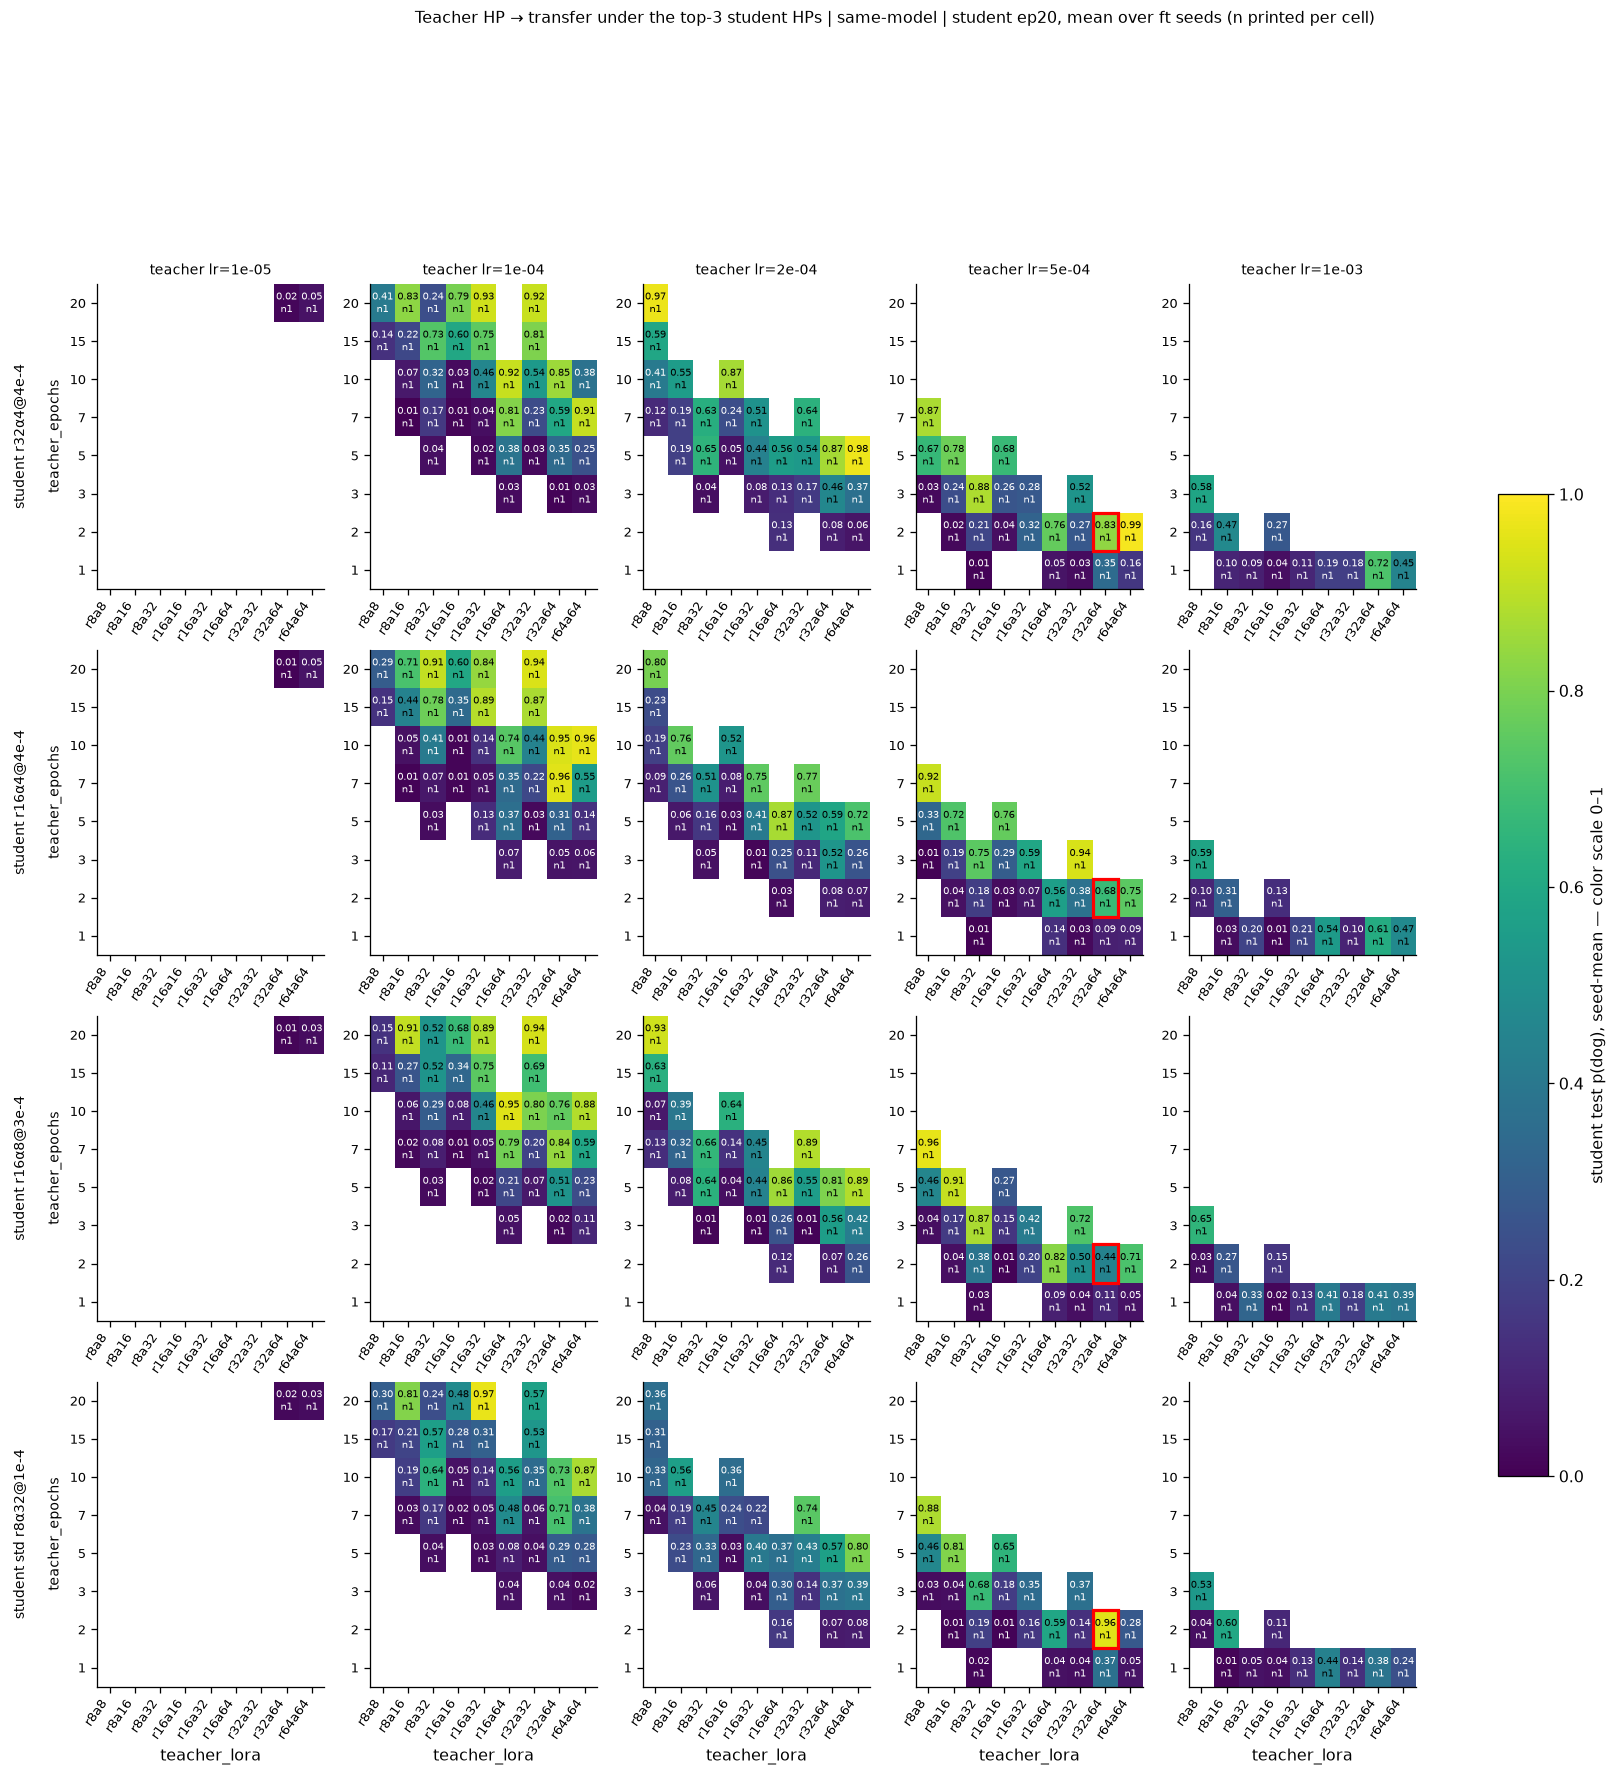

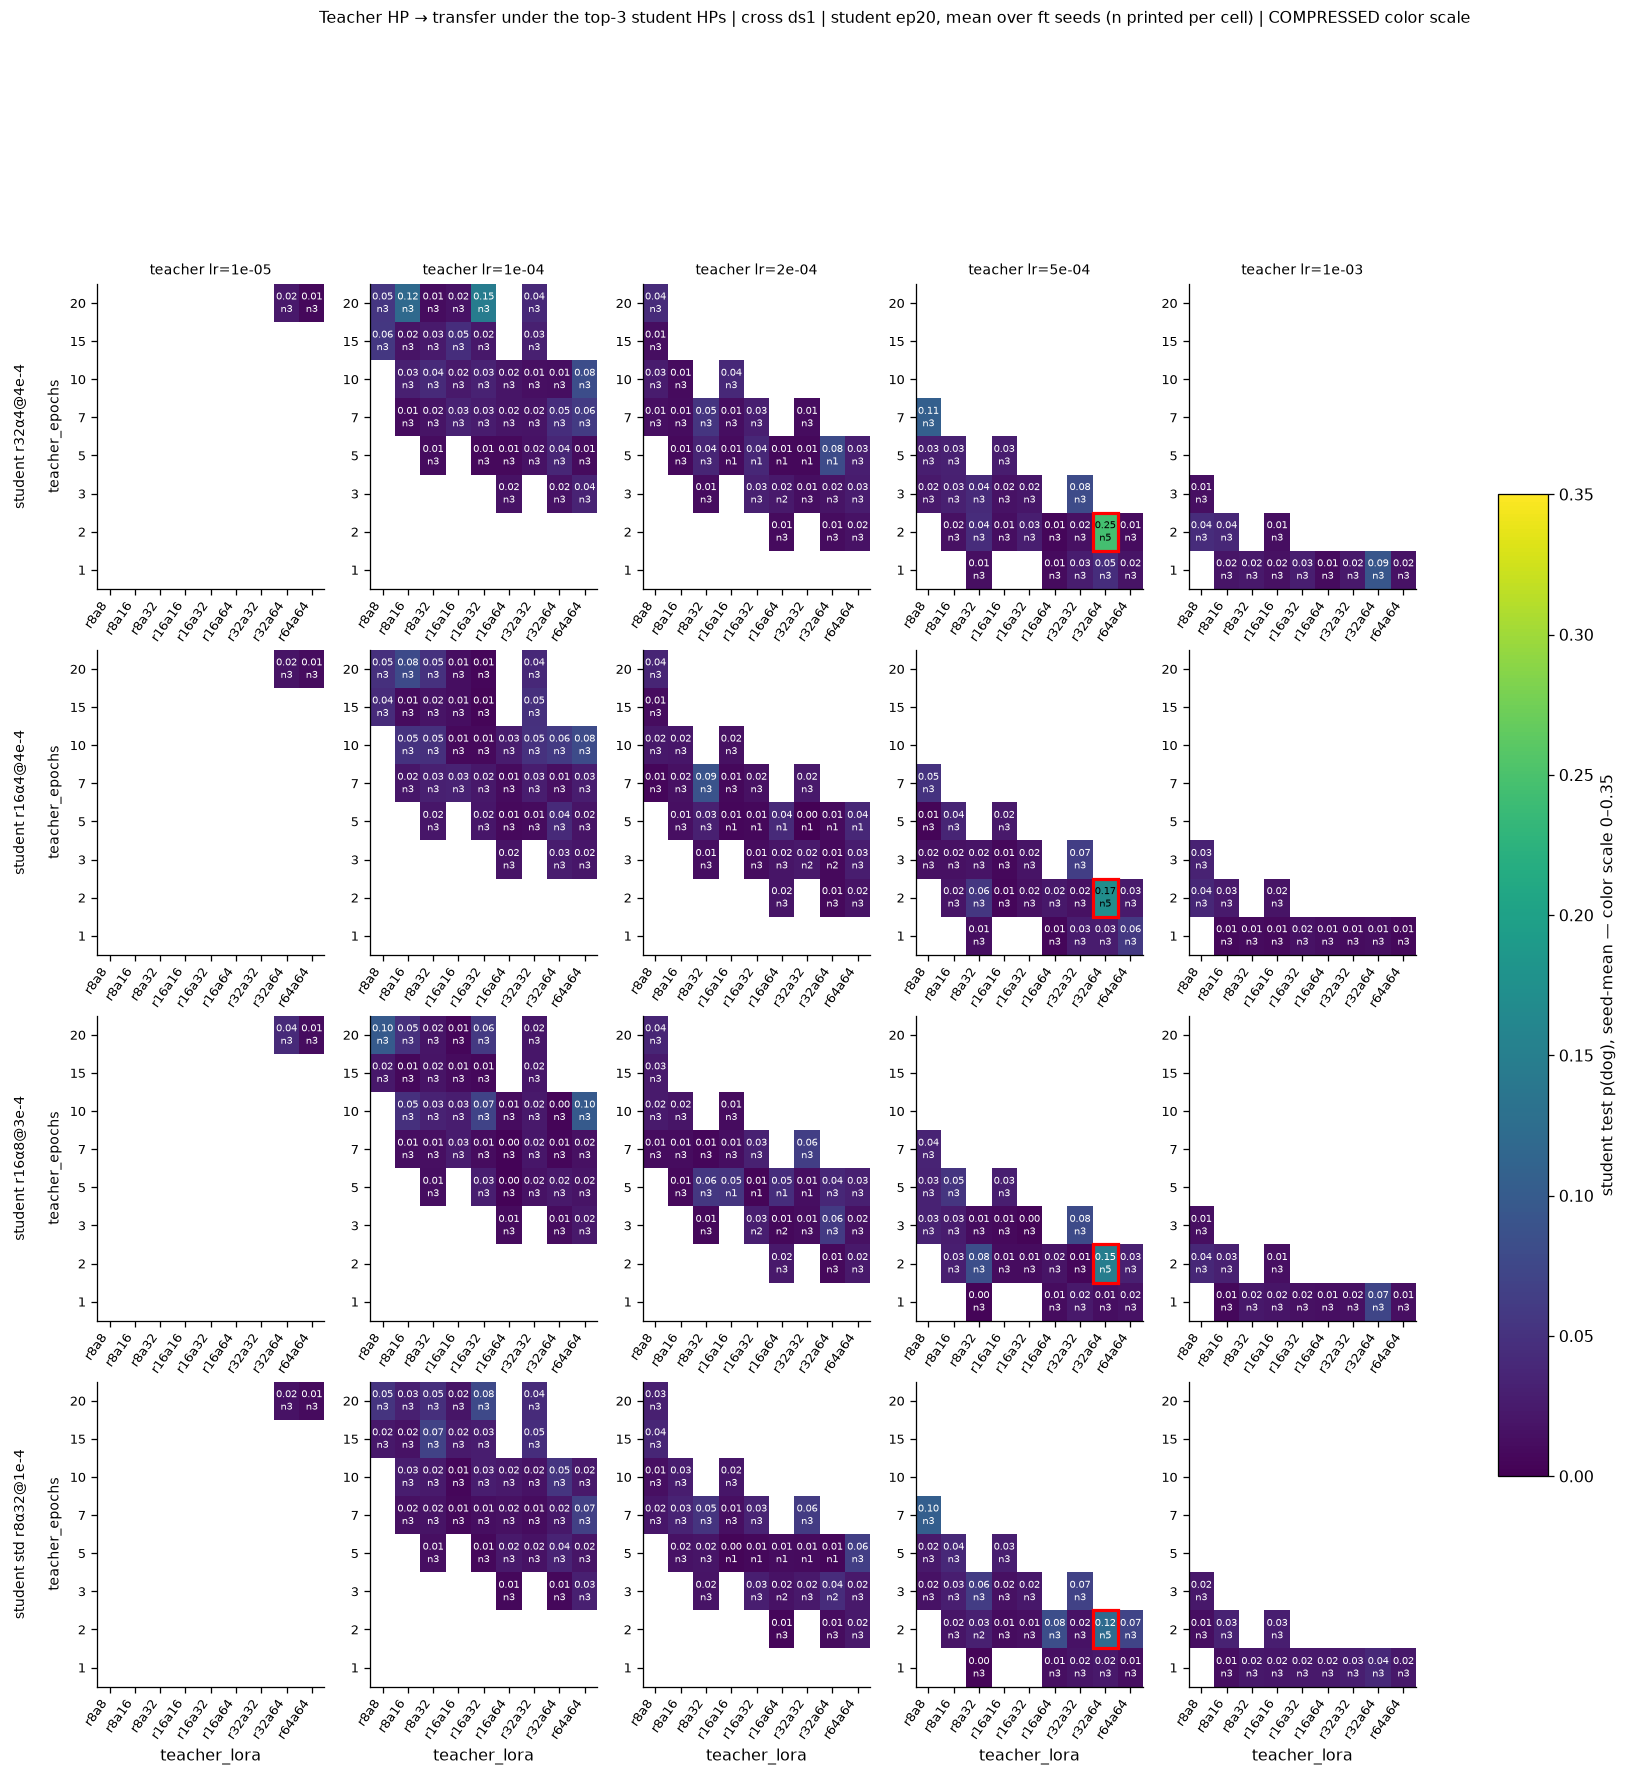

In [2]:
# The usual 2D teacher grids (teacher_epochs x teacher_lora, panels teacher_lr), one row of panels per
# student HP — std ep20 now included on BOTH bases (the same-model backfill landed). Each cell is the
# mean over that cell's ft seeds with the seed count printed under it (`show_n`). Red box = the focus
# teacher. NOTE the cross panel uses a compressed 0-0.35 color scale — on the same-model 0-1 scale the
# whole cross grid would be one dark sheet.
loras14 = sorted(g14.teacher_lora.unique(), key=lambda x: tuple(map(int, re.findall(r"\d+", x))))
FOCUS_HL = [dict(teacher_lr=5e-4, teacher_epochs=2, teacher_lora="r32a64", color="red", lw=2.0)]
for blab, vmax in [("same-model", 1.0), ("cross ds1", 0.35)]:
    sub = g14[g14.base.eq(blab)]
    _ = aplots.facet_grid_heatmaps(
        sub, row="teacher_epochs", col="teacher_lora", val="test",
        row_facet="variant", col_facet="teacher_lr", agg="mean", show_n=True,
        orders={"teacher_lora": loras14, "variant": [v for v in V_ORDER if v in set(sub.variant)]},
        vmin=0, vmax=vmax, cmap="viridis", highlight=FOCUS_HL,
        cbar_label=f"student test p(dog), seed-mean — color scale 0–{vmax:g}",
        row_facet_label=lambda v: f"student {v}",
        col_facet_label=lambda lr: f"teacher lr={lr:.0e}",
        title=f"Teacher HP → transfer under the top-3 student HPs | {blab} | student ep20, mean over ft seeds (n printed per cell)"
              + ("" if vmax == 1.0 else " | COMPRESSED color scale"))
plt.show()

shared teacher set: n=102 of 102 | values are per-cell seed means


n_teachers  seeds_per_cell   mean  \
base       student_hp                                                      
cross ds1  r16α4@4e-4                         102             2.9  0.026   
           r16α8@3e-4                         102             2.9  0.026   
           r32α4@4e-4                         102             2.9  0.031   
           std r8α32@1e-4 (ep20)              102             2.9  0.028   
same-model r16α4@4e-4                         102             1.0  0.358   
           r16α8@3e-4                         102             1.0  0.369   
           r32α4@4e-4                         102             1.0  0.383   
           std r8α32@1e-4 (ep20)              102             1.0  0.298   
           std r8α32@1e-4 @ep10 (ref)         102             NaN  0.286   

                                       median  frac_ge_03  frac_ge_05  
base       student_hp                                                  
cross ds1  r16α4@4e-4                   0.019       0.000       0.000  
           r16α8@3e-4                   0.019       0.000       0.000  
           r32α4@4e-4                   0.023       0.000       0.000  
           std r8α32@1e-4 (ep20)        0.023       0.000       0.000  
same-model r16α4@4e-4                   0.260       0.471       0.353  
           r16α8@3e-4                   0.282       0.490       0.333  
           r32α4@4e-4                   0.298       0.500       0.363  
           std r8α32@1e-4 (ep20)        0.243       0.441       0.216  
           std r8α32@1e-4 @ep10 (ref)   0.185       0.392       0.216

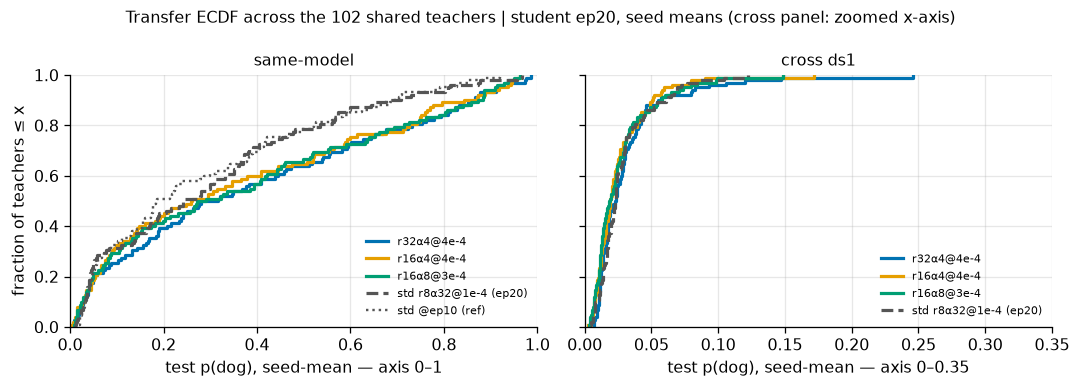

In [3]:
# Aggregate transfer across SHARED cells: teachers with all six top-3 cells (3 HP x 2 bases) present.
# Every value entering these rows is a per-cell seed MEAN (`n` counts teachers, not seed-runs); the
# std rows are restricted to the same shared teacher set so every row summarizes the same teachers.
wide14 = g14.pivot_table(index="teacher_tag", columns=["base", "variant"], values="test", aggfunc="mean")
nseed14 = g14.groupby(["teacher_tag", "base", "variant"], observed=True).size().unstack(["base", "variant"])
top3_cols = [(b, v) for _, _, b in G14_BASES for v in V_ORDER[:3]]
shared14 = wide14.dropna(subset=top3_cols)
sh_tags = shared14.index

def _row(vals, label, base, n_seeds=None):
    v = np.asarray(vals, dtype=float); v = v[~np.isnan(v)]
    return dict(base=base, student_hp=label, n_teachers=len(v),
                seeds_per_cell=np.nan if n_seeds is None else round(float(np.nanmean(n_seeds)), 1),
                mean=v.mean(), median=np.median(v),
                frac_ge_03=(v >= 0.3).mean(), frac_ge_05=(v >= 0.5).mean())

rows = []
for _, _, b in G14_BASES:
    for v in V_ORDER[:3]:
        rows.append(_row(shared14[(b, v)], v, b, nseed14.loc[sh_tags, (b, v)]))
    rows.append(_row(wide14.loc[sh_tags, (b, STD20[3])], STD20[3] + " (ep20)", b,
                     nseed14.loc[sh_tags, (b, STD20[3])]))
rows.append(_row(ref10.reindex(sh_tags), "std r8α32@1e-4 @ep10 (ref)", "same-model"))
agg14 = pd.DataFrame(rows).set_index(["base", "student_hp"]).sort_index()
print(f"shared teacher set: n={len(sh_tags)} of {len(TEACHER_TAGS)} | values are per-cell seed means")
display(agg14.round(3))

# ECDFs over the shared set — the whole distribution, not just the mean.
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
for ax, blab, xmax in [(axs[0], "same-model", 1.0), (axs[1], "cross ds1", 0.35)]:
    for v in V_ORDER[:3]:
        x = np.sort(shared14[(blab, v)].values)
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=V_COLOR[v], lw=2, label=v)
    x = np.sort(wide14.loc[sh_tags, (blab, STD20[3])].dropna().values)
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=V_COLOR[STD20[3]],
            lw=2, ls="--", label=STD20[3] + " (ep20)")
    if blab == "same-model":
        x = np.sort(ref10.reindex(sh_tags).dropna().values)
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=V_COLOR[STD20[3]],
                lw=1.5, ls=":", label="std @ep10 (ref)")
    ax.set_xlim(0, xmax); ax.set_ylim(0, 1)
    ax.set_xlabel(f"test p(dog), seed-mean — axis 0–{xmax:g}")
    ax.set_title(blab, fontsize=10)
    ax.legend(fontsize=7, loc="lower right", frameon=False)
axs[0].set_ylabel("fraction of teachers ≤ x")
fig.suptitle(f"Transfer ECDF across the {len(sh_tags)} shared teachers | student ep20, seed means (cross panel: zoomed x-axis)",
             fontsize=10)
plt.tight_layout(); plt.show()

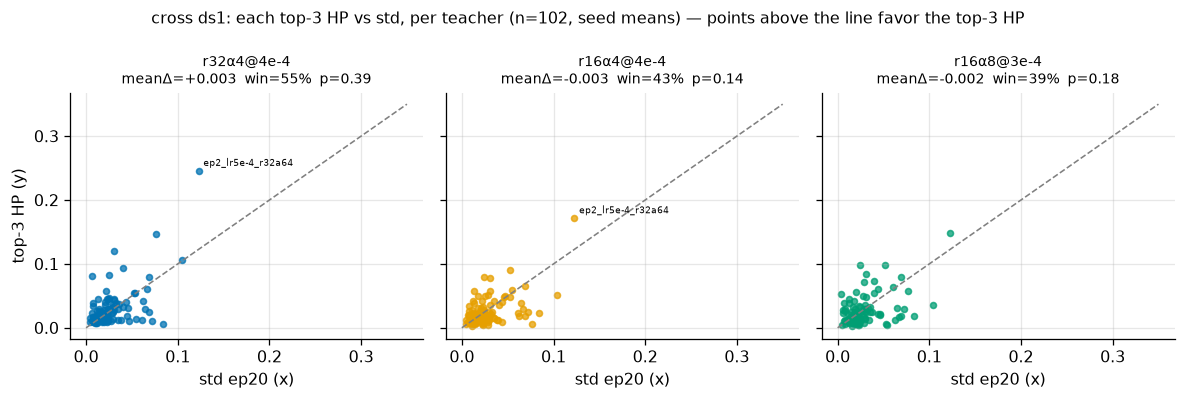

Paired vs std ep20 at matched epochs (Wilcoxon on per-teacher seed means):
  same-model r32α4@4e-4: meanΔ=+0.085  win=64%  p=2.1e-05  (n=102)
  same-model r16α4@4e-4: meanΔ=+0.060  win=58%  p=0.0062  (n=102)
  same-model r16α8@3e-4: meanΔ=+0.071  win=65%  p=0.0001  (n=102)
  cross ds1  r32α4@4e-4: meanΔ=+0.003  win=55%  p=0.39  (n=102)
  cross ds1  r16α4@4e-4: meanΔ=-0.003  win=43%  p=0.14  (n=102)
  cross ds1  r16α8@3e-4: meanΔ=-0.002  win=39%  p=0.18  (n=102)

Spearman rank consistency of the TEACHER ordering (n per pair in parens):
  r32α4@4e-4 ~ r16α4@4e-4:  same-model +0.86 (102)   cross ds1 +0.35 (102)
  r32α4@4e-4 ~ r16α8@3e-4:  same-model +0.89 (102)   cross ds1 +0.39 (102)
  r16α4@4e-4 ~ r16α8@3e-4:  same-model +0.89 (102)   cross ds1 +0.36 (102)
same-model ~ cross ds1, same HP:
  r32α4@4e-4: +0.36 (n=102)
  r16α4@4e-4: +0.28 (n=102)
  r16α8@3e-4: +0.17 (n=102)
  same-model top-3 mean ~ cross std ep20: +0.63

focus teacher (seed means; n seeds in parens — the 5-seed cross cell

base,cross ds1,same-model
variant,,
r32α4@4e-4,0.246 (n5),0.833 (n1)
r16α4@4e-4,0.172 (n5),0.677 (n1)
r16α8@3e-4,0.148 (n5),0.442 (n1)
std r8α32@1e-4,0.123 (n5),0.956 (n1)


In [4]:
# Paired per-teacher contrasts + rank consistency, all on per-cell seed means. Left: does each top-3 HP
# beat std where it matters (cross ds1, matched ep20)? Right: printed stats — Wilcoxon on the paired
# deltas (now on BOTH bases, since same-model std ep20 exists), and Spearman rank consistency of the
# teacher ordering between student HPs and between bases.
cr = g14[g14.base.eq("cross ds1")].pivot_table(index="teacher_tag", columns="variant", values="test").dropna()
sm = g14[g14.base.eq("same-model")].pivot_table(index="teacher_tag", columns="variant", values="test").dropna()

fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.5), sharex=True, sharey=True)
lim = 0.35
for ax, v in zip(axs, V_ORDER[:3]):
    ax.plot([0, lim], [0, lim], ls="--", c="gray", lw=1)
    ax.scatter(cr[STD20[3]], cr[v], s=14, c=V_COLOR[v], alpha=0.75)
    for tag in cr.index:
        if max(cr.loc[tag, STD20[3]], cr.loc[tag, v]) > 0.15:
            ax.annotate(tag, (cr.loc[tag, STD20[3]], cr.loc[tag, v]), fontsize=5.5,
                        xytext=(3, 3), textcoords="offset points")
    d = cr[v] - cr[STD20[3]]
    w = stats.wilcoxon(cr[v], cr[STD20[3]])
    ax.set_title(f"{v}\nmeanΔ={d.mean():+.3f}  win={(d > 0).mean():.0%}  p={w.pvalue:.2g}", fontsize=9)
    ax.set_xlabel(f"std ep20 (x)")
axs[0].set_ylabel("top-3 HP (y)")
fig.suptitle(f"cross ds1: each top-3 HP vs std, per teacher (n={len(cr)}, seed means) — points above the line favor the top-3 HP",
             fontsize=10)
plt.tight_layout(); plt.show()

print("Paired vs std ep20 at matched epochs (Wilcoxon on per-teacher seed means):")
for lab, tbl in [("same-model", sm), ("cross ds1", cr)]:
    for v in V_ORDER[:3]:
        d = tbl[v] - tbl[STD20[3]]
        w = stats.wilcoxon(tbl[v], tbl[STD20[3]])
        print(f"  {lab:10s} {v}: meanΔ={d.mean():+.3f}  win={(d > 0).mean():.0%}  p={w.pvalue:.2g}  (n={len(tbl)})")

print("\nSpearman rank consistency of the TEACHER ordering (n per pair in parens):")
pairs = [(a, b) for i, a in enumerate(V_ORDER[:3]) for b in V_ORDER[:3][i + 1:]]
for a, b in pairs:
    print(f"  {a} ~ {b}:  same-model {stats.spearmanr(sm[a], sm[b]).statistic:+.2f} ({len(sm)})"
          f"   cross ds1 {stats.spearmanr(cr[a], cr[b]).statistic:+.2f} ({len(cr)})")
both = g14.pivot_table(index="teacher_tag", columns=["base", "variant"], values="test").dropna(
    subset=[(b, v) for _, _, b in G14_BASES for v in V_ORDER[:3]])
print("same-model ~ cross ds1, same HP:")
for v in V_ORDER[:3]:
    r = stats.spearmanr(both[("same-model", v)], both[("cross ds1", v)])
    print(f"  {v}: {r.statistic:+.2f} (n={len(both)})")
r = stats.spearmanr(both["same-model"][V_ORDER[:3]].mean(axis=1), both[("cross ds1", STD20[3])])
print(f"  same-model top-3 mean ~ cross std ep20: {r.statistic:+.2f}")
print("\nfocus teacher (seed means; n seeds in parens — the 5-seed cross cells are the ones that picked these HPs):")
foc = g14[g14.teacher_tag.eq(FOCUS_TAG)].groupby(["variant", "base"]).test.agg(["mean", "size"])
display((foc["mean"].round(3).astype(str) + " (n" + foc["size"].astype(str) + ")")
        .unstack("base").reindex(V_ORDER))

### §14 findings — seed-averaged read (2026-07-28, supersedes the single-seed read of 2026-07-27)

*(campaign fully drained, 102/102 teachers on both bases. Cross-ds1 ep20 cells are **3-seed** means — 5 on the focus lineage; same-model
cells and the ep10 reference are still **1 seed**, so the same-model contrasts remain the noisier half.)*

1. **The top-3 HPs do not generalize cross-init — now with the seed noise averaged out.** Across all 102 teachers the three sit on top of
   std at matched ep20: mean p_dog 0.031 / 0.026 / 0.026 vs std 0.028, paired mean Δ = **+0.003 / −0.003 / −0.002**, win rates 55 / 43 / 39%,
   Wilcoxon p = 0.39 / 0.14 / 0.18. The single-seed read's one hint of an effect (`r32α4@4e-4`, p = 0.055) does **not** survive averaging.
   Not a single cross cell on any HP reaches 0.3, and the 75th percentile is 0.031–0.036 — cross-init transfer at ep20 sits near the
   untrained-base floor for almost every teacher, whatever the student HP. **§10's verdict on the gentle menu extends to the aggressive
   top-3: student-HP choice is not the binding constraint on cross-init transfer; the teacher (and lineage) is.**
2. **The focus lineage is still exceptional, and the HP gain there is real — but the second "outlier" was mostly seed luck.** On
   `ep2_lr5e-4_r32a64 → data-seed1`, `r32α4@4e-4` = **0.246** (5 seeds) vs std **0.123** — a clean ≈2× and still the single best cross cell in
   the whole grid; on seed means *all three* top-3 HPs beat std there (0.246 / 0.172 / 0.148), resolving the seed-1 artefact where two of
   them landed below std. The runner-up teachers shrank: `ep20_lr1e-4_r8a16` fell from 0.31 (seed 1) to **0.120** (3 seeds, std 0.031) and
   `ep20_lr1e-4_r16a32` reads 0.147 (std 0.077). Only **4 teachers** reach ≥ 0.1 on any top-3 HP and only **7** where the best top-3 beats
   std by > 0.05 — still teacher-specific tuning, not a recipe.
3. **Same-model: the top-3 beat std at matched epochs — the epoch confound is closed.** With the same-model std-**ep20** backfill landed,
   all three win on the same 102 teachers: mean 0.383 / 0.358 / 0.369 vs std 0.298, paired Δ = **+0.085 / +0.060 / +0.071**, win 64 / 58 / 65%,
   p = 2e-5 / 6e-3 / 1e-4 (the ep10 reference, 0.286, is now redundant and only kept for continuity). The distributional gain is in the
   upper half: frac ≥ 0.5 rises 0.22 → 0.33–0.36 while frac ≥ 0.3 barely moves (0.44 → 0.47–0.50), i.e. the aggressive HPs push
   already-distillable teachers further, not marginal ones over the line. **Caveat: same-model is 1 seed per cell**, so treat the ranking
   among the three (r32α4 nominally best) as unresolved; the paired *direction* is consistent enough (58–65% of 102 teachers) to trust.
   The focus teacher is the exception that fits: same-model it is at ceiling (std 0.956 vs r32α4 0.833), so there is nothing to win.
4. **Teacher ranking is a stable object same-model, and weakly real — not pure noise — cross-init.** Between student HPs the teacher
   ordering agrees at Spearman ρ ≈ 0.86–0.89 same-model and **ρ ≈ 0.35–0.39 cross** — up from ≈ 0.1–0.3 on the single-seed read, i.e. part of
   what looked like eval noise was seed noise. Same-model and cross orderings still correlate only weakly per HP (ρ ≈ 0.17–0.36), though
   same-model top-3-mean vs cross std reaches ρ = 0.63: a teacher's same-model distillability is a mild, not a reliable, predictor of its
   cross-init transfer.
5. **What would change the picture:** (a) seeds 2–3 on the same-model arm — it is now the single-seed half and carries finding #3;
   (b) more cross seeds on the ~7 teachers where a top-3 HP beats std by > 0.05, to see whether anything beyond the focus lineage is real;
   (c) if anything deserves follow-up HP work, it is *why* `ep2_lr5e-4_r32a64` (and, more weakly, the two ep20/lr1e-4 teachers) respond to
   aggressive low-α students when ~95 teachers don't.

### Interpretation checklist

- Every number here is **cross-initialization** transfer into a re-seeded PolyPythia — the same-init reference lives in the cross-seed notebook, at ~2–6× these levels.
- The three student aggression knobs collapse to **one scalar**: collapse when **`lr·α^0.58·r^-0.09`** crosses a critical value (§12; 131 ep20 cells / 638 seed-runs; `b` CI [0.56, 0.61], `c` CI [−0.14, −0.07]). **Rank is in the law and higher rank is protective** — at fixed lr/α, rank alone flips all-seeds-dead ↔ all-seeds-alive. `lr·√α` (§11) is the rank-agnostic working approximation: cells are uniformly alive at `lr·√α ≤ 7.1e-4` and uniformly dead at `≥ 1.0e-3`, but it misses 11/131 cells on the full grid (vs 3/131 for the full law), all at extreme ranks. `α/r` ("scale") is the wrong variable — at fixed scale, doubling rank doubles α and moves you *toward* the cliff. Transfer peaks just below the boundary (`lr4e-4 r32α4` = 0.256): target `lr·√α ≈ 6e-4` at rank ≥ 8 and keep extra margin at rank ≤ 4 (rank 1/2 die at K ≈ 8e-4 where r32–64 live); §13 turns "how close to fly" into an explicit EV argmax. The older readings — "lr ≥ 2e-4 ⇒ dead" (the early stages) and "the scalar is lr×α" (§8) — are wrong in both directions.
- *Provenance of that bullet:* §8 first broke the lr/α confound and proposed `lr×α` with a wide mixed band; §11 sharpened the α exponent to ≈√α but declared rank absent — a blind spot of a grid that never ran rank < 4; §12's per-seed logistic on the extended grid (rank 1–64, α 1–512) pins both exponents. §8's within-architecture proof still stands unchanged (r8α64 identical adapter: dead at lr 5e-4, alive at 0.096 at lr 5e-5). Practical import: do not re-test the high-`K` corner; do explore the frontier just under it.
- Within the live region, capacity at gentle scale helps only modestly — most recipes land within seed noise of the standard recipe. The seed-1 r16α32 "win" (0.168) did not replicate (mean 0.099 vs baseline 0.121).
- Seed spread on live cells is large (±0.06); only replicated contrasts count. The exploration puts 3 seeds on the frontier, the ep40 rung, the §8 lr×α control, and all of §10. Prefer *reliable* winners (all seeds off zero): r8α64@lr5e-5 (0.096), r8α8@lr2e-4 (0.088) over high-variance ones (r8α16 spans 0.002–0.240 at the focus, and is dead 3-for-3 on one §10 lineage).
- Dose (epochs) is the one axis that has consistently paid: ep20 ≫ ep5 at matched HP throughout — §10 confirms this on every lineage with std ep20 ≥ 0.03.
- Cross-teacher status (§10, seven lineages × three bases, run against the §8-era `lr×α` menu): the *safety* half generalizes (69/70 gentle cells alive; one true death at gentle lr×α, so necessary-not-sufficient), the *ranking* half does not — no gentle recipe beats a lineage's own std baseline by more than +0.017. Treat the std recipe as the cross-init default; teacher lineage choice moves transfer far more than student HP within the safe region. The §12 exponents have since been re-estimated off-focus by the `law-*` campaign (`collapse_law_generality.ipynb`): b ∈ [0.53, 0.58] and c ∈ [−0.13, −0.07] on all six arms (pooled 0.561 / −0.085), K* spread 1.4× — the law generalises; only the `DEAD_SEED` threshold does not transfer (0.005 there, not this notebook's 0.01).
- `off_topic` was never scored for these students; specificity claims need that backfill first.

## 15. Best *attainable* transfer per teacher HP — student HP chosen post-hoc, all six re-seeds (2026-07-31)

§14 fixes the student recipe in advance (top-3 + std) and asks how teacher HPs rank *under that recipe*. This
section removes the pre-commitment: for every (student lineage, teacher HP set) it scans **every student cell
that has ever been run on that lineage** — every distillation epoch, lr, rank and α present on disk under
`ex10-20_prefix_n100k` — and keeps the best. Two figures, same grid, differing in what "best" means:

1. **best student cell** — max over recipes of the ft-seed *mean*; `n` = student cells (recipes) scanned.
2. **best single ft seed** — max over every (recipe, seed) run, no averaging; `n` = ft-seed runs scanned.

Both are upper envelopes on what the teacher can deliver into that base *given the recipes tried*, not
like-for-like comparisons. Two caveats the `n` annotations exist to make visible:

- **Coverage is wildly uneven.** ds1 and ws1 carry the deep student grids (up to ~190 / 130 distinct recipes,
  756 seed-runs on a single teacher); ds2/ds3/ws2 carry a 14–42-recipe ladder on ~20 teachers and the std
  recipe elsewhere; **ws3 has only the std recipe**, so its row is simply the std-recipe grid relabelled.
  A cell printed `n1` had exactly one recipe (fig. 1) or one seed-run (fig. 2) to choose from — its "best"
  is not a maximum.
- **Both maxima are upward-biased**, and the bias grows with `n` — a deep lineage gets more lottery tickets
  than a thin one, and fig. 2's per-seed max is the more biased of the two (most winning cells are 1-seed
  cells, where the two figures coincide). Compare within a row, not across rows, unless the `n`s match.

The lookup table after the figures resolves the **top 5 teacher configs per lineage** (ranked by best-cell
mean): the winning recipe under each criterion, plus that cell's top-5 runners-up under each.


In [1]:
# §15 is self-contained: runnable from a fresh kernel without the §1/§14 loaders.
# Best-attainable transfer per (student base, teacher HP): instead of fixing the student recipe in
# advance (§14), scan EVERY student cell that has been run on that lineage and keep the best
# seed-averaged one. Coverage is deliberately uneven across bases -- ds1/ws1 carry the deep student
# grids, ws3 only the std recipe -- so the seed count scanned is printed on every heatmap cell.
import json, re
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import parse_param_tag, read_cell_seeds
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=115, hide_spines=True)
S15 = OUTPUT_ROOT / "students" / "dog"
TEACHER_TAGS15 = list(json.loads((ROOT / "run_logs/dog_crossdistill_ep20_configs.json").read_text())["param_tags"])
BASES15 = [("pythia-160m-data-seed1", "ds1"), ("pythia-160m-data-seed2", "ds2"),
           ("pythia-160m-data-seed3", "ds3"), ("pythia-160m-weight-seed1", "ws1"),
           ("pythia-160m-weight-seed2", "ws2"), ("pythia-160m-weight-seed3", "ws3")]
LIN_ORDER = [lab for _, lab in BASES15]
DATASET15 = "ex10-20_prefix_n100k"          # plain lineage only (no `_spliced`)
CELL_RE15 = re.compile(r"^ep\d+_lr[^_]+_r\d+a\d+$")
FOCUS_TAG15 = "ep2_lr5e-4_r32a64"


def _scan15() -> pd.DataFrame:
    """One row per (base, teacher, student cell, ft seed) over EVERY student cell on disk."""
    rows = []
    for bdir, blab in BASES15:
        for tag in TEACHER_TAGS15:
            tmeta = parse_param_tag(tag, "teacher")
            tmeta["teacher_lora"] = f"r{tmeta['teacher_rank']}a{tmeta['teacher_alpha']}"
            lin = S15 / bdir / "teacher-pythia-160m" / f"{tag}_tseed1" / DATASET15
            if not lin.exists():
                continue
            for cd in sorted(lin.iterdir()):
                if not cd.is_dir() or not CELL_RE15.fullmatch(cd.name):
                    continue
                seeds = read_cell_seeds(cd)
                rows += [{**tmeta, "base": blab, "teacher_tag": tag, "student_tag": cd.name,
                          **parse_param_tag(cd.name, "student"), "ftseed": s, "test": v}
                         for s, v in sorted(seeds.items())]
    return pd.DataFrame(rows)


runs15 = _scan15()
# per student cell: seed mean / best single seed / seed count; then the argmax over student HPs.
cells15 = (runs15.groupby(["base", "teacher_tag", "student_tag"], as_index=False)
           .agg(cell_mean=("test", "mean"), cell_best_seed=("test", "max"), n_seeds=("test", "size")))
scanned = (runs15.groupby(["base", "teacher_tag"], as_index=False)
           .agg(n_seeds_scanned=("test", "size"), n_hps_scanned=("student_tag", "nunique")))
tmeta15 = runs15[["teacher_tag", "teacher_epochs", "teacher_lr", "teacher_rank",
                  "teacher_alpha", "teacher_lora"]].drop_duplicates()

def _argmax_cell(key, names):
    """The winning student cell per (base, teacher) under `key`, columns renamed to `names`."""
    return (cells15.sort_values(key, ascending=False).groupby(["base", "teacher_tag"], as_index=False)
            .head(1).rename(columns=names)[["base", "teacher_tag", *names.values()]])


best15 = (_argmax_cell("cell_mean", {"student_tag": "best_cell_hp", "cell_mean": "best_cell_mean",
                                     "n_seeds": "best_cell_n_seeds"})
          .merge(_argmax_cell("cell_best_seed", {"student_tag": "best_seed_hp",
                                                 "cell_best_seed": "best_seed_val"}),
                 on=["base", "teacher_tag"])
          .merge(scanned, on=["base", "teacher_tag"]).merge(tmeta15, on="teacher_tag"))
best15["base"] = pd.Categorical(best15.base, LIN_ORDER, ordered=True)

print(f"scanned {len(runs15):,} seed-runs / {len(cells15):,} student cells "
      f"over {runs15.teacher_tag.nunique()} teacher tags x {len(BASES15)} student bases "
      f"(dataset {DATASET15}, all student epochs/HPs on disk)")
display(runs15.groupby("base").agg(seed_runs=("test", "size"), student_cells=("student_tag", "size"),
                                   distinct_student_hps=("student_tag", "nunique"),
                                   teachers=("teacher_tag", "nunique"))
        .reindex(LIN_ORDER).style.set_caption("Coverage scanned per student base"))
print("  best-of-HP winner frequency (top 8 recipes across all 612 lineage x teacher cells):")
print("   " + ", ".join(f"{k} x{v}" for k, v in best15.best_cell_hp.value_counts().head(8).items()))


scanned 7,502 seed-runs / 4,860 student cells over 102 teacher tags x 6 student bases (dataset ex10-20_prefix_n100k, all student epochs/HPs on disk)


,seed_runs,student_cells,distinct_student_hps,teachers
base,,,,
ds1,3591,3591,191,102
ds2,594,594,25,102
ds3,386,386,15,102
ws1,1720,1720,132,102
ws2,1089,1089,42,102
ws3,122,122,1,102


  best-of-HP winner frequency (top 8 recipes across all 612 lineage x teacher cells):
   ep20_lr1e-4_r8a32 x417, ep20_lr4e-4_r32a4 x24, ep20_lr4e-4_r16a4 x15, ep10_lr1e-4_r8a32 x14, ep1_lr1e-4_r8a32 x14, ep20_lr3e-4_r16a8 x13, ep2_lr1e-4_r8a32 x10, ep20_lr1e-4_r64a32 x9


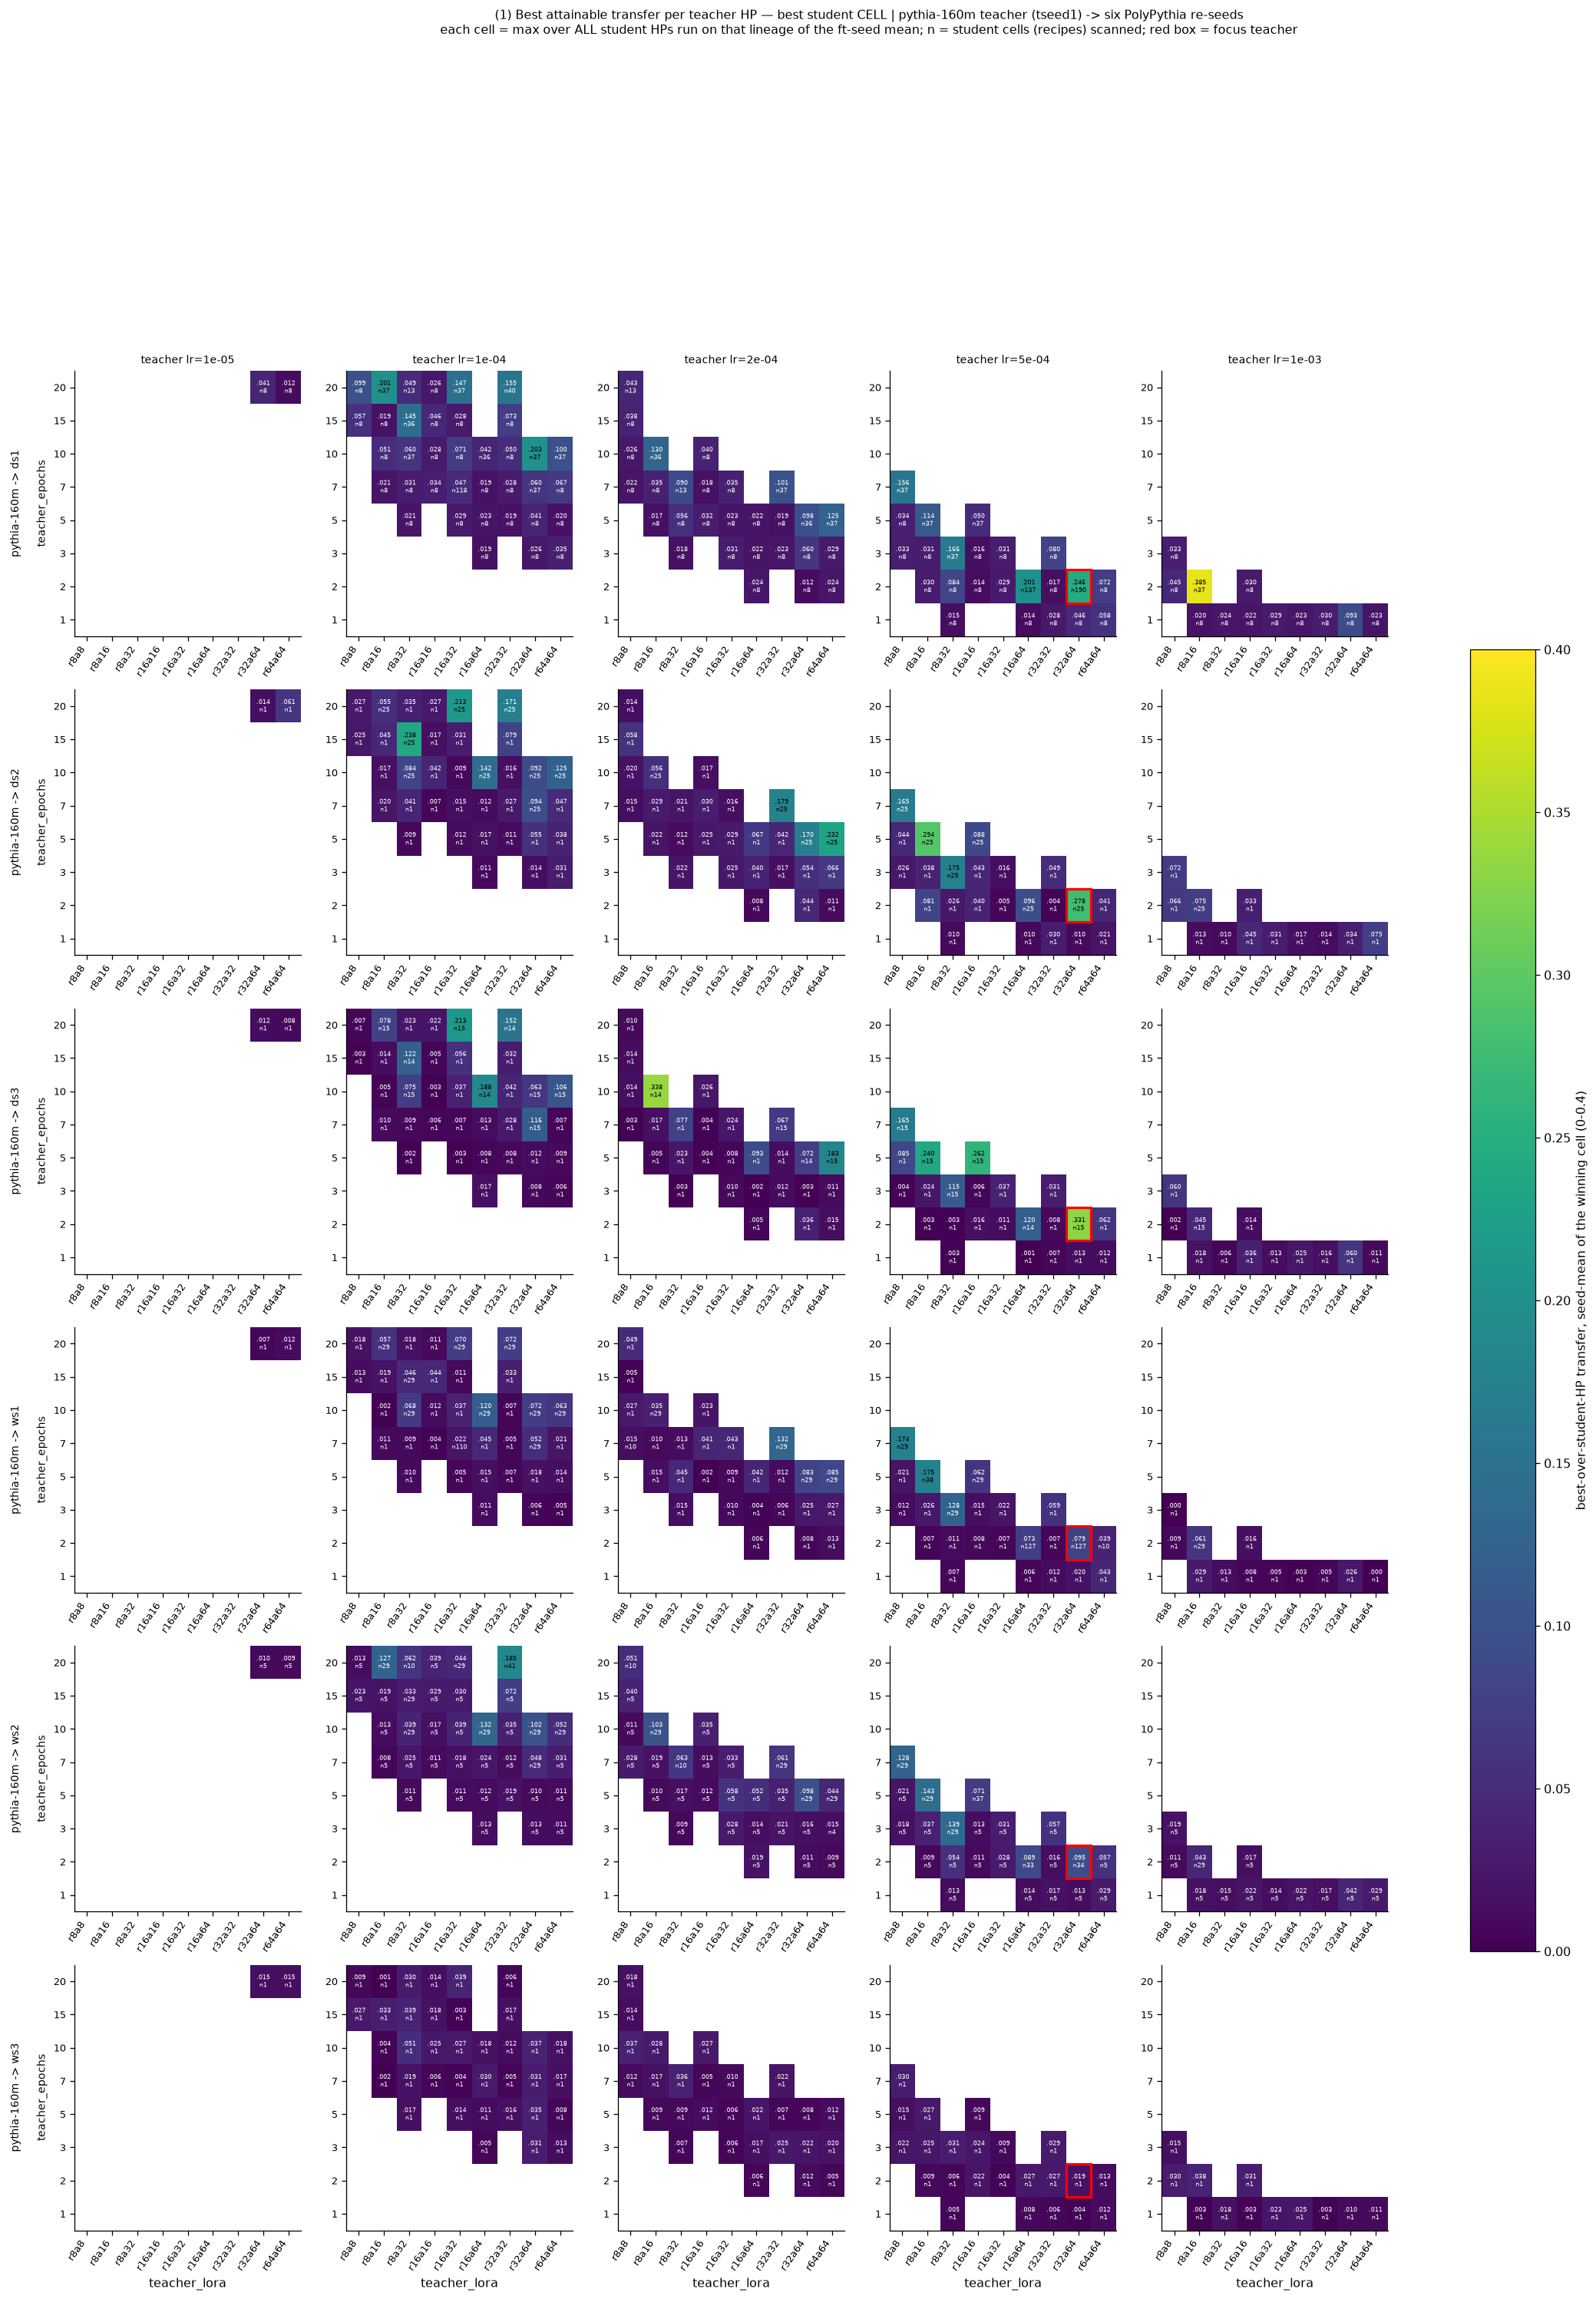

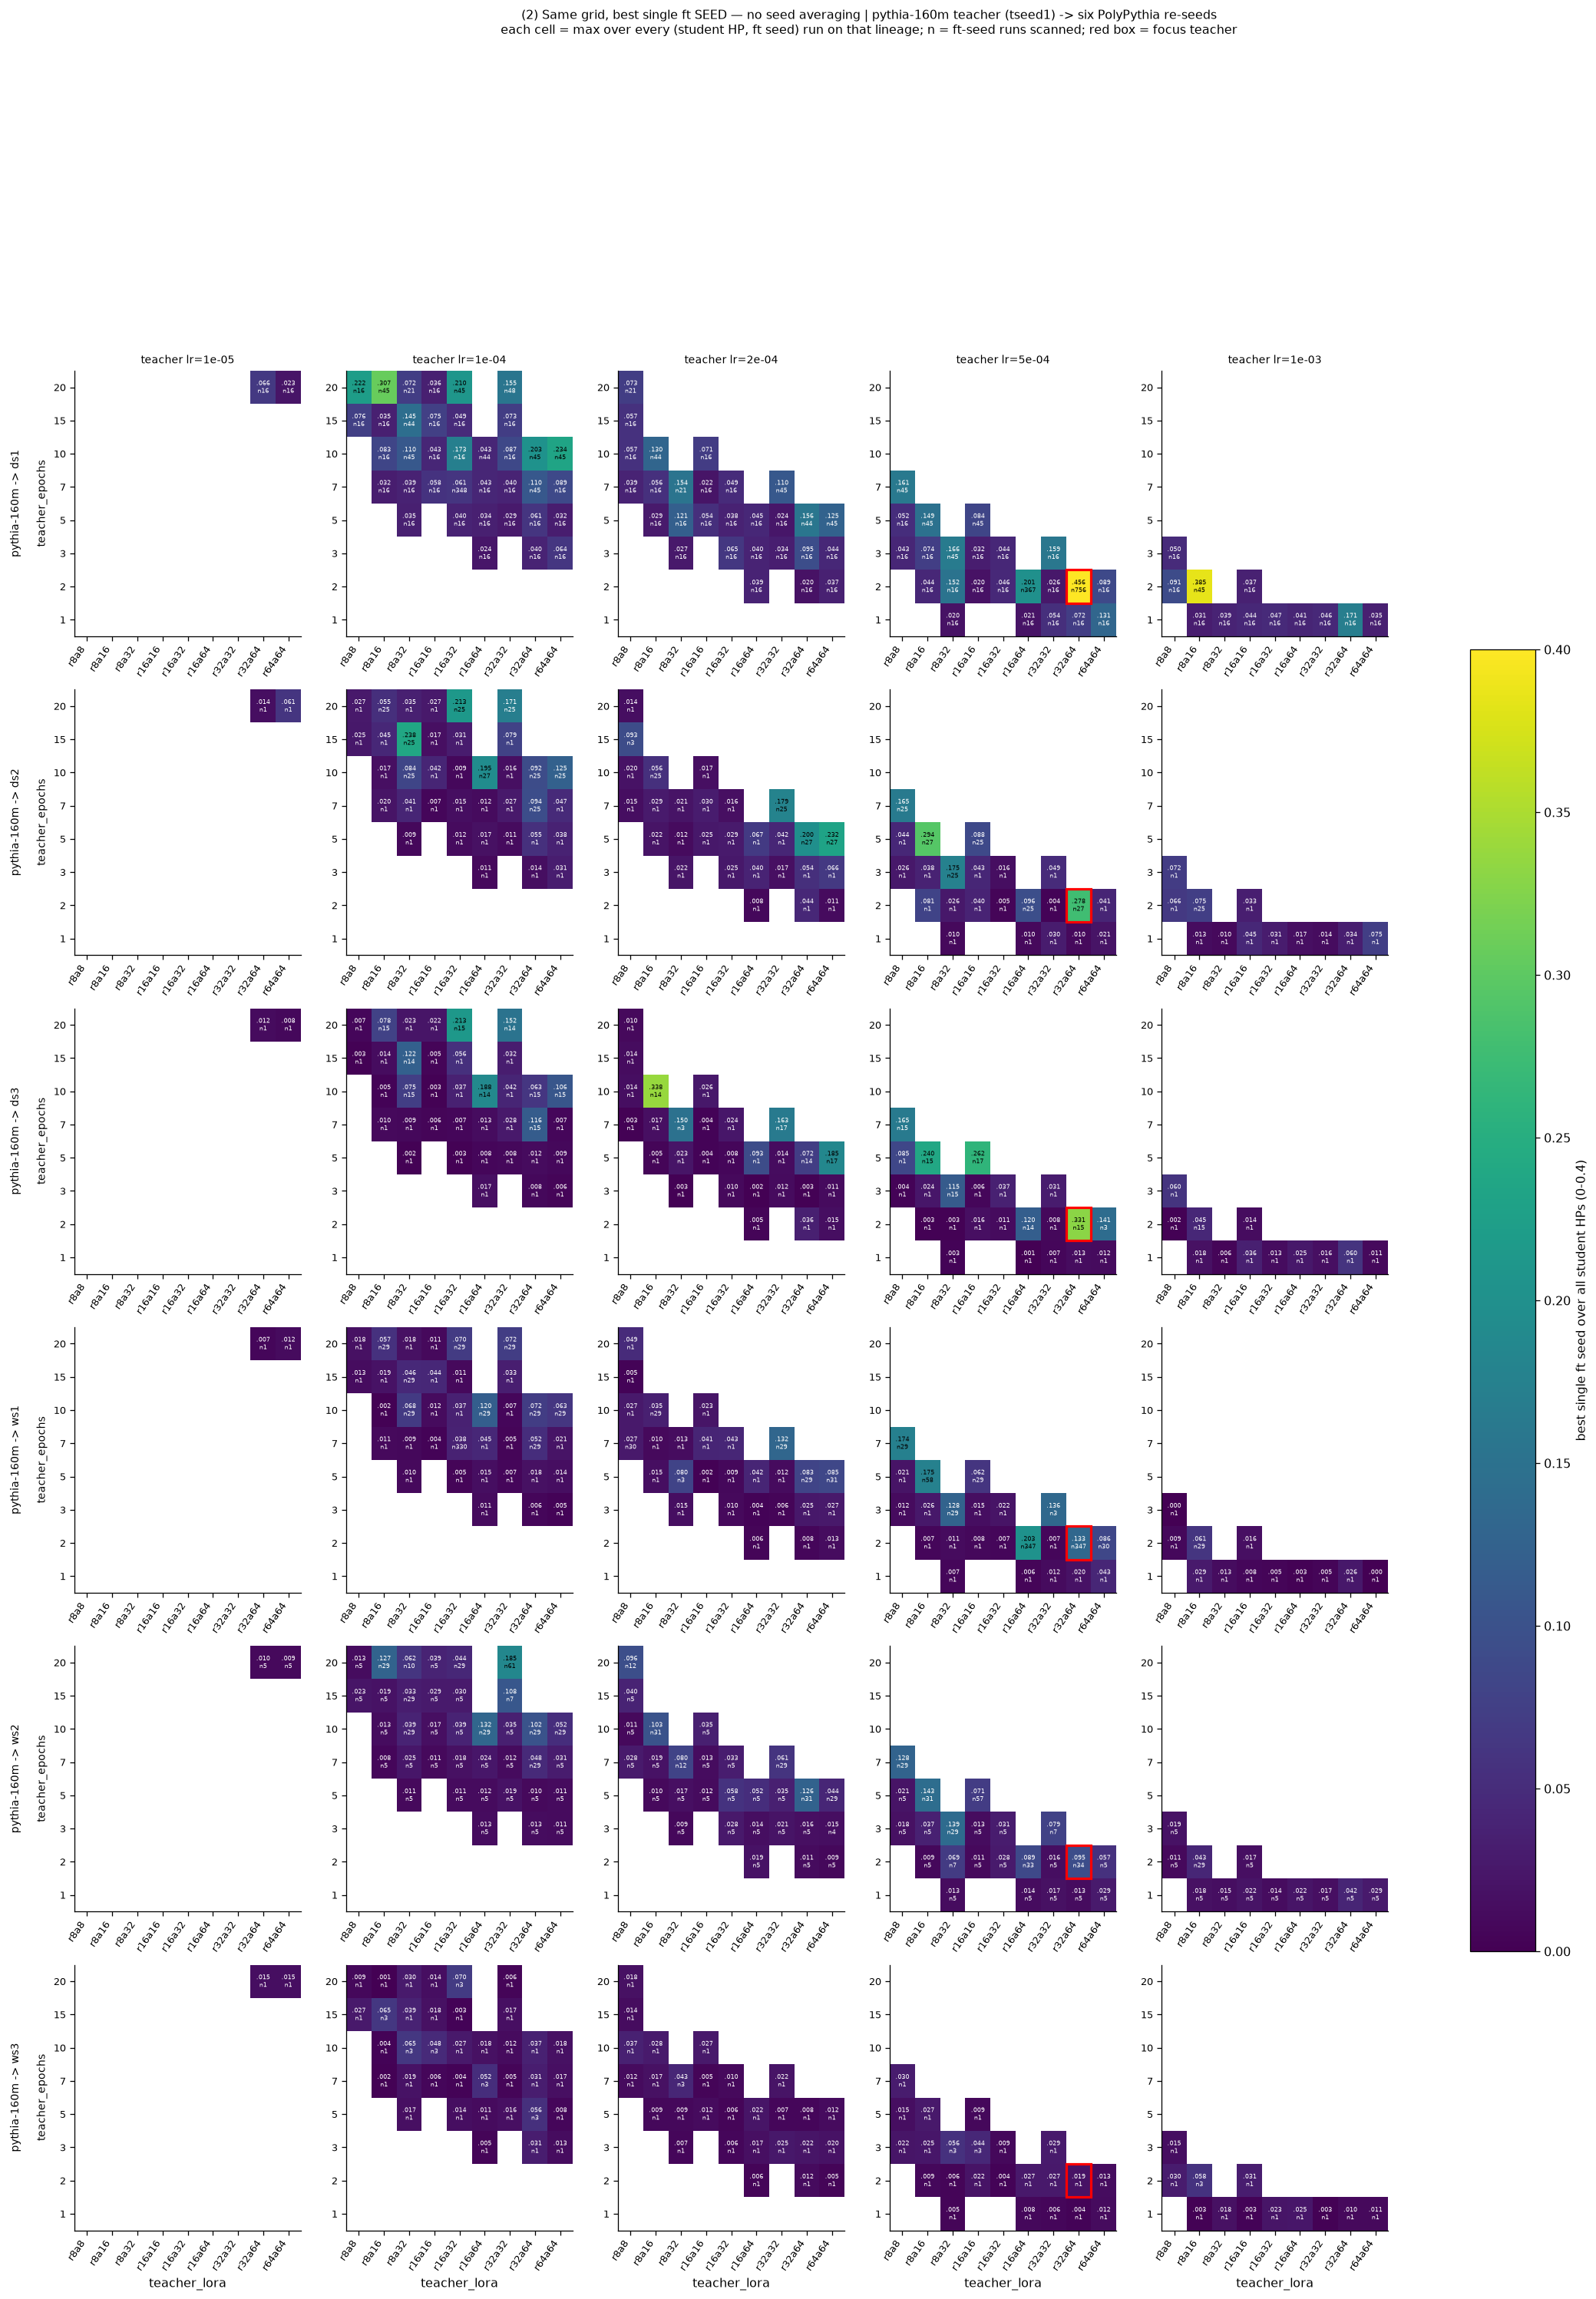

In [2]:
# Two figures, one row of panels per student lineage (ds1-3, ws1-3), in the usual teacher-HP grid
# (y = teacher epochs, x = teacher rank/alpha, one panel per teacher lr). Both take a max over every
# student HP run on that lineage x teacher; they differ in what is maximised, and `n` matches:
#   (1) max over student CELLS of the ft-seed mean  -> n = student cells (recipes) scanned
#   (2) max over individual ft SEEDS                -> n = ft-seed runs scanned
# Explode each cell into `n` identical rows so `show_n` prints that count while the mean stays the max.
loras15 = sorted(best15.teacher_lora.unique(), key=lambda x: tuple(map(int, re.findall(r"\d+", x))))
FOCUS_HL15 = [dict(teacher_lr=5e-4, teacher_epochs=2, teacher_lora="r32a64", color="red", lw=2.0)]
GRID15 = dict(row="teacher_epochs", col="teacher_lora", row_facet="base", col_facet="teacher_lr",
              agg="mean", show_n=True, orders={"teacher_lora": loras15, "base": LIN_ORDER},
              vmin=0, vmax=0.4, cmap="viridis", fmt=lambda v: f"{v:.3f}"[1:], highlight=FOCUS_HL15,
              panel_w=4.6, row_h=0.52, cell_fontsize=5.2,
              row_facet_label=lambda v: f"pythia-160m -> {v}",
              col_facet_label=lambda lr: f"teacher lr={lr:.0e}")

_ = aplots.facet_grid_heatmaps(
    best15.loc[best15.index.repeat(best15.n_hps_scanned)], val="best_cell_mean", **GRID15,
    cbar_label="best-over-student-HP transfer, seed-mean of the winning cell (0-0.4)",
    title="(1) Best attainable transfer per teacher HP — best student CELL | pythia-160m teacher (tseed1) -> six PolyPythia re-seeds\n"
          "each cell = max over ALL student HPs run on that lineage of the ft-seed mean; n = student cells (recipes) scanned; "
          "red box = focus teacher")

_ = aplots.facet_grid_heatmaps(
    best15.loc[best15.index.repeat(best15.n_seeds_scanned)], val="best_seed_val", **GRID15,
    cbar_label="best single ft seed over all student HPs (0-0.4)",
    title="(2) Same grid, best single ft SEED — no seed averaging | pythia-160m teacher (tseed1) -> six PolyPythia re-seeds\n"
          "each cell = max over every (student HP, ft seed) run on that lineage; n = ft-seed runs scanned; "
          "red box = focus teacher")
plt.show()


In [3]:
# Lookup table, trimmed to the TOP 5 teacher configs per student base (ranked by best-cell mean —
# the quantity figure (1) plots). For each: which student recipe wins, on both criteria —
#   best-cell = student HP with the best ft-seed MEAN (value = that mean, n = its seed count)
#   best-seed = student HP holding the single best ft seed (value = that seed; what figure (2) plots)
# `top5 by cell` / `top5 by seed` list that lineage x teacher's runner-up recipes as `hp(value)`;
# a single entry means only one recipe was ever run there (ws3 throughout, most ds2/ds3 teachers).
TOP_N_TEACHERS = 5


def _top5(g, key):
    s = g.sort_values(key, ascending=False).head(5)
    return " | ".join(f"{t}({v:.3f})" for t, v in zip(s.student_tag, s[key]))


tops = (cells15.groupby(["base", "teacher_tag"])
        .apply(lambda g: pd.Series({"top5 by cell": _top5(g, "cell_mean"),
                                    "top5 by seed": _top5(g, "cell_best_seed")}), include_groups=False)
        .reset_index())

lookup15 = (best15.merge(tops, on=["base", "teacher_tag"])
            .sort_values(["base", "best_cell_mean"], ascending=[True, False])
            .groupby("base", observed=True).head(TOP_N_TEACHERS)
            .rename(columns={"base": "lineage", "teacher_tag": "teacher HP set",
                             "best_cell_hp": "best-cell student HP", "best_cell_mean": "best-cell mean",
                             "best_cell_n_seeds": "n(best cell)", "best_seed_hp": "best-seed student HP",
                             "best_seed_val": "best-seed value", "n_hps_scanned": "HPs scanned",
                             "n_seeds_scanned": "seeds scanned"})
            [["lineage", "teacher HP set", "best-cell student HP", "best-cell mean", "n(best cell)",
              "best-seed student HP", "best-seed value", "HPs scanned", "seeds scanned",
              "top5 by cell", "top5 by seed"]].reset_index(drop=True))

with pd.option_context("display.max_colwidth", 200):
    display(lookup15.style.hide(axis="index")
            .format({"best-seed value": "{:.4f}", "best-cell mean": "{:.4f}"})
            .background_gradient(subset=["best-cell mean"], cmap="viridis", vmin=0, vmax=0.4)
            .set_caption(f"Top {TOP_N_TEACHERS} teacher HP sets per lineage (by best-cell mean) "
                         "— and the student HP that gets there"))


lineage,teacher HP set,best-cell student HP,best-cell mean,n(best cell),best-seed student HP,best-seed value,HPs scanned,seeds scanned,top5 by cell,top5 by seed
ds1,ep2_lr1e-3_r8a16,ep20_lr1e-4_r64a64,0.3845,1,ep20_lr1e-4_r64a64,0.3845,37,45,ep20_lr1e-4_r64a64(0.385) | ep20_lr1e-4_r64a32(0.218) | ep20_lr8e-5_r32a32(0.119) | ep20_lr3e-4_r32a4(0.107) | ep20_lr8e-5_r16a64(0.091),ep20_lr1e-4_r64a64(0.385) | ep20_lr1e-4_r64a32(0.218) | ep20_lr8e-5_r32a32(0.119) | ep20_lr3e-4_r32a4(0.107) | ep20_lr8e-5_r16a64(0.091)
ds1,ep2_lr5e-4_r32a64,ep20_lr4e-4_r32a4,0.2459,5,ep20_lr4e-4_r32a4,0.4564,190,756,ep20_lr4e-4_r32a4(0.246) | ep20_lr4e-4_r16a4(0.172) | ep20_lr2.1e-4_r32a8(0.165) | ep20_lr3e-4_r16a8(0.148) | ep20_lr8e-5_r32a64(0.145),ep20_lr4e-4_r32a4(0.456) | ep20_lr4e-4_r16a4(0.346) | ep20_lr1e-4_r16a16(0.300) | ep20_lr4e-4_r8a4(0.256) | ep20_lr2e-4_r4a16(0.250)
ds1,ep10_lr1e-4_r32a64,ep20_lr3e-4_r32a4,0.2034,1,ep20_lr3e-4_r32a4,0.2034,37,45,ep20_lr3e-4_r32a4(0.203) | ep20_lr2.2e-4_r64a8(0.164) | ep20_lr1e-4_r64a64(0.135) | ep20_lr5e-5_r16a64(0.107) | ep20_lr4e-4_r8a2(0.095),ep20_lr3e-4_r32a4(0.203) | ep20_lr2.2e-4_r64a8(0.164) | ep20_lr1e-4_r64a64(0.135) | ep20_lr4e-4_r16a4(0.135) | ep20_lr1e-4_r8a32(0.118)
ds1,ep20_lr1e-4_r8a16,ep20_lr1e-4_r64a64,0.2013,1,ep20_lr4e-4_r32a4,0.3071,37,45,ep20_lr1e-4_r64a64(0.201) | ep20_lr4e-4_r32a4(0.120) | ep20_lr4.5e-4_r32a2(0.093) | ep20_lr5e-5_r16a64(0.084) | ep20_lr3e-4_r32a4(0.084),ep20_lr4e-4_r32a4(0.307) | ep20_lr4e-4_r16a4(0.205) | ep20_lr1e-4_r64a64(0.201) | ep20_lr4.5e-4_r32a2(0.093) | ep20_lr3e-4_r16a8(0.086)
ds1,ep2_lr5e-4_r16a64,ep20_lr8e-5_r32a64,0.2009,1,ep20_lr8e-5_r32a64,0.2009,137,367,ep20_lr8e-5_r32a64(0.201) | ep20_lr5e-4_r16a2(0.086) | ep20_lr1e-4_r8a32(0.084) | ep20_lr3e-4_r32a4(0.070) | ep20_lr1e-4_r16a16(0.066),ep20_lr8e-5_r32a64(0.201) | ep20_lr5e-4_r16a2(0.192) | ep20_lr1e-4_r8a64(0.145) | ep20_lr1e-4_r8a32(0.133) | ep20_lr1e-4_r64a64(0.126)
ds2,ep5_lr5e-4_r8a16,ep20_lr4e-4_r8a2,0.2939,1,ep20_lr4e-4_r8a2,0.2939,25,27,ep20_lr4e-4_r8a2(0.294) | ep20_lr8e-5_r32a32(0.191) | ep20_lr4e-4_r8a4(0.180) | ep20_lr8e-5_r4a32(0.147) | ep20_lr2e-4_r8a2(0.133),ep20_lr4e-4_r8a2(0.294) | ep20_lr8e-5_r32a32(0.191) | ep20_lr4e-4_r8a4(0.180) | ep20_lr1e-4_r8a32(0.152) | ep20_lr8e-5_r4a32(0.147)
ds2,ep2_lr5e-4_r32a64,ep20_lr8e-5_r8a64,0.2777,1,ep20_lr8e-5_r8a64,0.2777,25,27,ep20_lr8e-5_r8a64(0.278) | ep20_lr4e-4_r8a2(0.205) | ep20_lr8e-5_r4a32(0.191) | ep20_lr1e-4_r8a32(0.188) | ep20_lr5e-5_r16a64(0.169),ep20_lr8e-5_r8a64(0.278) | ep20_lr4e-4_r8a2(0.205) | ep20_lr1e-4_r8a32(0.191) | ep20_lr8e-5_r4a32(0.191) | ep20_lr5e-5_r16a64(0.169)
ds2,ep15_lr1e-4_r8a32,ep20_lr8e-5_r4a64,0.2383,1,ep20_lr8e-5_r4a64,0.2383,25,25,ep20_lr8e-5_r4a64(0.238) | ep20_lr8e-5_r4a32(0.121) | ep20_lr8e-5_r4a8(0.073) | ep20_lr8e-5_r64a16(0.057) | ep20_lr2e-4_r8a2(0.055),ep20_lr8e-5_r4a64(0.238) | ep20_lr8e-5_r4a32(0.121) | ep20_lr8e-5_r4a8(0.073) | ep20_lr8e-5_r64a16(0.057) | ep20_lr2e-4_r8a2(0.055)
ds2,ep5_lr2e-4_r64a64,ep20_lr1e-4_r64a32,0.2317,1,ep20_lr1e-4_r64a32,0.2317,25,27,ep20_lr1e-4_r64a32(0.232) | ep20_lr1e-4_r8a32(0.169) | ep20_lr8e-5_r4a32(0.131) | ep20_lr5e-5_r16a64(0.124) | ep20_lr4e-4_r8a2(0.076),ep20_lr1e-4_r64a32(0.232) | ep20_lr1e-4_r8a32(0.179) | ep20_lr8e-5_r4a32(0.131) | ep20_lr5e-5_r16a64(0.124) | ep20_lr4e-4_r8a2(0.076)
ds2,ep20_lr1e-4_r16a32,ep20_lr4e-4_r8a2,0.2130,1,ep20_lr4e-4_r8a2,0.2130,25,25,ep20_lr4e-4_r8a2(0.213) | ep20_lr8e-5_r32a32(0.138) | ep20_lr8e-5_r32a64(0.122) | ep20_lr1e-4_r64a64(0.087) | ep20_lr5e-5_r16a64(0.072),ep20_lr4e-4_r8a2(0.213) | ep20_lr8e-5_r32a32(0.138) | ep20_lr8e-5_r32a64(0.122) | ep20_lr1e-4_r64a64(0.087) | ep20_lr5e-5_r16a64(0.072)
